# Manila - Jeepney Route Connection and Genetic Algorithm

## Route Connection and Genetic Algorithm Functions

### Setting Up

In [55]:
from __future__ import absolute_import, division

import time
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import networkx as nx
import shapely
import folium
import geojson
import math
import osmnx as ox
from rtree import index as rtree_index
import pickle
import copy
import utm
from pyproj import Transformer
from shapely.ops import transform

from shapely.ops import unary_union
from shapely.geometry import Polygon, MultiPolygon, LineString, Point
from geopy.distance import geodesic
from shapely.ops import split, substring

from math import radians, sin, cos, sqrt, atan2, exp, log
import webbrowser
import random
from scipy.spatial import KDTree
from scipy.special import expit
from functools import lru_cache


ox.settings.log_console=True
ox.settings.use_cache=True

WALKING_DISTANCES = [300,550,800]
MAX_DISTANCE = 15
CONNECTION_TYPES = ["Default", "Area", "Degree", "Mixed"]
# Connectivity metric configuration
MIN_INTERMODAL_STOPS_PER_ROUTE = 3
# Transportation-POI preprocessing
TRANSPORT_POI_DEDUP_DISTANCE_M = 20.0
# Prevent effectively coincident intermodal stops from being created on the same road edge.
TRANSPORT_STOP_MIN_SEPARATION_M = 5.0
# Population-demand normalization
POPULATION_DENOMINATOR_PERCENTILE = 95


# ---------------------------------------------------
# Headway-efficiency configuration
# ---------------------------------------------------

# Universal target headway:
# 6 minutes = 360 seconds
HEADWAY_TARGET_SECONDS = 360.0

# Manila 2025 congestion level:
# congested travel time = 1.57 * free-flow travel time
HEADWAY_CONGESTION_FACTOR = 0.57

# Planning-level dwell-time proxy:
# d_n = delta + lambda * ((P_n + T_n) / 2)
HEADWAY_DWELL_MIN_SECONDS = 20.0
HEADWAY_DWELL_ADDITIONAL_SECONDS = 40.0

# Sigmoid normalization parameters.
# These will be calibrated once from the
# 100 initial candidate networks.

HEADWAY_BASELINE_MEAN_MANILA = None
HEADWAY_BASELINE_STD_MANILA = None

# Initial route-network configuration
INITIAL_CONN_TYPE = CONNECTION_TYPES[3]  # Mixed
INITIAL_WALK_DISTANCE = WALKING_DISTANCES[1]
INITIAL_NETWORK_COUNT = 100

In [56]:
# For reproducibility. Makes any random sampling deterministic.
SEED = 42 # You can change this value to any integer depending on the run
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); 
np.random.seed(SEED)

In [57]:
def _pct_tag(w):
    """
    Convert weight (0.6) -> '60', (0.02) -> '02', (1.0) -> '100'
    Assumes weights are in [0,1].
    """
    return f"{int(round(w * 100)):02d}"  # 0.1->10, 0.05->05


def make_run_tag(
    w_cov,
    w_conn,
    w_target,
    w_random,
    w_flood,
    w_headway
):
    return (
        f"cov{_pct_tag(w_cov)}"
        f"_k{_pct_tag(w_conn)}"
        f"_t{_pct_tag(w_target)}"
        f"_r{_pct_tag(w_random)}"
        f"_b{_pct_tag(w_flood)}"
        f"_h{_pct_tag(w_headway)}"
    )
    
    
def manila_initial_network_filepath(
    conn_type=INITIAL_CONN_TYPE,
    walk_distance=INITIAL_WALK_DISTANCE
):
    if conn_type == "Mixed":
        filename = (
            f"Manila_Route_networks_"
            f"{conn_type}.pkl"
        )
    else:
        filename = (
            f"Manila_Route_networks_"
            f"{conn_type}_W{walk_distance}.pkl"
        )

    return f"{Manila_pikl_filepath}{filename}"

In [58]:
# Defining classes for the dataframes      
class stopCandidate:
    def __init__(
        self,
        lat,
        long,
        isTranspo,
        id,
        area,
        zone_ids=None,
        source_edge_id=None,
        transport_name=None,
        transport_source_id=None,
        raw_transport_source_ids=None,
        raw_transport_poi_count=0
    ):
        self.lat = lat
        self.long = long
        self.isTranspo = isTranspo
        self.enabled = False
        self.id = id
        self.area = area

        # Spatial provenance
        self.zone_ids = (
            list(zone_ids)
            if zone_ids
            else []
        )

        self.source_edge_id = (
            source_edge_id
        )

        # Transportation-source provenance
        self.transport_name = (
            transport_name
        )

        self.transport_source_id = (
            transport_source_id
        )

        self.raw_transport_source_ids = (
            list(raw_transport_source_ids)
            if raw_transport_source_ids
            else []
        )

        self.raw_transport_poi_count = int(
            raw_transport_poi_count
        )

        # Population-demand attributes
        self.population_raw = 0.0
        self.population_score = 0.0

        # T_n
        self.intermodal_indicator = (
            1 if isTranspo else 0
        )

        # Flood attributes
        self.flood_5 = 0
        self.flood_25 = 0
        self.flood_100 = 0
        self.flood_score = 0.0

    def enable(self):
        self.enabled = True

    def disable(self):
        self.enabled = False

    def getLat(self):
        return self.lat

    def getLong(self):
        return self.long

    def getArea(self):
        return self.area
    
class networkObj:
    def __init__(self, routes, reversed_routes, stops, reversed_stops, graph, conn_type, walk_distance):
        self.routes = routes
        self.reversed_routes = reversed_routes
        self.stops = stops
        self.reversed_stops = reversed_stops
        self.fitness_score = 0
        self.graph = graph
        self.conn_type = conn_type
        self.walk_distance = walk_distance
        self.fitness_score_components = {}
        
class Route:
    def __init__(self, route, route_id, length):
        self.route = route
        self.route_id = route_id
        self.length = length
        self.reverse = None

In [59]:
# Import and Export networks or graphs to pickle
def export_networks(networks, path):
    dir_ = os.path.dirname(path)
    if dir_:
        os.makedirs(dir_, exist_ok=True)

    temp_path = path + ".tmp"

    with open(temp_path, 'wb') as f:
        pickle.dump(networks, f)
        f.flush()
        os.fsync(f.fileno())

    if not os.path.exists(temp_path):
        raise FileNotFoundError(f"Temporary checkpoint file was not created: {temp_path}")

    if os.path.exists(path):
        os.remove(path)

    os.rename(temp_path, path)

def import_networks(path):
    with open(path, 'rb') as f:
        routes = pickle.load(f)
    return routes

#### Metric-Geometry

In [60]:
# Coordinate reference systems
WGS84_CRS = "EPSG:4326"
METRIC_CRS = "EPSG:32651"  # WGS 84 / UTM Zone 51N

# Reusable coordinate transformers
TO_METRIC = Transformer.from_crs(
    WGS84_CRS,
    METRIC_CRS,
    always_xy=True
).transform

TO_WGS84 = Transformer.from_crs(
    METRIC_CRS,
    WGS84_CRS,
    always_xy=True
).transform


def to_metric_geometry(geometry):
    """
    Convert a WGS84 geometry to UTM Zone 51N.
    Coordinates in the returned geometry are in meters.
    """
    return transform(TO_METRIC, geometry)


def to_wgs84_geometry(geometry):
    """
    Convert a UTM Zone 51N geometry back to WGS84.
    """
    return transform(TO_WGS84, geometry)


def geometry_area_m2(geometry):
    """
    Return polygon area in square meters.
    """
    return to_metric_geometry(geometry).area


def geometry_perimeter_m(geometry):
    """
    Return geometry length/perimeter in meters.
    """
    return to_metric_geometry(geometry).length


def geometry_distance_m(geometry1, geometry2):
    """
    Return minimum distance between two geometries in meters.
    """
    geom1_metric = to_metric_geometry(geometry1)
    geom2_metric = to_metric_geometry(geometry2)

    return geom1_metric.distance(geom2_metric)


def buffer_geometry_m(geometry, distance_m):
    """
    Create a buffer of the specified number of meters while returning
    the resulting geometry in WGS84.
    """
    metric_geometry = to_metric_geometry(geometry)
    metric_buffer = metric_geometry.buffer(distance_m)

    return to_wgs84_geometry(metric_buffer)

#### Graph and Features

In [61]:
# NOTE: SELECT THE CITY HERE, COMMENT OUT THE REMAINING CITIES
select_city = "Manila, Philippines"
city_file = 'map/Manila.graphml'


# GENERATION OF MAIN CITY GRAPH
# IF FIRST TIME RUNNING, RUN THIS CODE TO GENERATE THE GRAPH
def generate_graph():
    mode = 'drive'
    graph = ox.graph_from_place(select_city, network_type = mode) # Generate graph of Metro manila
    ox.save_graphml(graph, city_file) # Save it as a file

def load_graph():
    graph = ox.load_graphml(city_file)
    
    print("Graph loaded successfully")
    print("NUMBER OF EDGES: ", graph.number_of_edges())
    print("NUMBER OF NODES: ", graph.number_of_nodes())
    print('\n')
    return graph

if not os.path.exists(city_file):
    generate_graph()

# THIS IS THE MAIN GRAPH FOR THE CITY TO BE USED FOR ALL FUNCTIONS
CITY_GRAPH = load_graph()

# Iterate over the edges and assign a unique edge_id
edge_id = 0
for u, v, k in CITY_GRAPH.edges(keys=True):
    CITY_GRAPH[u][v][k]['edge_id'] = edge_id
    edge_id += 1

Graph loaded successfully
NUMBER OF EDGES:  12739
NUMBER OF NODES:  5062




In [62]:
### For Filtering the roads and other features
# GETTING ROADS AND WATERWAYS

# Get all the roads in Manila
road = ox.graph_to_gdfs(CITY_GRAPH, nodes=False, edges=True)

EDGE_GEOMETRY_BY_ID = {
    int(row["edge_id"]): row["geometry"]
    for _, row in road.iterrows()
    if pd.notna(row.get("edge_id"))
}

# Get all the roads that are not junctions (ex. Roundabouts, intersection, etc.)
filtered_roads = road[road['junction'].isna()]

# Separate roads whose highway types are only one value and those that are more than 1 (lists)
rows_with_lists = filtered_roads[filtered_roads['highway'].apply(lambda x: isinstance(x, list))]
rows_with_strings = filtered_roads[filtered_roads['highway'].apply(lambda x: isinstance(x, str))]

# Allowed Roads to place stops
filter_options = ['primary', 'secondary', 'tertiary', 'trunk']

# To separate zones
separation_options = ['primary', 'secondary', 'tertiary', 'unclassified']

# Get the roads whose widths are above the threshold
def check_list(lst):
    return any(x in filter_options for x in lst)

# Download OpenStreetMap data for the area of interest
waterways = ox.features_from_place(select_city, tags={'waterway': True})
filtered_rivers = waterways[waterways['waterway'].isin(['river'])]
filtered_streams = waterways[waterways['waterway'].isin(['stream'])]

# Get all the roads with the allowed road types
filtered_roads_strings = rows_with_strings.loc[rows_with_strings['highway'].isin(filter_options)] 
filtered_roads_lists = rows_with_lists[rows_with_lists['highway'].apply(check_list)]

# Create spatial index
filtered_roads_strings_sindex = filtered_roads_strings.sindex
filtered_roads_lists_sindex = filtered_roads_lists.sindex
filtered_rivers_sindex = filtered_rivers.sindex
filtered_streams_sindex = filtered_streams.sindex

In [63]:
# This function will find which road or river intersects between amenities

def find_intersecting_features(line):
    # Check intersection with filtered roads
    possible_matches_roads = filtered_roads_strings.iloc[list(filtered_roads_strings_sindex.intersection(line.bounds))]
    for index, row in possible_matches_roads.iterrows():
        if line.intersects(row['geometry']) and row['highway'] in separation_options:
            return True

    possible_matches_lists = filtered_roads_lists.iloc[list(filtered_roads_lists_sindex.intersection(line.bounds))]
    for index, row in possible_matches_lists.iterrows():
        if line.intersects(row['geometry']):
            list_highway = row['highway']
            if any(x in separation_options for x in list_highway):
                return True
    
    # Check intersection with filtered rivers
    possible_matches_rivers = filtered_rivers.iloc[list(filtered_rivers_sindex.intersection(line.bounds))]
    for index, row in possible_matches_rivers.iterrows():
        if line.intersects(row['geometry']):
            return True

    # Check intersection with filtered streams
    possible_matches_streams = filtered_streams.iloc[list(filtered_streams_sindex.intersection(line.bounds))]
    for index, row in possible_matches_streams.iterrows():
        if line.intersects(row['geometry']):
            return True
    
    return False

In [64]:
# ---------------------------------------------------
# Opposite-direction partner-edge identification
# ---------------------------------------------------

PARTNER_EDGE_MAX_DISTANCE_M = 50
PARTNER_DIRECTION_COS_THRESHOLD = -0.5


def is_oneway_value(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    return str(value).strip().lower() in {
        "true",
        "yes",
        "1"
    }


def highway_is_eligible(value):
    if isinstance(
        value,
        (list, tuple, set, np.ndarray)
    ):
        return any(
            highway in filter_options
            for highway in value
        )

    return value in filter_options


# ---------------------------------------------------
# Coverage: eligible directed road network
# ---------------------------------------------------

# Select all original directed road edges whose
# highway classification includes primary,
# secondary, tertiary, or trunk.
#
# Use the complete road GeoDataFrame so that:
# - junction-tagged edges are included;
# - string-valued classifications are included;
# - list-valued classifications are included.

COVERAGE_ELIGIBLE_ROADS = road.loc[
    road["highway"].apply(highway_is_eligible)
].copy()

if COVERAGE_ELIGIBLE_ROADS.empty:
    raise ValueError(
        "No eligible road edges found for coverage."
    )

# Each eligible original edge must have a unique ID.
if COVERAGE_ELIGIBLE_ROADS["edge_id"].isna().any():
    raise ValueError(
        "An eligible coverage edge has no edge_id."
    )

COVERAGE_DENOMINATOR_EDGE_IDS = {
    int(edge_id)
    for edge_id in COVERAGE_ELIGIBLE_ROADS["edge_id"]
}

if (
    len(COVERAGE_DENOMINATOR_EDGE_IDS)
    != len(COVERAGE_ELIGIBLE_ROADS)
):
    raise ValueError(
        "Duplicate original edge IDs in coverage dataset."
    )

coverage_lengths = pd.to_numeric(
    COVERAGE_ELIGIBLE_ROADS["length"],
    errors="raise"
)

if (
    not np.all(np.isfinite(coverage_lengths))
    or (coverage_lengths < 0).any()
):
    raise ValueError(
        "Invalid eligible road lengths."
    )

TOTAL_NETWORK_ROAD_DISTANCE = float(
    coverage_lengths.sum()
)

if TOTAL_NETWORK_ROAD_DISTANCE <= 0:
    raise ValueError(
        "Total eligible road length must be positive."
    )

print("--- COVERAGE REFERENCE NETWORK ---")

print(
    "Eligible directed road edges:",
    len(COVERAGE_ELIGIBLE_ROADS)
)

print(
    "Eligible junction-tagged edges:",
    COVERAGE_ELIGIBLE_ROADS["junction"].notna().sum()
)

print(
    "Eligible list-valued edges:",
    COVERAGE_ELIGIBLE_ROADS["highway"].apply(
        lambda value: isinstance(value, list)
    ).sum()
)

print(
    "Total eligible directed road length (km):",
    TOTAL_NETWORK_ROAD_DISTANCE / 1000.0
)


def normalize_road_names(value):
    if isinstance(
        value,
        (list, tuple, set, np.ndarray)
    ):
        return {
            str(name).strip().lower()
            for name in value
            if name is not None
        }

    if value is None:
        return set()

    try:
        if pd.isna(value):
            return set()
    except (TypeError, ValueError):
        pass

    return {
        str(value).strip().lower()
    }


def get_original_edge_geometry(
    edge_index,
    edge_data
):
    geometry = edge_data.get("geometry")

    if (
        geometry is not None
        and not geometry.is_empty
    ):
        return geometry

    u, v, _ = edge_index

    return LineString([
        (
            CITY_GRAPH.nodes[u]["x"],
            CITY_GRAPH.nodes[u]["y"]
        ),
        (
            CITY_GRAPH.nodes[v]["x"],
            CITY_GRAPH.nodes[v]["y"]
        )
    ])


def get_edge_direction_vector(
    geometry
):
    metric_geometry = to_metric_geometry(
        geometry
    )

    if metric_geometry.geom_type != "LineString":
        return None

    coordinates = list(
        metric_geometry.coords
    )

    if len(coordinates) < 2:
        return None

    x1, y1 = coordinates[0]
    x2, y2 = coordinates[-1]

    dx = x2 - x1
    dy = y2 - y1

    magnitude = math.hypot(
        dx,
        dy
    )

    if magnitude == 0:
        return None

    return (
        dx / magnitude,
        dy / magnitude
    )


def build_partner_edge_map(
    road_gdf,
    max_distance_m=PARTNER_EDGE_MAX_DISTANCE_M,
    direction_cos_threshold=PARTNER_DIRECTION_COS_THRESHOLD
):
    """
    Identify paired one-way road edges representing opposite
    directions of the same road.

    Candidate pairs must:
      - be eligible road classes,
      - both be one-way,
      - share a road name,
      - be geographically close,
      - and point in substantially opposite directions.

    Only mutual best matches are retained.
    """

    eligible_oneway = road_gdf[
        road_gdf["highway"].apply(
            highway_is_eligible
        )
        & road_gdf["oneway"].apply(
            is_oneway_value
        )
    ].copy()

    spatial_index = (
        eligible_oneway.sindex
    )

    best_partner = {}

    for edge_index, edge_data in (
        eligible_oneway.iterrows()
    ):
        edge_id = int(
            edge_data["edge_id"]
        )

        road_names = normalize_road_names(
            edge_data.get("name")
        )

        if not road_names:
            continue

        geometry = get_original_edge_geometry(
            edge_index,
            edge_data
        )

        metric_geometry = (
            to_metric_geometry(
                geometry
            )
        )

        direction = (
            get_edge_direction_vector(
                geometry
            )
        )

        if direction is None:
            continue

        search_area = buffer_geometry_m(
            geometry,
            max_distance_m
        )

        best_candidate = None
        best_score = float("inf")

        for pos in spatial_index.intersection(
            search_area.bounds
        ):
            candidate_index = (
                eligible_oneway.index[pos]
            )

            if candidate_index == edge_index:
                continue

            candidate_data = (
                eligible_oneway.iloc[pos]
            )

            candidate_edge_id = int(
                candidate_data["edge_id"]
            )

            if candidate_edge_id == edge_id:
                continue

            candidate_names = (
                normalize_road_names(
                    candidate_data.get(
                        "name"
                    )
                )
            )

            if not (
                road_names
                & candidate_names
            ):
                continue

            candidate_geometry = (
                get_original_edge_geometry(
                    candidate_index,
                    candidate_data
                )
            )

            candidate_metric = (
                to_metric_geometry(
                    candidate_geometry
                )
            )

            distance_m = (
                metric_geometry.distance(
                    candidate_metric
                )
            )

            if distance_m > max_distance_m:
                continue

            candidate_direction = (
                get_edge_direction_vector(
                    candidate_geometry
                )
            )

            if candidate_direction is None:
                continue

            direction_cosine = (
                direction[0]
                * candidate_direction[0]
                + direction[1]
                * candidate_direction[1]
            )

            # Require substantially opposite directions.
            if (
                direction_cosine
                > direction_cos_threshold
            ):
                continue

            midpoint_1 = (
                metric_geometry.interpolate(
                    0.5,
                    normalized=True
                )
            )

            midpoint_2 = (
                candidate_metric.interpolate(
                    0.5,
                    normalized=True
                )
            )

            midpoint_distance = (
                midpoint_1.distance(
                    midpoint_2
                )
            )

            # Prefer both spatially close and longitudinally
            # corresponding road segments.
            score = (
                distance_m
                + 0.25
                * midpoint_distance
            )

            if score < best_score:
                best_score = score
                best_candidate = (
                    candidate_edge_id
                )

        if best_candidate is not None:
            best_partner[
                edge_id
            ] = best_candidate

    # Retain only mutual matches.
    partner_edges = {}

    for edge_id, candidate_id in (
        best_partner.items()
    ):
        if (
            best_partner.get(
                candidate_id
            )
            == edge_id
        ):
            partner_edges[
                edge_id
            ] = candidate_id

    print(
        "Opposite-direction edge pairs:",
        len(partner_edges) // 2
    )

    return partner_edges


partner_edges = build_partner_edge_map(
    filtered_roads
)

--- COVERAGE REFERENCE NETWORK ---
Eligible directed road edges: 4345
Eligible junction-tagged edges: 29
Eligible list-valued edges: 1
Total eligible directed road length (km): 372.43920670656996
Opposite-direction edge pairs: 456


### Stop Placement

In [65]:
# ADD POINTS TO NX GRAPH
# Function to add only transportation points to the networkX graph

def normalize_transport_name(
    value
):
    """
    Normalize transportation names for
    duplicate detection.
    """

    if pd.isna(value):
        return ""

    value = str(
        value
    ).strip().lower()

    if value in {
        "",
        "nan",
        "none",
        "null"
    }:
        return ""

    return " ".join(
        value.split()
    )


def add_points_to_graph(
    graph,
    graph_to_add,
    dedup_distance_m=
        TRANSPORT_POI_DEDUP_DISTANCE_M
):
    """
    Add cleaned transportation points to the
    amenity-zone graph.

    Transportation POIs with the same normalized
    name and located within dedup_distance_m of a
    selected representative are treated as duplicate
    representations of the same local transport
    location.

    Exactly one original POI is retained as the
    representative. Unnamed POIs are not merged
    based on distance alone.
    """

    records = []

    for node_key, node_data in (
        graph.nodes(
            data=True
        )
    ):
        geometry = node_data.get(
            "geometry"
        )

        if (
            geometry is None
            or geometry.geom_type != "Point"
            or node_data.get(
                "amenity"
            ) != "transportation"
        ):
            continue

        metric_point = (
            to_metric_geometry(
                geometry
            )
        )

        records.append({
            "node_key":
                node_key,

            "node_data":
                node_data,

            "geometry":
                geometry,

            "metric_point":
                metric_point,

            "normalized_name":
                normalize_transport_name(
                    node_data.get(
                        "name"
                    )
                )
        })

    # ---------------------------------------------------
    # Group records by normalized name.
    #
    # Unnamed POIs are deliberately kept independent,
    # because spatial proximity by itself is not enough
    # evidence that they represent the same location.
    # ---------------------------------------------------

    records_by_name = {}

    for record in records:

        normalized_name = (
            record[
                "normalized_name"
            ]
        )

        if normalized_name:

            group_key = (
                "named",
                normalized_name
            )

        else:

            group_key = (
                "unnamed",
                str(
                    record[
                        "node_key"
                    ]
                )
            )

        records_by_name.setdefault(
            group_key,
            []
        ).append(
            record
        )

    cleaned_records = []
    duplicate_groups = []

    # ---------------------------------------------------
    # For each name, repeatedly retain the point with
    # the largest local same-name neighborhood.
    #
    # All POIs within 20 m of that representative are
    # absorbed into its duplicate group.
    #
    # This avoids chain-merging widely separated points
    # that merely share the same name.
    # ---------------------------------------------------

    for group_key in sorted(
        records_by_name,
        key=lambda value: (
            value[0],
            value[1]
        )
    ):

        remaining = list(
            records_by_name[
                group_key
            ]
        )

        while remaining:

            candidates = []

            for record in remaining:

                neighbors = [
                    other
                    for other in remaining
                    if (
                        record[
                            "metric_point"
                        ].distance(
                            other[
                                "metric_point"
                            ]
                        )
                        <= dedup_distance_m
                    )
                ]

                candidates.append(
                    (
                        -len(
                            neighbors
                        ),
                        str(
                            record[
                                "node_key"
                            ]
                        ),
                        record,
                        neighbors
                    )
                )

            (
                _,
                _,
                representative,
                cluster
            ) = min(
                candidates,
                key=lambda item: (
                    item[0],
                    item[1]
                )
            )

            raw_source_ids = [
                item[
                    "node_key"
                ]
                for item
                in cluster
            ]

            representative = dict(
                representative
            )

            representative[
                "raw_transport_source_ids"
            ] = raw_source_ids

            representative[
                "raw_transport_poi_count"
            ] = len(
                cluster
            )

            cleaned_records.append(
                representative
            )

            if len(
                cluster
            ) > 1:

                duplicate_groups.append({
                    "normalized_name":
                        representative[
                            "normalized_name"
                        ],

                    "representative_source_id":
                        representative[
                            "node_key"
                        ],

                    "raw_source_ids":
                        raw_source_ids,

                    "raw_poi_count":
                        len(
                            cluster
                        )
                })

            clustered_ids = {
                item[
                    "node_key"
                ]
                for item
                in cluster
            }

            remaining = [
                item
                for item
                in remaining
                if (
                    item[
                        "node_key"
                    ]
                    not in clustered_ids
                )
            ]

    # ---------------------------------------------------
    # Add only cleaned representatives.
    # ---------------------------------------------------

    for record in (
        cleaned_records
    ):

        node_key = (
            record[
                "node_key"
            ]
        )

        node_data = (
            record[
                "node_data"
            ]
        )

        geometry = (
            record[
                "geometry"
            ]
        )

        graph_to_add.add_node(
            node_key,
            geometry=geometry,
            name=node_data.get(
                "name",
                ""
            ),
            y=float(
                geometry.y
            ),
            x=float(
                geometry.x
            ),
            amenity="transportation",
            isTranspo=True,

            # Cleaned-source provenance
            transport_source_id=
                node_key,

            transport_normalized_name=
                record[
                    "normalized_name"
                ],

            raw_transport_source_ids=
                list(
                    record[
                        "raw_transport_source_ids"
                    ]
                ),

            raw_transport_poi_count=
                int(
                    record[
                        "raw_transport_poi_count"
                    ]
                )
        )

    summary = {
        "raw_transport_pois":
            len(
                records
            ),

        "cleaned_transport_points":
            len(
                cleaned_records
            ),

        "removed_duplicate_pois":
            (
                len(records)
                - len(
                    cleaned_records
                )
            ),

        "duplicate_groups":
            len(
                duplicate_groups
            ),

        "largest_raw_group":
            max(
                (
                    group[
                        "raw_poi_count"
                    ]
                    for group
                    in duplicate_groups
                ),
                default=1
            )
    }

    print(
        "Transportation POI cleaning:"
    )

    for key, value in (
        summary.items()
    ):
        print(
            f"{key}: {value}"
        )

    return summary

In [66]:
def get_graph_edge_geometry(
    graph,
    node1,
    node2,
    edge_data
):
    """
    Return the actual geometry of a graph edge.

    If the edge has no stored geometry, construct a straight
    LineString from its endpoint coordinates.
    """

    geometry = edge_data.get("geometry")

    if geometry is None:
        geometry = LineString([
            (
                graph.nodes[node1]["x"],
                graph.nodes[node1]["y"]
            ),
            (
                graph.nodes[node2]["x"],
                graph.nodes[node2]["y"]
            )
        ])

    return geometry


def resolve_current_source_edge(
    graph,
    node1,
    node2,
    edge_key,
    source_edge_id,
    target_point
):
    """
    Resolve the current graph edge corresponding to the original
    source_edge_id.

    The original edge may already have been split by an earlier
    candidate stop. Child edges retain the same edge_id, so the
    descendant edge nearest the desired stop location is used.
    """

    # First try the exact original edge.
    if graph.has_edge(
        node1,
        node2,
        edge_key
    ):
        edge_data = graph.get_edge_data(
            node1,
            node2,
            edge_key
        )

        current_edge_id = edge_data.get(
            "edge_id"
        )

        if (
            source_edge_id is None
            or (
                current_edge_id is not None
                and int(current_edge_id)
                == source_edge_id
            )
        ):
            geometry = get_graph_edge_geometry(
                graph,
                node1,
                node2,
                edge_data
            )

            return (
                node1,
                node2,
                edge_key,
                edge_data,
                geometry
            )

    if source_edge_id is None:
        raise ValueError(
            "Cannot resolve a previously split edge "
            "without source_edge_id."
        )

    # Original edge has already been split.
    # Find the descendant segment closest to the target point.
    target_metric = to_metric_geometry(
        target_point
    )

    best_edge = None
    best_distance = float("inf")

    for u, v, k, edge_data in graph.edges(
        keys=True,
        data=True
    ):
        current_edge_id = edge_data.get(
            "edge_id"
        )

        if current_edge_id is None:
            continue

        if int(current_edge_id) != source_edge_id:
            continue

        geometry = get_graph_edge_geometry(
            graph,
            u,
            v,
            edge_data
        )

        geometry_metric = to_metric_geometry(
            geometry
        )

        distance = geometry_metric.distance(
            target_metric
        )

        if distance < best_distance:
            best_distance = distance
            best_edge = (
                u,
                v,
                k,
                edge_data,
                geometry
            )

    if best_edge is None:
        raise ValueError(
            f"No current edge found for "
            f"source_edge_id={source_edge_id}."
        )

    return best_edge

def find_current_edge_by_source_edge_id(
    graph,
    source_edge_id,
    target_point
):
    """
    Find the current descendant edge belonging
    to source_edge_id that is spatially closest
    to target_point.

    This is used when generating the corresponding
    directional transportation stop on an identified
    opposite-direction partner edge.
    """

    source_edge_id = int(
        source_edge_id
    )

    target_metric = (
        to_metric_geometry(
            target_point
        )
    )

    best_edge = None
    best_distance = float(
        "inf"
    )

    for u, v, k, edge_data in (
        graph.edges(
            keys=True,
            data=True
        )
    ):

        current_edge_id = (
            edge_data.get(
                "edge_id"
            )
        )

        if current_edge_id is None:
            continue

        if (
            int(
                current_edge_id
            )
            != source_edge_id
        ):
            continue

        geometry = (
            get_graph_edge_geometry(
                graph,
                u,
                v,
                edge_data
            )
        )

        geometry_metric = (
            to_metric_geometry(
                geometry
            )
        )

        distance = (
            geometry_metric.distance(
                target_metric
            )
        )

        if distance < best_distance:

            best_distance = (
                distance
            )

            best_edge = (
                u,
                v,
                k,
                edge_data,
                geometry
            )

    return best_edge

In [67]:
def add_new_stop_to_graph(
    line,
    graph_of_stops,
    node1,
    node2,
    edge_key,
    list_of_stops,
    stop_id,
    data,
    area,
    isTranspo,
    zone_ids=None,
    target_point=None,
    transport_name=None,
    transport_source_id=None,
    raw_transport_source_ids=None,
    raw_transport_poi_count=0
):
    """
    Insert a candidate stop into the road graph.

    Zone-generated stops:
        A random point between 30% and 70% of the original
        source-edge geometry is selected.

    Transportation stops:
        The actual transportation amenity location is projected
        onto its nearest current road edge.

    The selected road edge is split using its actual geometry in
    metric coordinates, and the child-edge lengths are calculated
    from the split geometries.
    """

    zone_ids = (
        list(zone_ids)
        if zone_ids
        else []
    )

    source_edge_id = data.get(
        "edge_id"
    )

    if source_edge_id is not None:
        source_edge_id = int(
            source_edge_id
        )

    # ---------------------------------------------------
    # Determine desired stop location
    # ---------------------------------------------------

    source_line_metric = to_metric_geometry(
        line
    )

    if source_line_metric.length <= 0:
        raise ValueError(
            "Cannot place a stop on a zero-length edge."
        )

    if target_point is None:
        # Zone-generated stop:
        # retain the existing 30%-70% random-placement rule.
        desired_position_m = random.uniform(
            0.30 * source_line_metric.length,
            0.70 * source_line_metric.length
        )

        desired_point_metric = (
            source_line_metric.interpolate(
                desired_position_m
            )
        )

        desired_point = to_wgs84_geometry(
            desired_point_metric
        )

    else:
        # Transportation stop:
        # use its actual amenity location as the target.
        desired_point = target_point

    # ---------------------------------------------------
    # Resolve the CURRENT edge to split
    # ---------------------------------------------------

    (
        node1,
        node2,
        edge_key,
        current_data,
        current_line
    ) = resolve_current_source_edge(
        graph_of_stops,
        node1,
        node2,
        edge_key,
        source_edge_id,
        desired_point
    )

    current_line_metric = to_metric_geometry(
        current_line
    )

    total_length_m = (
        current_line_metric.length
    )

    # Do not create a new stop on a very short
    # descendant edge.
    if total_length_m <= 20:
        return stop_id

    # ---------------------------------------------------
    # Project desired point onto exact road geometry
    # ---------------------------------------------------

    desired_point_metric = (
        to_metric_geometry(
            desired_point
        )
    )

    position_m = (
        current_line_metric.project(
            desired_point_metric
        )
    )

    # Avoid exactly splitting at an endpoint.
    epsilon_m = 0.01

    position_m = min(
        max(
            position_m,
            epsilon_m
        ),
        total_length_m - epsilon_m
    )

    snapped_point_metric = (
        current_line_metric.interpolate(
            position_m
        )
    )
    
    # ---------------------------------------------------
    # Prevent effectively coincident transportation
    # stops on the SAME original road edge.
    #
    # Stops on an identified opposite-direction partner
    # edge remain allowed.
    # ---------------------------------------------------

    if (
        isTranspo
        and source_edge_id
        is not None
    ):

        for existing_stop in (
            list_of_stops
        ):

            if not existing_stop.isTranspo:
                continue

            existing_edge_id = (
                existing_stop
                .source_edge_id
            )

            if existing_edge_id is None:
                continue

            if (
                int(
                    existing_edge_id
                )
                != int(
                    source_edge_id
                )
            ):
                continue

            existing_point_metric = (
                to_metric_geometry(
                    Point(
                        existing_stop.long,
                        existing_stop.lat
                    )
                )
            )

            distance_m = (
                snapped_point_metric.distance(
                    existing_point_metric
                )
            )

            if (
                distance_m
                <=
                TRANSPORT_STOP_MIN_SEPARATION_M
            ):
                return stop_id

    snapped_point = to_wgs84_geometry(
        snapped_point_metric
    )

    lon = snapped_point.x
    lat = snapped_point.y

    # ---------------------------------------------------
    # Split actual road geometry
    # ---------------------------------------------------

    line_ab_metric = substring(
        current_line_metric,
        0,
        position_m
    )

    line_bc_metric = substring(
        current_line_metric,
        position_m,
        total_length_m
    )

    line_ab = to_wgs84_geometry(
        line_ab_metric
    )

    line_bc = to_wgs84_geometry(
        line_bc_metric
    )

    # ---------------------------------------------------
    # Add stop
    # ---------------------------------------------------

    graph_of_stops.add_node(
        stop_id,
        x=lon,
        y=lat,
        isTranspo=isTranspo,
        area=float(area),
        zone_ids=zone_ids,
        source_edge_id=
            source_edge_id,

        transport_name=
            transport_name,

        transport_source_id=
            transport_source_id,

        raw_transport_source_ids=
            (
                list(
                    raw_transport_source_ids
                )
                if raw_transport_source_ids
                else []
            ),

        raw_transport_poi_count=
            int(
                raw_transport_poi_count
            ),

        population_raw=0.0,
        population_score=0.0,
        intermodal_indicator=(
            1 if isTranspo else 0
        ),
        flood_5=0,
        flood_25=0,
        flood_100=0,
        flood_score=0.0
    )

    list_of_stops.append(
        stopCandidate(
            lat,
            lon,
            isTranspo,
            stop_id,
            area,
            zone_ids=
                zone_ids,
            source_edge_id=
                source_edge_id,
            transport_name=
                transport_name,
            transport_source_id=
                transport_source_id,
            raw_transport_source_ids=
                raw_transport_source_ids,
            raw_transport_poi_count=
                raw_transport_poi_count
        )
    )

    # ---------------------------------------------------
    # Add replacement child edges
    # ---------------------------------------------------

    edge_data_ab = current_data.copy()
    edge_data_ab["length"] = (
        line_ab_metric.length
    )
    edge_data_ab["geometry"] = (
        line_ab
    )

    edge_data_bc = current_data.copy()
    edge_data_bc["length"] = (
        line_bc_metric.length
    )
    edge_data_bc["geometry"] = (
        line_bc
    )

    graph_of_stops.add_edge(
        node1,
        stop_id,
        **edge_data_ab
    )

    graph_of_stops.add_edge(
        stop_id,
        node2,
        **edge_data_bc
    )

    # Remove only the exact edge that was split.
    graph_of_stops.remove_edge(
        node1,
        node2,
        edge_key
    )

    stop_id += 1

    return stop_id

In [68]:
# CREATING STOPS
# It should return a list of coordinates/nodes for stop and a graph of stops
# if residential area, check if the population density
def place_stops_on_roads(
    amenity_graph,
    graph_of_stops,
    list_of_stops,
    partner_edges=None
):
    if partner_edges is None:
        partner_edges = {}

    list_relevant_edges_set = []
    string_relevant_edges_set = []

    stop_id = 0

    for node_key, node_data in (
        amenity_graph.nodes(
            data=True
        )
    ):

        geometry = (
            node_data.get(
                "geometry"
            )
        )

        if geometry is None:
            continue

        # ---------------------------------------------------
        # CLEANED TRANSPORTATION POINT
        # ---------------------------------------------------

        if (
            geometry.geom_type
            == "Point"
            and node_data.get(
                "amenity"
            )
            == "transportation"
        ):

            nearest_edge = (
                ox.distance.nearest_edges(
                    graph_of_stops,
                    X=node_data["x"],
                    Y=node_data["y"],
                    return_dist=False
                )
            )

            (
                node1,
                node2,
                edge_key
            ) = nearest_edge

            data = (
                graph_of_stops
                .get_edge_data(
                    node1,
                    node2,
                    edge_key
                )
            )

            if data is None:
                continue

            line = (
                get_graph_edge_geometry(
                    graph_of_stops,
                    node1,
                    node2,
                    data
                )
            )

            if (
                to_metric_geometry(
                    line
                ).length
                <= 20
            ):
                continue

            old_stop_id = (
                stop_id
            )

            # -----------------------------------------------
            # Primary directional stop
            # -----------------------------------------------

            stop_id = (
                add_new_stop_to_graph(
                    line,
                    graph_of_stops,
                    node1,
                    node2,
                    edge_key,
                    list_of_stops,
                    stop_id,
                    data,
                    0,
                    True,
                    zone_ids=[],
                    target_point=
                        geometry,

                    transport_name=
                        node_data.get(
                            "name",
                            ""
                        ),

                    transport_source_id=
                        node_data.get(
                            "transport_source_id",
                            node_key
                        ),

                    raw_transport_source_ids=
                        node_data.get(
                            "raw_transport_source_ids",
                            [
                                node_key
                            ]
                        ),

                    raw_transport_poi_count=
                        node_data.get(
                            "raw_transport_poi_count",
                            1
                        )
                )
            )

            primary_added = (
                stop_id
                > old_stop_id
            )

            source_edge_id = (
                data.get(
                    "edge_id"
                )
            )

            # -----------------------------------------------
            # Corresponding opposite-direction stop
            # -----------------------------------------------

            if (
                primary_added
                and source_edge_id
                is not None
            ):

                partner_edge_id = (
                    partner_edges.get(
                        int(
                            source_edge_id
                        )
                    )
                )

                if (
                    partner_edge_id
                    is not None
                ):

                    partner_record = (
                        find_current_edge_by_source_edge_id(
                            graph_of_stops,
                            partner_edge_id,
                            geometry
                        )
                    )

                    if (
                        partner_record
                        is not None
                    ):

                        (
                            partner_u,
                            partner_v,
                            partner_k,
                            partner_data,
                            partner_line
                        ) = (
                            partner_record
                        )
                        
                        # ---------------------------------------------------
                        # Check the proposed opposite-direction stop location
                        # before splitting the partner road edge.
                        # ---------------------------------------------------

                        partner_line_metric = to_metric_geometry(
                            partner_line
                        )

                        partner_separation_m = float("inf")

                        if partner_line_metric.length > 20:

                            # Actual position of the successfully generated
                            # primary transportation stop.
                            primary_data = graph_of_stops.nodes[
                                old_stop_id
                            ]

                            primary_point_metric = to_metric_geometry(
                                Point(
                                    primary_data["x"],
                                    primary_data["y"]
                                )
                            )

                            # Project the transportation source onto the
                            # opposite-direction road segment.
                            source_point_metric = to_metric_geometry(
                                geometry
                            )

                            projected_position_m = (
                                partner_line_metric.project(
                                    source_point_metric
                                )
                            )

                            # Match the endpoint handling used by
                            # add_new_stop_to_graph().
                            epsilon_m = 0.01

                            projected_position_m = min(
                                max(projected_position_m, epsilon_m),
                                partner_line_metric.length - epsilon_m
                            )

                            proposed_partner_point = (
                                partner_line_metric.interpolate(
                                    projected_position_m
                                )
                            )

                            # Actual separation between the primary stop
                            # and its proposed directional counterpart.
                            partner_separation_m = (
                                primary_point_metric.distance(
                                    proposed_partner_point
                                )
                            )

                        if (
                            partner_line_metric.length > 20
                            and partner_separation_m
                                <= PARTNER_EDGE_MAX_DISTANCE_M
                        ):

                            stop_id = (
                                add_new_stop_to_graph(
                                    partner_line,
                                    graph_of_stops,
                                    partner_u,
                                    partner_v,
                                    partner_k,
                                    list_of_stops,
                                    stop_id,
                                    partner_data,
                                    0,
                                    True,
                                    zone_ids=[],
                                    target_point=
                                        geometry,

                                    transport_name=
                                        node_data.get(
                                            "name",
                                            ""
                                        ),

                                    transport_source_id=
                                        node_data.get(
                                            "transport_source_id",
                                            node_key
                                        ),

                                    raw_transport_source_ids=
                                        node_data.get(
                                            "raw_transport_source_ids",
                                            [
                                                node_key
                                            ]
                                        ),

                                    raw_transport_poi_count=
                                        node_data.get(
                                            "raw_transport_poi_count",
                                            1
                                        )
                                )
                            )

        # ---------------------------------------------------
        # EXISTING POLYGON-ZONE STOP GENERATION
        # ---------------------------------------------------

        elif geometry.geom_type in (
            "MultiPolygon",
            "Polygon"
        ):

            node_size = (
                node_data.get(
                    "area",
                    geometry_area_m2(
                        geometry
                    )
                )
            )

            buffer_poly = (
                buffer_geometry_m(
                    geometry,
                    30
                )
            )

            relevant_edges = (
                get_relevant_edges(
                    buffer_poly,
                    list_relevant_edges_set,
                    string_relevant_edges_set
                )
            )

            stop_id = (
                place_stops_along_edges(
                    relevant_edges,
                    buffer_poly,
                    node_size,
                    graph_of_stops,
                    list_of_stops,
                    stop_id,
                    zone_id=
                        node_key
                )
            )

def get_relevant_edges(polygon, list_relevant_edges_set, string_relevant_edges_set):
    relevant_edges = []
    
    # Check intersection with filtered roads
    possible_matches_roads = filtered_roads_strings.iloc[list(filtered_roads_strings_sindex.intersection(polygon.bounds))]
    for index, row in possible_matches_roads.iterrows():
        if polygon.intersects(row['geometry']) and row['highway'] in filter_options:
            row_edge_id = row['edge_id']
            if row_edge_id not in string_relevant_edges_set:
                relevant_edges.append([index, row])
                string_relevant_edges_set.append(row_edge_id)


    possible_matches_lists = filtered_roads_lists.iloc[list(filtered_roads_lists_sindex.intersection(polygon.bounds))]
    for index, row in possible_matches_lists.iterrows():
        if polygon.intersects(row['geometry']):
            list_highway = row['highway']
            if any(x in filter_options for x in list_highway):
                row_edge_id = row['edge_id']
                if row_edge_id not in list_relevant_edges_set:
                    relevant_edges.append([index, row])
                    list_relevant_edges_set.append(row_edge_id)
                
    return relevant_edges

def place_stops_along_edges(
    edges,
    polygon,
    node_size,
    graph_of_stops,
    list_of_stops,
    stop_id,
    zone_id
):
    if len(edges) > 0:
        for edge in edges:
            index = edge[0]
            data = edge[1]

            node1, node2, edge_key = index

            if "geometry" not in data:
                gdf_edges = ox.graph_to_gdfs(
                    graph_of_stops,
                    nodes=False,
                    edges=True
                )

                line = gdf_edges.loc[
                    (node1, node2, edge_key)
                ]["geometry"]

                edge_length = gdf_edges.loc[
                    (node1, node2, edge_key)
                ]["length"]
            else:
                line = data["geometry"]
                edge_length = data["length"]

            if edge_length > 20:
                stop_id = add_new_stop_to_graph(
                    line,
                    graph_of_stops,
                    node1,
                    node2,
                    edge_key,
                    list_of_stops,
                    stop_id,
                    data,
                    node_size,
                    False,
                    zone_ids=[zone_id]
                )

    return stop_id
        

def calculate_coordinate_along_edge(edge, position):
    # Calculate the coordinate along the edge at the given position
    point = edge.interpolate(position)
    return point.x, point.y
    

### Population and Flood Hazard Attributes

In [69]:
def build_population_reference(
    zone_graph,
    percentile=POPULATION_DENOMINATOR_PERCENTILE
):
    """
    Build the fixed zone-population lookup and the fixed
    denominator used to normalize P_n(G).

    The denominator is the specified percentile of the
    population_sum values of all final Level-2 amenity zones.
    """

    if not 0 < percentile <= 100:
        raise ValueError(
            "Population denominator percentile must be "
            "greater than 0 and less than or equal to 100."
        )

    zone_population = {}

    for zone_id, data in zone_graph.nodes(data=True):
        geometry = data.get("geometry")

        if (
            geometry is None
            or geometry.geom_type not in (
                "Polygon",
                "MultiPolygon"
            )
        ):
            continue

        if "population_sum" not in data:
            continue

        zone_population[zone_id] = float(
            data["population_sum"]
        )

    if not zone_population:
        raise ValueError(
            "No Level-2 amenity zones with population_sum "
            "were found."
        )

    population_values = np.asarray(
        list(zone_population.values()),
        dtype=float
    )

    population_denominator = float(
        np.percentile(
            population_values,
            percentile
        )
    )

    if population_denominator <= 0:
        raise ValueError(
            "Population normalization denominator "
            "must be greater than 0."
        )

    return (
        zone_population,
        population_denominator
    )

In [70]:
def assign_dynamic_population_scores(
    network_graph,
    zone_population,
    population_denominator
):
    """
    Compute network-dependent population demand.

    For each zone z:

        N_z(G) = number of active stops in network G
                 associated with zone z

    For each active stop n:

        p_n(G) = sum[
            pop(z) / N_z(G)
            for z associated with n
        ]

        P_n(G) = min(
            p_n(G) / population_denominator,
            1.0
        )

    Only stops actually present in network_graph are counted.
    """

    if population_denominator <= 0:
        raise ValueError(
            "population_denominator must be greater than 0."
        )

    # ---------------------------------------------------
    # Determine active stop-to-zone associations
    # ---------------------------------------------------
    stop_to_zones = {}
    zone_stop_counts = {}

    for stop_id, node_data in network_graph.nodes(
        data=True
    ):
        zone_ids = {
            zone_id
            for zone_id
            in (node_data.get("zone_ids") or [])
            if zone_id in zone_population
        }

        stop_to_zones[stop_id] = zone_ids

        for zone_id in zone_ids:
            zone_stop_counts[zone_id] = (
                zone_stop_counts.get(
                    zone_id,
                    0
                )
                + 1
            )

    # ---------------------------------------------------
    # Compute p_n(G) and P_n(G)
    # ---------------------------------------------------
    for stop_id, zone_ids in stop_to_zones.items():

        population_raw = 0.0

        for zone_id in zone_ids:
            active_stop_count = (
                zone_stop_counts[zone_id]
            )

            population_raw += (
                zone_population[zone_id]
                / active_stop_count
            )

        population_score = min(
            population_raw
            / population_denominator,
            1.0
        )

        network_graph.nodes[
            stop_id
        ]["population_raw"] = float(
            population_raw
        )

        network_graph.nodes[
            stop_id
        ]["population_score"] = float(
            population_score
        )

    return network_graph

In [71]:
def assign_zone_and_population_attributes(
    list_of_stops,
    graph_of_stops,
    zone_graph,
    edge_geometry_by_id,
    association_buffer_m=30
):
    zone_records = {}
    zone_index = rtree_index.Index()
    pos_to_zone_id = {}

    pos = 0

    for zone_id, data in zone_graph.nodes(data=True):
        geometry = data.get("geometry")

        if (
            geometry is None
            or geometry.geom_type
            not in ("Polygon", "MultiPolygon")
        ):
            continue

        zone_buffer = buffer_geometry_m(
            geometry,
            association_buffer_m
        )

        zone_records[zone_id] = {
            "buffer": zone_buffer,
            "population_sum": float(
                data.get(
                    "population_sum",
                    0.0
                )
            )
        }

        zone_index.insert(
            pos,
            zone_buffer.bounds
        )

        pos_to_zone_id[pos] = zone_id
        pos += 1

    for stop in list_of_stops:
        associated_zone_ids = set(
            stop.zone_ids
        )

        if stop.isTranspo:
            # Transportation stops are not created from a zone,
            # so use the actual stop location.
            stop_point = Point(
                stop.long,
                stop.lat
            )

            for pos in zone_index.intersection(
                stop_point.bounds
            ):
                zone_id = pos_to_zone_id[pos]

                if zone_records[
                    zone_id
                ]["buffer"].intersects(
                    stop_point
                ):
                    associated_zone_ids.add(
                        zone_id
                    )

        else:
            # Zone-generated stops inherit their source zone,
            # and may also serve other zones whose buffered
            # geometry intersects the same original road edge.
            source_edge_geometry = (
                edge_geometry_by_id.get(
                    stop.source_edge_id
                )
            )

            if source_edge_geometry is not None:
                for pos in zone_index.intersection(
                    source_edge_geometry.bounds
                ):
                    zone_id = pos_to_zone_id[pos]

                    if zone_records[
                        zone_id
                    ]["buffer"].intersects(
                        source_edge_geometry
                    ):
                        associated_zone_ids.add(
                            zone_id
                        )

        stop.zone_ids = sorted(
            associated_zone_ids,
            key=str
        )

    for stop in list_of_stops:
        # Population demand is network-dependent and will be
        # calculated only after stops are selected into a
        # particular route network.
        stop.population_raw = 0.0
        stop.population_score = 0.0

        stop.intermodal_indicator = (
            1 if stop.isTranspo else 0
        )

        node_data = graph_of_stops.nodes[
            stop.id
        ]

        node_data["zone_ids"] = list(
            stop.zone_ids
        )

        node_data["source_edge_id"] = (
            stop.source_edge_id
        )

        # Placeholders until a route network G is evaluated
        node_data["population_raw"] = 0.0
        node_data["population_score"] = 0.0

        node_data[
            "intermodal_indicator"
        ] = int(
            stop.intermodal_indicator
        )

    return list_of_stops, graph_of_stops

In [72]:
def load_flood_hazard_layer(filepath):
    flood_gdf = gpd.read_file(filepath)

    # Make sure the flood layer uses the same CRS as the stop coordinates
    if flood_gdf.crs is None:
        raise ValueError(
            f"Flood layer has no CRS: {filepath}"
        )

    flood_gdf = flood_gdf.to_crs("EPSG:4326").copy()

    # Convert Var to integer hazard level
    flood_gdf["Var"] = pd.to_numeric(
        flood_gdf["Var"],
        errors="raise"
    ).astype(int)

    # Validate expected Project NOAH hazard classes
    valid_values = {1, 2, 3}
    actual_values = set(flood_gdf["Var"].unique())

    if not actual_values.issubset(valid_values):
        raise ValueError(
            f"Unexpected flood hazard values in {filepath}: "
            f"{sorted(actual_values)}"
        )

    return flood_gdf

In [73]:
def get_flood_hazard_at_point(point, flood_gdf):
    """
    Returns:
        0 = no flood hazard
        1 = low
        2 = medium
        3 = high

    If the point intersects multiple hazard polygons,
    the highest hazard level is retained.
    """

    possible_matches = list(
        flood_gdf.sindex.intersection(
            point.bounds
        )
    )

    max_hazard = 0

    for pos in possible_matches:
        row = flood_gdf.iloc[pos]

        if row.geometry.intersects(point):
            max_hazard = max(
                max_hazard,
                int(row["Var"])
            )

    return max_hazard

In [74]:
def assign_flood_attributes(
    list_of_stops,
    graph_of_stops,
    flood_5_gdf,
    flood_25_gdf,
    flood_100_gdf
):
    for stop in list_of_stops:
        stop_point = Point(
            stop.long,
            stop.lat
        )

        # Individual return-period hazard levels
        stop.flood_5 = get_flood_hazard_at_point(
            stop_point,
            flood_5_gdf
        )

        stop.flood_25 = get_flood_hazard_at_point(
            stop_point,
            flood_25_gdf
        )

        stop.flood_100 = get_flood_hazard_at_point(
            stop_point,
            flood_100_gdf
        )

        # Combined normalized flood hazard score H_n
        stop.flood_score = (
            stop.flood_5
            + stop.flood_25
            + stop.flood_100
        ) / 9.0

        # Store the same attributes in the NetworkX stop node
        graph_of_stops.nodes[stop.id]["flood_5"] = (
            stop.flood_5
        )

        graph_of_stops.nodes[stop.id]["flood_25"] = (
            stop.flood_25
        )

        graph_of_stops.nodes[stop.id]["flood_100"] = (
            stop.flood_100
        )

        graph_of_stops.nodes[stop.id]["flood_score"] = (
            stop.flood_score
        )

    return list_of_stops, graph_of_stops

### Route Network Generation

In [75]:
# Caching to speed up repeated calls with the same coordinates

# geodesic distance computations
@lru_cache(maxsize=500_000)
def geodesic_m_cached(lat1, lon1, lat2, lon2):
    return geodesic((lat1, lon1), (lat2, lon2)).meters

@lru_cache(maxsize=500_000)
def geodesic_km_cached(lat1, lon1, lat2, lon2):
    return geodesic((lat1, lon1), (lat2, lon2)).kilometers

# shortest path computations
@lru_cache(maxsize=200_000)
def shortest_path_cached(u, v):
    # EXACT same call, cached
    return tuple(nx.shortest_path(graph_of_stops_Manila, u, v, weight='length'))

@lru_cache(maxsize=500_000)
def edge_km_cached(a, b):
    ay, ax = NODE_YX[a]
    by, bx = NODE_YX[b]
    return geodesic_km_cached(ay, ax, by, bx)

def clear_all_caches():
    """
    Clear all LRU caches to avoid stale reuse
    across cities, graphs, or reruns.
    """
    
    if 'geodesic_m_cached' in globals():
        geodesic_m_cached.cache_clear()
    if 'geodesic_km_cached' in globals():
        geodesic_km_cached.cache_clear()
    if 'shortest_path_cached' in globals():
        shortest_path_cached.cache_clear()
    if 'edge_km_cached' in globals():
        edge_km_cached.cache_clear()

In [76]:
def is_valid_route_terminal(
    stop,
    opposite_stop_map,
    partner_edges
):
    edge_id = stop.source_edge_id

    if edge_id is None:
        return False

    if int(edge_id) not in partner_edges:
        return True

    return stop.id in opposite_stop_map


def generate_route_network(
    stop_nodes,
    max_walking_dist,
    max_stops,
    max_routes,
    graph_of_stops,
    connection_type="Default",
    opposite_stop_map=None,
    partner_edges=None
):
    if opposite_stop_map is None:
        opposite_stop_map = {}

    if partner_edges is None:
        partner_edges = {}

    overall_graph = nx.MultiDiGraph()

    route_network = []
    reverse_route_network = []

    # Only terminals are restricted.
    # All original stops remain eligible as
    # intermediate forward-route stops.
    terminal_candidates = [
        stop
        for stop in stop_nodes
        if is_valid_route_terminal(
            stop,
            opposite_stop_map,
            partner_edges
        )
    ]

    if not terminal_candidates:
        raise ValueError(
            "No eligible route terminals were found."
        )

    attempts = 0
    max_attempts = max_routes * 15

    while len(route_network) < max_routes:

        attempts += 1

        if attempts > max_attempts:
            raise RuntimeError(
                "Could not generate the required number "
                f"of valid A/B route pairs after "
                f"{max_attempts} attempts. "
                f"Accepted {len(route_network)} "
                f"out of {max_routes}."
            )

        num_routes = len(route_network)
        route_id = f"{num_routes}-A"

        # The initial terminal must be reverse-compatible.
        selected_node = random.choice(
            terminal_candidates
        )

        # Preserve the complete candidate-stop pool
        # for intermediate stop selection.
        next_nodes = list(stop_nodes)
        next_nodes.remove(selected_node)

        route_gen, route_length = generate_route(
            selected_node,
            next_nodes,
            max_walking_dist,
            connection_type,
            max_stops,
            overall_graph,
            route_id,
            graph_of_stops
        )

        if len(route_gen) <= 1:
            continue

        new_route = Route(
            route_gen,
            route_id,
            route_length
        )

        # Trial graph prevents rejected route attempts
        # from modifying the accepted network.
        trial_graph = overall_graph.copy()

        add_to_graph(
            route_gen,
            trial_graph,
            graph_of_stops,
            route_id
        )

        reverse_route = get_reverse_route(
            new_route,
            graph_of_stops,
            trial_graph,
            opposite_stop_map,
            partner_edges
        )

        # Reject incomplete or infeasible route pairs.
        if reverse_route is None:
            continue

        # Commit the complete A/B pair.
        overall_graph = trial_graph

        route_network.append(new_route)
        reverse_route_network.append(reverse_route)

    print(
        f"Generated {len(route_network)} complete "
        f"A/B route pairs in {attempts} attempts."
    )

    return (
        route_network,
        overall_graph,
        reverse_route_network
    )

def add_to_graph(route, overall_graph, graph_of_stops, route_id):
    
    # Directly add nodes based on node identifiers
    for connection in route:
        overall_graph.add_node(connection[0], **graph_of_stops.nodes[connection[0]]) # The origin
        overall_graph.add_node(connection[-1], **graph_of_stops.nodes[connection[-1]]) # The destination
        
        distance_travelled = 0
        # Get the total distance from point A to point B
        for i in range(len(connection)-1):
            node_data = graph_of_stops.nodes[connection[i]]
            next_node_data = graph_of_stops.nodes[connection[i+1]]
            distance_travelled += haversine(node_data['y'], node_data['x'], next_node_data['y'], next_node_data['x'])
        
        # Finally, Add the edge
        overall_graph.add_edge(connection[0], connection[-1], key=route_id, road_path = connection, distance = distance_travelled) # Add edge
        

# Generate route from stop nodes
def generate_route(source, next_nodes, max_walking_dist, connection_type, max_stops, network_graph, route_id, graph_of_stops):
    short_route_list = [] # List of nx.shortest_path results
    totalDistance = 0
    orig_node = source
    num_stops = 0 # Count number of stops
    
    # CONFIGURATION
    max_tries = 3 # This is the max number of tries before breaking the loop || To avoid longer runtimes
    current_tries = 0

    while totalDistance < MAX_DISTANCE and num_stops < max_stops:
        
        #print(f"Selected node is {selected_node.getLat()}, {selected_node.getLong()}")
        enable_surrounding_nodes(next_nodes)
        disable_surrounding_nodes(next_nodes, orig_node, max_walking_dist)
        enabled_nodes = [n for n in next_nodes if n.enabled]
        if len(enabled_nodes) == 0:
            break
        
        #print(f"{len(enabled_nodes)} nodes out of {len(next_nodes)}")
        dest_node = get_enabled_node_with_highest_edge_probability(
            orig_node,
            enabled_nodes,
            connection_type,
            network_graph
        )
        
        if (dest_node == None or dest_node.id == orig_node.id):
            break
        
        # Remove it as a candidate
        next_nodes.remove(dest_node)
        
        # This is to check if there is already an exiting edge in the route. If true, then it should not connect
        connection_edge1 = network_graph.has_edge(orig_node.id, dest_node.id, route_id)
        connection_edge2 = network_graph.has_edge(dest_node.id, orig_node.id, route_id)
        
        # If there is already an existing edge in either direction for this route_id, do not connect
        if connection_edge1 or connection_edge2:
            current_tries += 1
            if current_tries == max_tries:
                break
            continue  # important: skip trying shortest path

        # Try to get shortest path (cached). If no path exists, treat like nx.has_path == False.
        try:
            shortest_route = list(shortest_path_cached(orig_node.id, dest_node.id))
        except nx.NetworkXNoPath:
            current_tries += 1
            if current_tries == max_tries:
                break
            continue

        distance_travelled = 0
        # Get the total distance from point A to point B
        for i in range(len(shortest_route)-1):
           distance_travelled += edge_km_cached(shortest_route[i], shortest_route[i+1])

        # Checks if it does not exceed the max distance
        if totalDistance + distance_travelled <= MAX_DISTANCE:
            
            totalDistance += distance_travelled
            short_route_list.append(shortest_route)
            num_stops += 1
            
            orig_node = dest_node # Now change the origin to the destination
        else:
            break
        
    if len(short_route_list) > 4 and totalDistance > 7:
        print(f"# OF CONNECTIONS AND TOTAL DISTANCE: {len(short_route_list)} - {totalDistance}")
        return short_route_list, totalDistance
    
    else:
        return [], []

# Disable surrounding nodes
def disable_surrounding_nodes(next_nodes, source_node, max_distance):
    max_radius = 2000 # This is max radius in which all nodes outside will be disabled
    s_lat = source_node.getLat()
    s_lon = source_node.getLong()
    
    for node in next_nodes:
        n_lat = node.getLat()
        n_lon = node.getLong()
        distance_to_source = geodesic_m_cached(s_lat, s_lon, n_lat, n_lon)
        if distance_to_source <= max_distance or distance_to_source > max_radius:
            node.disable()
            
# Enable surrounding nodes
def enable_surrounding_nodes(next_nodes):
    for node in next_nodes:
        node.enable()
        
def get_stop_network_degree(
    network_graph,
    stop_id
):
    """
    Return the current degree of a candidate stop in the
    partially generated route network.

    Stops that have not yet been used have degree 0.
    """

    if stop_id not in network_graph:
        return 0

    return int(
        network_graph.degree(stop_id)
    )


def get_enabled_node_with_highest_edge_probability(
    source_node,
    enabled_nodes,
    connection_type,
    network_graph
):
    """
    Randomly select one eligible destination stop according
    to its connection probability score.
    """

    if not enabled_nodes:
        return None

    # Nc: number of currently eligible destination stops
    candidate_count = len(
        enabled_nodes
    )

    # Ac: total amenity-zone area associated with
    # currently eligible destination stops
    candidate_area_sum = sum(
        max(
            float(node.getArea()),
            0.0
        )
        for node in enabled_nodes
    )

    # Dc: sum of current network degrees of all
    # currently eligible destination stops
    candidate_degree_sum = sum(
        get_stop_network_degree(
            network_graph,
            node.id
        )
        for node in enabled_nodes
    )

    probability_scores = []

    for destination in enabled_nodes:
        score = get_edge_probability(
            source_node,
            destination,
            candidate_count,
            connection_type,
            candidate_area_sum,
            candidate_degree_sum,
            network_graph
        )

        probability_scores.append(
            score
        )

    total_score = sum(
        probability_scores
    )

    # This should normally never occur because the
    # distance score is positive, but retain a safe
    # uniform fallback.
    if (
        not np.isfinite(total_score)
        or total_score <= 0
    ):
        selection_p = np.full(
            candidate_count,
            1.0 / candidate_count
        )

    else:
        selection_p = [
            score / total_score
            for score
            in probability_scores
        ]

    chosen_node = np.random.choice(
        enabled_nodes,
        1,
        p=selection_p
    )[0]

    return chosen_node


def get_edge_probability(
    source,
    destination,
    candidate_count,
    connection_type,
    candidate_area_sum,
    candidate_degree_sum,
    network_graph
):
    """
    Compute the destination-stop selection score.

    Default:
        P(nd) = exp(-distance) / Nc

    Area:
        Pa(nd) = P(nd) *
                 (1 + area(nd) / Ac)

    Degree:
        Pd(nd) = P(nd) *
                 (1 + degree(nd) / Dc)

    Intermodal destination stops receive an additional
    multiplier of 1.5 under all three formulas.
    """

    if candidate_count <= 0:
        raise ValueError(
            "candidate_count must be greater than 0."
        )

    # Physical source-destination distance in kilometers.
    distance_km = geodesic_km_cached(
        source.getLat(),
        source.getLong(),
        destination.getLat(),
        destination.getLong()
    )

    # Default distance score
    score = (
        exp(-distance_km)
        / float(candidate_count)
    )

    if connection_type == "Default":
        pass

    elif connection_type == "Area":

        if candidate_area_sum > 0:
            destination_area = max(
                float(
                    destination.getArea()
                ),
                0.0
            )

            score *= (
                1.0
                + destination_area
                / candidate_area_sum
            )

    elif connection_type == "Degree":

        if candidate_degree_sum > 0:
            destination_degree = (
                get_stop_network_degree(
                    network_graph,
                    destination.id
                )
            )

            score *= (
                1.0
                + destination_degree
                / candidate_degree_sum
            )

    else:
        raise ValueError(
            f"Unknown connection type: "
            f"{connection_type}"
        )

    # Intermodal multiplier applies IN ADDITION
    # to the selected probability formula.
    if destination.isTranspo:
        score *= 1.5

    return float(score)

def enable_stop_nodes(stop_nodes):
    for n in stop_nodes:
        n.enable()

def all_nodes_disabled(stop_nodes):
    return get_num_disabled(stop_nodes) == len(stop_nodes)

def get_num_disabled(stop_nodes):
    return sum(1 for n in stop_nodes if not n.enabled)

def haversine(lat1, lon1, lat2, lon2):
    # Use geopy's geodesic function to calculate the distance
    return geodesic_km_cached(lat1, lon1, lat2, lon2)

# Markers for visualization purposes
def add_markers(used_stops, network_graph, map, is_reversed):
    for stop in used_stops:
        #popup_text = f"Name: {stop.name}<br>Type: {stop.a_type}<br>Coordinates: {stop.getLat()}, {stop.getLong()}"
        lat = network_graph.nodes[stop]['y']
        long = network_graph.nodes[stop]['x']
        
        if is_reversed:
            folium.Marker(location=[lat, long],icon=folium.Icon(color='green')).add_to(map)
        else:
            folium.Marker(location=[lat, long],icon=folium.Icon(color='blue')).add_to(map)
            
def add_stops_to_list(routes):
    used_stops = []
    for route in routes:
        if route is None:
            continue
        
        for conn in route.route:
            if conn[0] not in used_stops:
                used_stops.append(conn[0])
            if conn[-1] not in used_stops:
                used_stops.append(conn[-1])
    return used_stops

In [77]:
def build_opposite_stop_map(
    graph_of_stops,
    partner_edges,
    edge_geometry_by_id
):
    """
    Pair candidate stops located on identified opposite-direction
    partner edges.

    Stops are paired one-to-one. Where multiple stops exist on a
    paired road segment, their relative longitudinal positions
    along the two oppositely directed edges are used to determine
    the corresponding stop.
    """

    stops_by_source_edge = {}

    for stop_id, data in (
        graph_of_stops.nodes(
            data=True
        )
    ):
        source_edge_id = data.get(
            "source_edge_id"
        )

        if source_edge_id is None:
            continue

        source_edge_id = int(
            source_edge_id
        )

        stops_by_source_edge.setdefault(
            source_edge_id,
            []
        ).append(stop_id)

    # ---------------------------------------------------
    # Stage 1: Pair transportation stops explicitly
    # using their shared cleaned source POI.
    # ---------------------------------------------------

    opposite_stop_map = {}

    transport_stops_by_source = {}

    for stop_id, data in graph_of_stops.nodes(data=True):

        if not data.get("isTranspo", False):
            continue

        source_id = data.get("transport_source_id")

        if source_id is None:
            raise ValueError(
                f"Transportation stop {stop_id} "
                "has no transport_source_id."
            )

        transport_stops_by_source.setdefault(
            source_id, []
        ).append(stop_id)


    unpaired_transport_sources = []
    paired_transport_sources = 0

    for source_id, stop_ids in transport_stops_by_source.items():

        if len(stop_ids) == 1:
            continue

        if len(stop_ids) != 2:
            raise ValueError(
                f"Transportation source {source_id} "
                f"has {len(stop_ids)} stops; expected at most 2."
            )

        stop_a, stop_b = stop_ids

        data_a = graph_of_stops.nodes[stop_a]
        data_b = graph_of_stops.nodes[stop_b]

        edge_a = data_a.get("source_edge_id")
        edge_b = data_b.get("source_edge_id")

        if edge_a is None or edge_b is None:
            raise ValueError(
                f"Transportation source {source_id} "
                "has missing source-edge information."
            )

        edge_a = int(edge_a)
        edge_b = int(edge_b)

        # Confirm both directions belong to a recognized
        # opposite-direction road pair.
        if (
            partner_edges.get(edge_a) != edge_b
            or partner_edges.get(edge_b) != edge_a
        ):
            raise ValueError(
                f"Transportation source {source_id} "
                "has stops on edges that are not "
                "recognized opposite-direction partners."
            )

        point_a = to_metric_geometry(
            Point(data_a["x"], data_a["y"])
        )

        point_b = to_metric_geometry(
            Point(data_b["x"], data_b["y"])
        )

        distance_m = point_a.distance(point_b)

        # Preserve the existing 50 m maximum separation.
        # Do not force a pairing across an implausibly
        # large spatial distance.
        if distance_m > PARTNER_EDGE_MAX_DISTANCE_M:

            unpaired_transport_sources.append(
                (
                    source_id,
                    stop_a,
                    stop_b,
                    round(distance_m, 3)
                )
            )

            continue

        # Explicit source-based pairing takes priority.
        opposite_stop_map[stop_a] = stop_b
        opposite_stop_map[stop_b] = stop_a

        paired_transport_sources += 1


    print(
        "Transportation source pairs established:",
        paired_transport_sources
    )

    print(
        "Transportation source pairs exceeding "
        "the maximum distance:",
        len(unpaired_transport_sources)
    )

    if unpaired_transport_sources:
        print(
            "Unpaired transportation sources:",
            unpaired_transport_sources
        )


    # ---------------------------------------------------
    # Stage 2: Continue geometric matching for ordinary
    # zone-generated stops.
    # ---------------------------------------------------

    processed_edge_pairs = set()

    for edge_a, edge_b in (
        partner_edges.items()
    ):
        pair_key = tuple(
            sorted(
                (
                    int(edge_a),
                    int(edge_b)
                )
            )
        )

        if pair_key in processed_edge_pairs:
            continue

        processed_edge_pairs.add(
            pair_key
        )

        stops_a = stops_by_source_edge.get(
            edge_a,
            []
        )

        stops_b = stops_by_source_edge.get(
            edge_b,
            []
        )

        if not stops_a or not stops_b:
            continue

        geometry_a = (
            edge_geometry_by_id.get(
                edge_a
            )
        )

        geometry_b = (
            edge_geometry_by_id.get(
                edge_b
            )
        )

        if (
            geometry_a is None
            or geometry_b is None
        ):
            continue

        metric_a = to_metric_geometry(
            geometry_a
        )

        metric_b = to_metric_geometry(
            geometry_b
        )

        if (
            metric_a.length <= 0
            or metric_b.length <= 0
        ):
            continue

        candidate_pairs = []

        for stop_a in stops_a:

            # Already matched in Stage 1.
            if stop_a in opposite_stop_map:
                continue

            data_a = graph_of_stops.nodes[stop_a]

            # Transportation stops must be paired using
            # their source identity, not geometric proximity
            # to a different transportation location.
            if data_a.get("isTranspo", False):
                continue

            point_a = to_metric_geometry(
                Point(
                    data_a["x"],
                    data_a["y"]
                )
            )

            fraction_a = (
                metric_a.project(
                    point_a
                )
                / metric_a.length
            )

            zones_a = set(
                data_a.get(
                    "zone_ids"
                )
                or []
            )

            for stop_b in stops_b:
                
                if stop_b in opposite_stop_map:
                    continue

                data_b = graph_of_stops.nodes[stop_b]

                if data_b.get("isTranspo", False):
                    continue

                zones_b = set(
                    data_b.get(
                        "zone_ids"
                    )
                    or []
                )

                # When both stops have amenity-zone provenance,
                # require at least one common zone.
                if (
                    zones_a
                    and zones_b
                    and zones_a.isdisjoint(
                        zones_b
                    )
                ):
                    continue

                point_b = (
                    to_metric_geometry(
                        Point(
                            data_b["x"],
                            data_b["y"]
                        )
                    )
                )

                fraction_b = (
                    metric_b.project(
                        point_b
                    )
                    / metric_b.length
                )

                # Since the two edges run in opposite
                # directions, corresponding positions
                # should sum to approximately 1.
                position_difference = abs(
                    fraction_a
                    + fraction_b
                    - 1.0
                )

                spatial_distance = (
                    point_a.distance(
                        point_b
                    )
                )
                
                # Corresponding opposite-side stops must also
                # be physically close to one another.
                if spatial_distance > PARTNER_EDGE_MAX_DISTANCE_M:
                    continue

                candidate_pairs.append(
                    (
                        position_difference,
                        spatial_distance,
                        stop_a,
                        stop_b
                    )
                )

        candidate_pairs.sort(
            key=lambda item: (
                item[1],
                item[0]
            )
        )

        used_a = set()
        used_b = set()

        for (
            _,
            _,
            stop_a,
            stop_b
        ) in candidate_pairs:

            if (
                stop_a in used_a
                or stop_b in used_b
            ):
                continue

            opposite_stop_map[
                stop_a
            ] = stop_b

            opposite_stop_map[
                stop_b
            ] = stop_a

            used_a.add(stop_a)
            used_b.add(stop_b)

    return opposite_stop_map

In [78]:
def get_opposite_side_stop(
    node,
    opposite_stop_map
):
    return opposite_stop_map.get(
        node
    )


def get_route_stop_sequence(route):
    """
    Extract the actual stop sequence from a Route object.

    Example:
        [A,...,B], [B,...,C], [C,...,D]

    becomes:
        [A, B, C, D]
    """

    if not route.route:
        return []

    stop_sequence = [
        route.route[0][0]
    ]

    for connection in route.route:
        stop_sequence.append(
            connection[-1]
        )

    return stop_sequence


def get_reverse_route(
    route,
    graph_of_stops,
    overall_graph,
    opposite_stop_map,
    partner_edges
):
    """
    Construct a directed reverse route.

    The forward stop sequence is reversed.

    If a stop is located on a one-way road with an identified
    opposite-direction partner edge, the corresponding candidate
    stop on that partner edge must be used.

    If no partner edge is identified for the stop's source edge,
    the original stop is retained.

    If a required opposite-side stop or directed path cannot be
    constructed, the reverse route is rejected.
    """

    # ---------------------------------------------------
    # Extract forward stop sequence
    # ---------------------------------------------------

    forward_stop_sequence = (
        get_route_stop_sequence(
            route
        )
    )

    if len(forward_stop_sequence) < 2:
        return None

    # ---------------------------------------------------
    # Construct reverse stop sequence
    # ---------------------------------------------------

    reverse_stop_sequence = []

    for reverse_index, stop_id in enumerate(
        reversed(forward_stop_sequence)
    ):
        node_data = graph_of_stops.nodes[
            stop_id
        ]

        source_edge_id = node_data.get(
            "source_edge_id"
        )

        # ---------------------------------------------------
        # Stop is on an identified paired one-way edge
        # ---------------------------------------------------

        if (
            source_edge_id is not None
            and int(source_edge_id)
            in partner_edges
        ):
            opposite_stop = (
                get_opposite_side_stop(
                    stop_id,
                    opposite_stop_map
                )
            )

            if opposite_stop is None:
                # Terminals must have valid opposite-direction
                # boarding locations.
                is_terminal = (
                    reverse_index == 0
                    or reverse_index == len(forward_stop_sequence) - 1
                )

                if is_terminal:
                    return None

                # This intermediate stop is served only in
                # the forward direction. Do not designate it
                # as a reverse-direction stop.
                continue

            reverse_stop = opposite_stop

        # ---------------------------------------------------
        # No identified opposite-direction partner edge
        # ---------------------------------------------------

        else:
            reverse_stop = stop_id

        reverse_stop_sequence.append(
            reverse_stop
        )

    # ---------------------------------------------------
    # Prevent repeated designated stops
    # ---------------------------------------------------

    if (
        len(reverse_stop_sequence)
        != len(set(reverse_stop_sequence))
    ):
        return None

    reverse_route_id = (
        route.route_id[:-1]
        + "B"
    )

    reverse_route_list = []
    connection_distances = []
    total_distance = 0.0

    # ---------------------------------------------------
    # Verify entire reverse route first
    # ---------------------------------------------------

    for i in range(
        len(reverse_stop_sequence) - 1
    ):
        start_node = (
            reverse_stop_sequence[i]
        )

        end_node = (
            reverse_stop_sequence[i + 1]
        )

        try:
            reverse_path = (
                nx.shortest_path(
                    graph_of_stops,
                    start_node,
                    end_node,
                    weight="length"
                )
            )

        except (
            nx.NetworkXNoPath,
            nx.NodeNotFound
        ):
            return None

        # -----------------------------------------------
        # Calculate connection distance
        # -----------------------------------------------

        distance_travelled = 0.0

        for j in range(
            len(reverse_path) - 1
        ):
            node_data = (
                graph_of_stops.nodes[
                    reverse_path[j]
                ]
            )

            next_node_data = (
                graph_of_stops.nodes[
                    reverse_path[j + 1]
                ]
            )

            distance_travelled += (
                haversine(
                    node_data["y"],
                    node_data["x"],
                    next_node_data["y"],
                    next_node_data["x"]
                )
            )

        reverse_route_list.append(
            reverse_path
        )

        connection_distances.append(
            distance_travelled
        )

        total_distance += (
            distance_travelled
        )

    # Both route directions must satisfy the length cap.
    if total_distance > MAX_DISTANCE:
        return None
    # ---------------------------------------------------
    # Entire reverse route is valid.
    # Add it to the route-network graph.
    # ---------------------------------------------------

    for (
        reverse_path,
        distance_travelled
    ) in zip(
        reverse_route_list,
        connection_distances
    ):
        start_node = reverse_path[0]
        end_node = reverse_path[-1]

        if start_node not in overall_graph:
            overall_graph.add_node(
                start_node,
                **graph_of_stops.nodes[
                    start_node
                ]
            )

        if end_node not in overall_graph:
            overall_graph.add_node(
                end_node,
                **graph_of_stops.nodes[
                    end_node
                ]
            )

        overall_graph.add_edge(
            start_node,
            end_node,
            key=reverse_route_id,
            road_path=reverse_path,
            distance=distance_travelled
        )

    return Route(
        reverse_route_list,
        reverse_route_id,
        total_distance
    )

### Genetic Algorithm

#### Genetic Algorithm Functions

##### GA

In [79]:
# GA VERSION 2 - Finding the optimal Network

# Cite Nayeem et al for GA with elitism and growing population size
def perform_genetic_algorithm(
    network_population,
    graph_of_stops,
    zone_population,
    population_denominator,
    total_network_road_distance,
    headway_baseline_mean,
    headway_baseline_std,
    opposite_stop_map,
    partner_edges,
    mutation_probability,
    num_mutations_probabilities,
    weight_coverage,
    weight_connectivity,
    weight_targeted_robustness,
    weight_random_robustness,
    weight_flood_robustness,
    weight_headway_efficiency,
    plateau_threshold,
    plateau_count_limit,
    max_gens,
    run_tag="",
    checkpoint_every=1,
    resume=True
):
    max_fitness_score = 0

    if resume:
        checkpoint = load_ga_checkpoint(run_tag=f"_{run_tag}")
    else:
        checkpoint = None

    if checkpoint is not None:
        print("Checkpoint found. Resuming previous GA run...")
        generation_num = checkpoint["generation_num"]
        network_population = checkpoint["population"]
        max_score_list = checkpoint["max_score_list"]
        most_optimal_gen = checkpoint["most_optimal_gen"]
        prev_max_fitness_score = checkpoint["prev_max_fitness_score"]
        plateau_counter = checkpoint["plateau_counter"]
        current_highest_max_score = checkpoint["current_highest_max_score"]
        current_highest_avg_score = checkpoint["current_highest_avg_score"]
        elapsed_seconds_before = checkpoint.get("elapsed_seconds", 0.0)

        if "python_random_state" in checkpoint:
            random.setstate(checkpoint["python_random_state"])
        if "numpy_random_state" in checkpoint:
            np.random.set_state(checkpoint["numpy_random_state"])

        print(f"Resuming from generation {generation_num}")
        print(f"Accumulated runtime so far: {format_elapsed(elapsed_seconds_before)}")
    else:
        max_score_list = []
        prev_max_fitness_score = None
        plateau_counter = 0
        most_optimal_gen = None
        current_highest_max_score = 0
        current_highest_avg_score = 0
        generation_num = 1
        elapsed_seconds_before = 0.0
        print("No checkpoint found. Starting fresh GA run...")

        for network in network_population:
            network.fitness_score = 0.0
            network.fitness_score_components = {}

    fitness_static_cache = (
        prepare_fitness_static_cache(
            graph_of_stops
        )
    )

    session_start_time = time.time()

    try:
        while True:
            # print(f"Generation {generation_num}", flush=True)
            
            # Evaluate the fitness of each network in the population
            for network in network_population:
                network_graph = network.graph
                if network.fitness_score == 0:
                    network.fitness_score, components = (
                        compute_fitness_score(
                            network_obj=network,
                            graph_of_stops=graph_of_stops,
                            zone_population=zone_population,
                            population_denominator=population_denominator,
                            total_network_road_distance=total_network_road_distance,
                            headway_baseline_mean=headway_baseline_mean,
                            headway_baseline_std=headway_baseline_std,
                            weight_coverage=weight_coverage,
                            weight_connectivity=weight_connectivity,
                            weight_targeted_robustness=weight_targeted_robustness,
                            weight_random_robustness=weight_random_robustness,
                            weight_flood_robustness=weight_flood_robustness,
                            weight_headway_efficiency=weight_headway_efficiency,
                            fitness_static_cache=fitness_static_cache
                        )
                    )
                    
                    setattr(network, 'fitness_score_components', components)
                
            # Sort the network population by fitness score
            sorted_network_population = sorted(network_population, key=lambda x: x.fitness_score, reverse=True)
            fitness_scores = [network.fitness_score for network in sorted_network_population]
            
            # for printing purposes in order
            # for network in sorted_network_population:
            #     print(f"Network Score: {network.fitness_score}", flush=True)
            
            # The max network score of this generation
            max_fitness_score = sorted_network_population[0].fitness_score
            max_score_list.append([max_fitness_score, sorted_network_population[0].fitness_score_components])
            print(f"Generation {generation_num} Max Score: {max_fitness_score}", flush=True)
            
            # The average network score of this generation
            total_score = sum(fitness_scores)
            average_score = total_score / len(fitness_scores)
            # print(f"Generation {generation_num} Average Score: {average_score}", flush=True)
            
            # Check if the score is optimal. If it is, then stop
            # if max_fitness_score >= optimal_fitness_score:
            #     print(f"WE FOUND THE OPTIMAL NETWORK IN GENERATION {generation_num}")
            #     most_optimal_network = sorted_network_population[0]
            #     print(f"Fitness Score of the most optimal network: {most_optimal_network.fitness_score}")
            #     break
            
            # Check if this generation has the highest max fitness score and highest average score
            is_new_best = (
                max_fitness_score
                > current_highest_max_score
            )

            is_tied_best_with_better_average = (
                np.isclose(
                    max_fitness_score,
                    current_highest_max_score
                )
                and
                average_score
                > current_highest_avg_score
            )

            if (
                is_new_best
                or is_tied_best_with_better_average
            ):
                current_highest_max_score = (
                    max_fitness_score
                )

                current_highest_avg_score = (
                    average_score
                )

                most_optimal_gen = list(
                    sorted_network_population
                )

                save_recent_best_population(
                    generation_num,
                    most_optimal_gen,
                    run_tag=f"_{run_tag}"
                )
            
            # Check if score plateaus based on max score
            if prev_max_fitness_score is not None and abs(max_fitness_score - prev_max_fitness_score) <= plateau_threshold:
                plateau_counter += 1
                if plateau_counter >= plateau_count_limit:
                    print(f"Plateau detected in generation {generation_num}. Stopping.")
                    break
            else:
                plateau_counter = 0
            prev_max_fitness_score = max_fitness_score
            
            if generation_num >= max_gens:
                print(
                    f"Reached maximum generation "
                    f"count of {max_gens}. "
                    "Stopping."
                )
                break
            
            # Choosing 10% of the networks to be parents using Roulette Wheel Selection
            #print("Choosing parents...", flush=True)
            
            #Getting the number of parents to be selected
            num_parents = int(len(network_population) * 0.10)
            if num_parents % 2 == 1:
                num_parents += 1
            
            # List of parents
            parent_networks = []
            #print("NUM PARENTS ", num_parents)
            for i in range(num_parents):
                # Get the list of all fitness scores
                fitness_scores = [network.fitness_score for network in sorted_network_population]
                
                # Shift the scores to ensure all are positive
                min_score = min(fitness_scores)
                if min_score < 0:
                    fitness_scores = [score - min_score for score in fitness_scores]
                
                # Get the probabilities
                total = sum(fitness_scores)
                selection_p = [score / total for score in fitness_scores]
                
                # Getting the parent
                chosen_parent = np.random.choice(sorted_network_population, 1, p=selection_p)[0]
                #print(f"parent {i} Score, ", chosen_parent.fitness_score, flush=True)
                sorted_network_population.remove(chosen_parent)
                parent_networks.append(chosen_parent)
                
                
            # Add back all the removed parent networks
            sorted_network_population.extend(parent_networks)
            
            # Sort the networks by fitness function again
            sorted_network_population = sorted(network_population, key=lambda x: x.fitness_score, reverse=True)
            
            # Pairing the parents
            parent_pairs = [parent_networks[i:i+2] for i in range(0, len(parent_networks), 2)]

            # Each parent pair will now produce children
            #print("GETTING CHILDREN", flush=True)
            children_networks = []
            for pair in parent_pairs:
                parent1 = pair[0]
                parent2 = pair[1]
                    
                # Get 2 children from crossovers between the two parents
                child1, child2, is_different = crossover_split_index(
                    parent1,
                    parent2,
                    graph_of_stops
                )
                
                # Select the number of mutation opportunities. If crossover does not change the parent structures, require at least one mutation opportunity to encourage variation.
                if is_different:
                    index_array = list(range(len(num_mutations_probabilities)))
                    num_mutations = np.random.choice(index_array, 1, p=num_mutations_probabilities)[0]
                else:
                    temp_mutation_probs = [0, 0.1, 0.4, 0.3, 0.2]
                    index_array = list(range(len(temp_mutation_probs)))
                    num_mutations = np.random.choice(index_array, 1, p=temp_mutation_probs)[0]
                
                # # Getting the number of mutations.
                # index_array = list(range(len(num_mutations_probabilities)))
                # num_mutations = np.random.choice(index_array, 1, p=num_mutations_probabilities)[0]

                for j in range(num_mutations):
                    # Apply mutations to the children based on mutation probability hyperparameter
                    if np.random.rand() < mutation_probability:
                        mutate(child1, graph_of_stops, opposite_stop_map, partner_edges)
                        
                    if np.random.rand() < mutation_probability:
                        mutate(child2, graph_of_stops, opposite_stop_map, partner_edges)
                
                # Add the children to the list of children
                children_networks.append(child1)
                children_networks.append(child2)
                
            
            # Preparing the next generation
            
            # Remove the lowest scored networks and replace it with the children
            network_population = sorted_network_population[:-len(children_networks)]
            network_population.extend(children_networks)
            
            completed_generation = (
                generation_num
            )

            generation_num += 1

            if (
                completed_generation
                % checkpoint_every
                == 0
            ):
                elapsed_now = (
                    elapsed_seconds_before
                    + (
                        time.time()
                        - session_start_time
                    )
                )

                save_ga_checkpoint(
                    run_tag=f"_{run_tag}",
                    generation_num=
                        generation_num,
                    network_population=
                        network_population,
                    max_score_list=
                        max_score_list,
                    most_optimal_gen=
                        most_optimal_gen,
                    prev_max_fitness_score=
                        prev_max_fitness_score,
                    plateau_counter=
                        plateau_counter,
                    current_highest_max_score=
                        current_highest_max_score,
                    current_highest_avg_score=
                        current_highest_avg_score,
                    elapsed_seconds=
                        elapsed_now
                )

                print(
                    f"Checkpoint saved after "
                    f"generation "
                    f"{completed_generation} "
                    f"| next generation: "
                    f"{generation_num} "
                    f"| elapsed: "
                    f"{format_elapsed(elapsed_now)}"
                )

            print()
            
    except KeyboardInterrupt:
        print(
            "\nGA interrupted. "
            "The latest completed-generation "
            "checkpoint remains available."
        )
        raise
        
    # Sorts before returning
    if most_optimal_gen is not None:
        most_optimal_gen = sorted(most_optimal_gen, key=lambda x: x.fitness_score, reverse=True)

    total_elapsed = elapsed_seconds_before + (time.time() - session_start_time)

    print(f"Highest score of all generations: {current_highest_max_score}")
    print(f"Total GA runtime: {format_elapsed(total_elapsed)}")

    return most_optimal_gen, max_score_list, total_elapsed

##### Crossover

In [80]:
def route_signature(
    route_obj
):
    """
    Exact route signature used to detect duplicate
    forward routes inside a child network.
    """

    return tuple(
        tuple(connection)
        for connection in route_obj.route
    )
    
    
def network_route_signature(
    network_obj
):
    """
    Exact ordered signature of all forward routes
    in a route network.
    """

    return tuple(
        route_signature(route_obj)
        for route_obj
        in network_obj.routes
    )


def route_pairs_have_unique_forward_routes(
    route_pairs
):
    signatures = [
        route_signature(route_a)
        for route_a, _, _
        in route_pairs
    ]

    return (
        len(signatures)
        == len(set(signatures))
    )


def copy_inherited_route_to_child_graph(
    route_obj,
    source_graph,
    child_graph,
    graph_of_stops,
    child_route_id
):
    """
    Copy an inherited route into the child graph using
    edge data already stored in the source parent graph.

    This avoids recomputing route-edge distances while
    preserving the route's stored road path and attributes.
    """

    for connection in route_obj.route:
        origin = connection[0]
        destination = connection[-1]

        # Prefer attributes already stored in the
        # source parent network.
        if origin in source_graph:
            origin_data = dict(
                source_graph.nodes[origin]
            )
        elif origin in graph_of_stops:
            origin_data = dict(
                graph_of_stops.nodes[origin]
            )
        else:
            raise KeyError(
                f"Origin node {origin} is missing "
                "from both source graphs."
            )

        if destination in source_graph:
            destination_data = dict(
                source_graph.nodes[destination]
            )
        elif destination in graph_of_stops:
            destination_data = dict(
                graph_of_stops.nodes[
                    destination
                ]
            )
        else:
            raise KeyError(
                f"Destination node {destination} "
                "is missing from both source graphs."
            )

        child_graph.add_node(
            origin,
            **origin_data
        )

        child_graph.add_node(
            destination,
            **destination_data
        )

        # Retrieve the already-computed route edge
        # from the parent network.
        source_edge_data = (
            source_graph.get_edge_data(
                origin,
                destination,
                route_obj.route_id
            )
        )

        if source_edge_data is None:
            raise KeyError(
                "Source parent graph is missing "
                f"route edge {origin} -> "
                f"{destination} with key "
                f"{route_obj.route_id}."
            )

        child_edge_data = dict(
            source_edge_data
        )

        # Give the child its own road-path object
        # rather than sharing the parent's list.
        child_edge_data["road_path"] = (
            copy.deepcopy(connection)
        )

        child_graph.add_edge(
            origin,
            destination,
            key=child_route_id,
            **child_edge_data
        )


def build_child_network(
    route_pairs,
    graph_of_stops,
    conn_type,
    walk_distance
):
    """
    Reconstruct a child network from complete A/B
    route pairs inherited from the parents.

    Each route-pair record contains:
        (forward_route, reverse_route, source_graph)
    """

    child_graph = nx.MultiDiGraph()

    child_routes = []
    child_reversed_routes = []

    for route_index, (
        route_a,
        route_b,
        source_graph
    ) in enumerate(route_pairs):

        if route_a is None:
            raise ValueError(
                "Forward route cannot be None."
            )

        new_route_a = Route(
            copy.deepcopy(
                route_a.route
            ),
            f"{route_index}-A",
            float(route_a.length)
        )

        copy_inherited_route_to_child_graph(
            route_a,
            source_graph,
            child_graph,
            graph_of_stops,
            new_route_a.route_id
        )

        child_routes.append(
            new_route_a
        )

        if route_b is not None:

            new_route_b = Route(
                copy.deepcopy(
                    route_b.route
                ),
                f"{route_index}-B",
                float(route_b.length)
            )

            copy_inherited_route_to_child_graph(
                route_b,
                source_graph,
                child_graph,
                graph_of_stops,
                new_route_b.route_id
            )

        else:
            new_route_b = None

        child_reversed_routes.append(
            new_route_b
        )

    used_stops = add_stops_to_list(
        child_routes
    )

    reversed_used_stops = (
        add_stops_to_list(
            child_reversed_routes
        )
    )

    return networkObj(
        child_routes,
        child_reversed_routes,
        used_stops,
        reversed_used_stops,
        child_graph,
        conn_type,
        walk_distance
    )


def crossover_split_index(
    network1,
    network2,
    graph_of_stops
):
    """
    Perform one-point route-network crossover.

    Child 1:
        parent 1 prefix + parent 2 suffix

    Child 2:
        parent 2 prefix + parent 1 suffix
    """

    route_count_1 = len(
        network1.routes
    )

    route_count_2 = len(
        network2.routes
    )

    if route_count_1 != route_count_2:
        raise ValueError(
            "Parent networks must have the "
            "same number of routes."
        )

    if route_count_1 == 0:
        raise ValueError(
            "Cannot crossover empty networks."
        )

    # Retain each route pair's source graph so that
    # its existing edge attributes can be copied
    # directly into the resulting child.
    parent1_pairs = [
        (
            route_a,
            route_b,
            network1.graph
        )
        for route_a, route_b
        in zip(
            network1.routes,
            network1.reversed_routes
        )
    ]

    parent2_pairs = [
        (
            route_a,
            route_b,
            network2.graph
        )
        for route_a, route_b
        in zip(
            network2.routes,
            network2.reversed_routes
        )
    ]

    # If both parents contain exactly the same
    # forward routes in the same order, crossover
    # cannot create a different route combination.
    if (
        network_route_signature(network1)
        == network_route_signature(network2)
    ):
        child1 = build_child_network(
            parent1_pairs,
            graph_of_stops,
            network1.conn_type,
            network1.walk_distance
        )

        child2 = build_child_network(
            parent2_pairs,
            graph_of_stops,
            network2.conn_type,
            network2.walk_distance
        )

        return child1, child2, False

    # A single-route network cannot be split.
    if route_count_1 < 2:

        child1 = build_child_network(
            parent1_pairs,
            graph_of_stops,
            network1.conn_type,
            network1.walk_distance
        )

        child2 = build_child_network(
            parent2_pairs,
            graph_of_stops,
            network2.conn_type,
            network2.walk_distance
        )

        return child1, child2, False

    # Randomize possible non-trivial crossover
    # locations. A split is accepted only if it
    # does not create duplicate forward routes.
    candidate_splits = list(
        range(
            1,
            route_count_1
        )
    )

    random.shuffle(
        candidate_splits
    )

    chosen_child1_pairs = None
    chosen_child2_pairs = None

    for split_index in candidate_splits:

        child1_pairs = (
            parent1_pairs[:split_index]
            + parent2_pairs[split_index:]
        )

        child2_pairs = (
            parent2_pairs[:split_index]
            + parent1_pairs[split_index:]
        )

        if (
            route_pairs_have_unique_forward_routes(
                child1_pairs
            )
            and
            route_pairs_have_unique_forward_routes(
                child2_pairs
            )
        ):
            chosen_child1_pairs = (
                child1_pairs
            )

            chosen_child2_pairs = (
                child2_pairs
            )

            break

    # If every possible split creates a duplicate,
    # retain the parent structures as the children.
    # Mutation may still modify them afterward.
    if chosen_child1_pairs is None:

        chosen_child1_pairs = (
            parent1_pairs
        )

        chosen_child2_pairs = (
            parent2_pairs
        )

    child1 = build_child_network(
        chosen_child1_pairs,
        graph_of_stops,
        network1.conn_type,
        network1.walk_distance
    )

    child2 = build_child_network(
        chosen_child2_pairs,
        graph_of_stops,
        network2.conn_type,
        network2.walk_distance
    )

    is_different = (
        network_route_signature(child1)
        != network_route_signature(network1)
        or
        network_route_signature(child2)
        != network_route_signature(network2)
    )

    return child1, child2, is_different

##### Mutation

In [81]:
# MUTATION FUNCTION

# Modify the stop connections of a random route in the network
# Randomly select a route and randomly select a stop in that route
# Then randomly select another stop that is a not too far from the selected stop based on threshold
# Swap connections with that stop
def mutate(network_to_mutate, graph_of_stops, opposite_stop_map, partner_edges):
    global MAX_DISTANCE, list_of_stops_Manila
    
    # Randomly select a route
    random_route_obj = random.choice(network_to_mutate.routes)
    random_route_obj_index = network_to_mutate.routes.index(random_route_obj)
    
    random_route = random_route_obj.route
    random_route_id = random_route_obj.route_id

    # Randomly select a stop in the route
    index_array = list(range(1, len(random_route)-1))
    connection_index = random.choice(index_array)
    random_node_connection = random_route[connection_index]
    
    # Walking Distance
    set_walk_distance = network_to_mutate.walk_distance
    
    connection_stop_index = random.choice([0, -1]) # Choose whether the origin or destination node
    random_stop = random_node_connection[connection_stop_index] # The random stop to be swapped
    
    # Get the old total distance
    old_total_distance = 0
    for connection in random_route:
        edge_data = network_to_mutate.graph.get_edge_data(connection[0], connection[-1], random_route_id)
        old_total_distance += edge_data['distance']
    
    
    # This is to get the subset distance (Distance without the connection with chosen random stop)
    if connection_stop_index == 0: # If it is the origin node in that connection (A, B, C and B is the chosen. Get B-C and A-B)
        prev_connection = random_route[connection_index-1] # Get the previous connection
        prev_node = prev_connection[0] # Get the origin node for that connection
        distance1 = network_to_mutate.graph.get_edge_data(prev_node, random_stop, random_route_id)['distance'] # Get the distance of the previous connection
        distance2 = network_to_mutate.graph.get_edge_data(random_stop, random_node_connection[-1], random_route_id)['distance'] # Get the distance of the current connection
        distance_to_subtract = distance1 + distance2
        
        # Previous connection: node1 - random_node
        # Current connection: random_node - node2
        node1 = prev_node # Setting the partner nodes
        node2 = random_node_connection[-1]
        
    else: #If it is the dest node in that connection
        distance1 = network_to_mutate.graph.get_edge_data(random_node_connection[0], random_stop, random_route_id)['distance'] # Get the distance of the current connection
        next_connection = random_route[connection_index+1] # Get the next route
        next_node = next_connection[-1] # Get the destination node for the next connection
        distance2 = network_to_mutate.graph.get_edge_data(random_stop, next_node, random_route_id)['distance']
        distance_to_subtract = distance1 + distance2
        
        # Previous connection: node1 - random_node
        # Current connection: random_node - node2
        node2 = next_node
        node1 = random_node_connection[0]
    
    # Get the subset different -> This will be used to make sure that the distance of the connections to the new node will be less than or equal to MAX_DISTANCE (15km)
    subset_distance = old_total_distance - distance_to_subtract
    
    # Will try searching for a random stop
    for i in range(100):
        # Get a random stop
        new_random_stop = random.choice(list_of_stops_Manila).id
        new_random_stop_data = graph_of_stops.nodes[new_random_stop]
        
        # Check if the new random stop is not within walking distance with the other stop in the route
        # Walking distance between node1 in route and stop to be swapped with
        source = (new_random_stop_data['y'], new_random_stop_data['x'])
        point = (graph_of_stops.nodes[node1]['y'], graph_of_stops.nodes[node1]['x'])
        walking_distance1 = geodesic(source, point).meters
        
        # Walking distance between node2 in route and stop to be swapped with
        source = (new_random_stop_data['y'], new_random_stop_data['x'])
        point = (graph_of_stops.nodes[node2]['y'], graph_of_stops.nodes[node2]['x'])
        walking_distance2 = geodesic(source, point).meters
        
        # Check if it already has been used in the route
        isCandidate = True
        for connection in random_route:
            if new_random_stop == connection[0] or new_random_stop == connection[-1]:
                isCandidate = False
                continue
        
        # Check if the edge has already been used
        has_edge1 = network_to_mutate.graph.has_edge(node1, new_random_stop, random_route_id)
        has_edge2 = network_to_mutate.graph.has_edge(new_random_stop, node1, random_route_id)
        has_edge3 = network_to_mutate.graph.has_edge(new_random_stop, node2, random_route_id)
        has_edge4 = network_to_mutate.graph.has_edge(node2, new_random_stop, random_route_id)
        
        # If it is not within walking distances, has not been used in the same route, has a path, has no existing edge
        if walking_distance1 >= set_walk_distance and walking_distance2 >= set_walk_distance and isCandidate and nx.has_path(graph_of_stops, node1, new_random_stop) and nx.has_path(graph_of_stops, new_random_stop, node2) and not has_edge1 and not has_edge2 and not has_edge3 and not has_edge4:
            # DISTANCE 1: Get the total distance from point A to point B
            shortest_route1 = nx.shortest_path(graph_of_stops, node1, new_random_stop, weight='length')
            distance_travelled1 = 0
            for i in range(len(shortest_route1)-1):
                node_data = graph_of_stops.nodes[shortest_route1[i]]
                next_node_data = graph_of_stops.nodes[shortest_route1[i+1]]
                distance_travelled1 += haversine(node_data['y'], node_data['x'], next_node_data['y'], next_node_data['x'])
            
            # DISTANCE 2: Get the total distance from point A to point B
            shortest_route2 = nx.shortest_path(graph_of_stops, new_random_stop, node2, weight='length')
            distance_travelled2 = 0
            for i in range(len(shortest_route2)-1):
                node_data = graph_of_stops.nodes[shortest_route2[i]]
                next_node_data = graph_of_stops.nodes[shortest_route2[i+1]]
                distance_travelled2 += haversine(node_data['y'], node_data['x'], next_node_data['y'], next_node_data['x'])
            
            newDistance = subset_distance + distance_travelled1 + distance_travelled2
            # If its within the 15km distance, then this new stop can be used
            if newDistance <= MAX_DISTANCE:
                # ---------------------------------------------------
                # Validate the proposed mutation before committing it.
                # ---------------------------------------------------

                candidate_connections = [
                    list(connection)
                    for connection in random_route
                ]

                if connection_stop_index == 0:

                    candidate_connections[
                        connection_index - 1
                    ] = list(shortest_route1)

                    candidate_connections[
                        connection_index
                    ] = list(shortest_route2)

                else:

                    candidate_connections[
                        connection_index
                    ] = list(shortest_route1)

                    candidate_connections[
                        connection_index + 1
                    ] = list(shortest_route2)

                candidate_route = Route(
                    candidate_connections,
                    random_route_id,
                    newDistance
                )

                # Use an independent graph to prevent the preview
                # from changing the existing candidate network.
                preview_graph = nx.MultiDiGraph()

                candidate_reverse = get_reverse_route(
                    candidate_route,
                    graph_of_stops,
                    preview_graph,
                    opposite_stop_map,
                    partner_edges
                )

                # Reject mutations that would eliminate the reverse
                # service or violate its route-length constraint.
                if candidate_reverse is None:
                    continue
                
                # Add the new stop to the used stops
                if new_random_stop not in network_to_mutate.stops:
                    network_to_mutate.stops.append(new_random_stop)
                
                # Modify the graph by adding the new node
                network_to_mutate.graph.add_node(new_random_stop, **graph_of_stops.nodes[new_random_stop])
                
                # Connect the new stop to the edges
                network_to_mutate.graph.add_edge(shortest_route1[0], shortest_route1[-1], key=random_route_id, road_path = shortest_route1, distance = distance_travelled1) # Add edge
                network_to_mutate.graph.add_edge(shortest_route2[0], shortest_route2[-1], key=random_route_id, road_path = shortest_route2, distance = distance_travelled2) # Add edge 
            
                # Remove the old connections and node if it has no other connections
                network_to_mutate.graph.remove_edge(node1, random_stop, random_route_id)
                network_to_mutate.graph.remove_edge(random_stop, node2, random_route_id)
                if (network_to_mutate.graph.degree(random_stop) == 0):
                    network_to_mutate.graph.remove_node(random_stop)                
                    network_to_mutate.stops.remove(random_stop)
                
                
                # Modify the route
                if connection_stop_index == 0: #If its the origin node
                    random_route[connection_index-1] = shortest_route1 # Change the previous connection
                    random_route[connection_index] = shortest_route2 # Change the current connection
                    
                else: #else If its the dest node
                    random_route[connection_index] = shortest_route1 # Change the current connection
                    random_route[connection_index+1] = shortest_route2 # Change the next connection
                    
                # Modify the distance of the modified route
                random_route_obj.length = newDistance
                
                
                # ---------------------------------------------------
                # REBUILD REVERSE ROUTE AFTER MUTATION
                # ---------------------------------------------------

                original_reverse_route = (
                    network_to_mutate
                    .reversed_routes[
                        random_route_obj_index
                    ]
                )

                # Remove the previous reverse route from the graph,
                # if one existed.
                if original_reverse_route is not None:

                    original_reverse_route_id = (
                        original_reverse_route.route_id
                    )

                    for connection in (
                        original_reverse_route.route
                    ):
                        if network_to_mutate.graph.has_edge(
                            connection[0],
                            connection[-1],
                            original_reverse_route_id
                        ):
                            network_to_mutate.graph.remove_edge(
                                connection[0],
                                connection[-1],
                                original_reverse_route_id
                            )

                        if (
                            connection[0]
                            in network_to_mutate.graph
                            and network_to_mutate.graph.degree(
                                connection[0]
                            )
                            == 0
                        ):
                            network_to_mutate.graph.remove_node(
                                connection[0]
                            )

                        if (
                            connection[-1]
                            in network_to_mutate.graph
                            and network_to_mutate.graph.degree(
                                connection[-1]
                            )
                            == 0
                        ):
                            network_to_mutate.graph.remove_node(
                                connection[-1]
                            )

                # Always attempt a fresh reverse route.
                reverse_route = get_reverse_route(
                    random_route_obj,
                    graph_of_stops,
                    network_to_mutate.graph,
                    opposite_stop_map,
                    partner_edges
                )
                
                if reverse_route is None:
                    raise RuntimeError(
                        "Reverse-route reconstruction failed "
                        "after a successful mutation precheck."
                    )

                network_to_mutate.reversed_routes[
                    random_route_obj_index
                ] = reverse_route

                # Rebuild stop lists from the actual route objects.
                network_to_mutate.stops = (
                    add_stops_to_list(
                        network_to_mutate.routes
                    )
                )

                network_to_mutate.reversed_stops = (
                    add_stops_to_list(
                        network_to_mutate.reversed_routes
                    )
                )
                
                # ----------- FOR ERROR CHECKING -------------------
                # print("Checking for graph and route consistency...")
                # check_graph_with_route(network_to_mutate)
                # print("Checking for graph and list of stops consistency...")
                # check_graph_with_stops(network_to_mutate)
                # print("Checking if order of routes is correct...")
                # check_order_route(network_to_mutate)
                # print("Checking for list of stops and route consistency...")
                # check_stops_routes(network_to_mutate)
                # print("Checking for duplicates in routes...")
                # check_duplicate_routes(network_to_mutate)
                # print("Checking for duplicate stops and connections...")
                # check_duplicate_stops_routes(network_to_mutate)
                # print()
                # print("MUTATION DONE", flush=True)
                
                # Break the loop once we swap
                #print()
                break  

#### Fitness Function

##### Score

In [82]:
# Fitness function

def compute_fitness_score(
    network_obj,
    graph_of_stops,
    zone_population,
    population_denominator,
    total_network_road_distance,
    headway_baseline_mean,
    headway_baseline_std,
    weight_coverage,
    weight_connectivity,
    weight_targeted_robustness,
    weight_random_robustness,
    weight_flood_robustness,
    weight_headway_efficiency,
    fitness_static_cache=None
):
    """
    F =
        (
            wc*C
            + wk*K
            + wt*T
            + wr*R
            + wb*B
            + wh*H
        )
        / sum(weights)
    """

    network_graph = network_obj.graph
    
    if fitness_static_cache is None:
        fitness_static_cache = (
            prepare_fitness_static_cache(
                graph_of_stops
            )
        )

    # ---------------- Coverage ----------------
    coverage, coverage_details = (
        compute_coverage(
            network_graph,
            graph_of_stops,
            total_network_road_distance,
            coverage_edge_cache=
                fitness_static_cache[
                    "coverage_edge_cache"
                ]
        )
    )
    
    # ---------------- Connectivity ----------------
    connectivity, connectivity_details = (
        compute_connectivity(
            network_graph,
            MIN_INTERMODAL_STOPS_PER_ROUTE
        )
    )

    # ---------------- Robustness ----------------

    weak_neighbors = (
        build_weak_neighbor_map(
            network_graph
        )
    )

    targeted_robustness, targeted_details = (
        compute_targeted_attack_robustness(
            network_graph,
            weak_neighbors=weak_neighbors
        )
    )

    random_robustness, random_details = (
        compute_random_attack_robustness(
            network_graph,
            weak_neighbors=weak_neighbors
        )
    )

    flood_robustness, flood_details = (
        compute_flood_robustness(
            network_graph,
            weak_neighbors=weak_neighbors
        )
    )

    # ---------------- Headway efficiency ----------------
    average_required_jeepneys, _ = (
        compute_average_required_jeepneys(
            network_obj,
            graph_of_stops,
            zone_population,
            population_denominator,
            route_static_cache=
                fitness_static_cache[
                    "headway_route_static_cache"
                ],
            return_details=False
        )
    )

    headway_efficiency = (
        compute_headway_efficiency_from_average(
            average_required_jeepneys,
            headway_baseline_mean,
            headway_baseline_std
        )
    )

    validate_fitness_metrics(
        coverage,
        connectivity,
        targeted_robustness,
        random_robustness,
        flood_robustness,
        headway_efficiency
    )

    weights = {
        "Coverage":
            float(weight_coverage),
        "Connectivity":
            float(weight_connectivity),
        "Targeted Attack Robustness":
            float(weight_targeted_robustness),
        "Random Attack Robustness":
            float(weight_random_robustness),
        "Flood Robustness":
            float(weight_flood_robustness),
        "Headway Efficiency":
            float(weight_headway_efficiency)
    }

    for name, weight in weights.items():
        if weight < 0:
            raise ValueError(
                f"{name} weight cannot be negative."
            )

    total_weight = sum(
        weights.values()
    )

    if total_weight <= 0:
        raise ValueError(
            "At least one fitness weight "
            "must be greater than zero."
        )

    raw_metrics = {
        "Coverage": coverage,
        "Connectivity": connectivity,
        "Targeted Attack Robustness":
            targeted_robustness,
        "Random Attack Robustness":
            random_robustness,
        "Flood Robustness":
            flood_robustness,
        "Headway Efficiency":
            headway_efficiency
    }

    # Store normalized weighted contributions.
    # These therefore sum exactly to the final fitness.
    contributions = {
        name:
            weights[name]
            * raw_metrics[name]
            / total_weight
        for name in raw_metrics
    }

    fitness_score = float(
        sum(
            contributions.values()
        )
    )

    data = {
        # Weighted contributions
        "Coverage":
            contributions["Coverage"],
        "Connectivity":
            contributions["Connectivity"],
        "Targeted Attack Robustness":
            contributions[
                "Targeted Attack Robustness"
            ],
        "Random Attack Robustness":
            contributions[
                "Random Attack Robustness"
            ],
        "Flood Robustness":
            contributions[
                "Flood Robustness"
            ],
        "Headway Efficiency":
            contributions[
                "Headway Efficiency"
            ],

        # Raw normalized metrics
        "Coverage Raw":
            float(coverage),
        "Connectivity Raw":
            float(connectivity),
        "Targeted Attack Robustness Raw":
            float(targeted_robustness),
        "Random Attack Robustness Raw":
            float(random_robustness),
        "Flood Robustness Raw":
            float(flood_robustness),
        "Headway Efficiency Raw":
            float(headway_efficiency),

        # Coverage details
        "Covered Length M":
            coverage_details[
                "covered_length_m"
            ],
        "Total Eligible Length M":
            coverage_details[
                "total_eligible_length_m"
            ],

        # Connectivity details
        "K_r":
            connectivity_details["K_r"],
        "r_tau":
            connectivity_details["r_tau"],
        "R_G":
            connectivity_details["R_G"],
        "tau":
            connectivity_details["tau"],

        # Robustness details
        "Total Network Nodes":
            len(network_graph.nodes()),
        "Targeted Removal Count":
            targeted_details["M"],
        "Random Removal Count":
            random_details["M"],
        "Flood Removal Count":
            flood_details["M"],

        # Headway details
        "Average Required Jeepneys":
            float(
                average_required_jeepneys
            ),
        "Headway Baseline Mean":
            float(headway_baseline_mean),
        "Headway Baseline Std":
            float(headway_baseline_std)
            }

    return fitness_score, data


def print_fitness_components(
    components
):
    """
    Print the six fitness metrics and their
    supporting diagnostic values.
    """

    print(
        "Fitness contribution - Coverage:",
        components["Coverage"]
    )
    print(
        "Fitness contribution - Connectivity:",
        components["Connectivity"]
    )
    print(
        "Fitness contribution - Targeted Attack Robustness:",
        components[
            "Targeted Attack Robustness"
        ]
    )
    print(
        "Fitness contribution - Random Attack Robustness:",
        components[
            "Random Attack Robustness"
        ]
    )
    print(
        "Fitness contribution - Flood Robustness:",
        components[
            "Flood Robustness"
        ]
    )
    print(
        "Fitness contribution - Headway Efficiency:",
        components[
            "Headway Efficiency"
        ]
    )

    print(
        "Raw Coverage:",
        components["Coverage Raw"]
    )
    print(
        "Raw Connectivity:",
        components["Connectivity Raw"]
    )
    print(
        "Raw Targeted Attack Robustness:",
        components[
            "Targeted Attack Robustness Raw"
        ]
    )
    print(
        "Raw Random Attack Robustness:",
        components[
            "Random Attack Robustness Raw"
        ]
    )
    print(
        "Raw Flood Robustness:",
        components[
            "Flood Robustness Raw"
        ]
    )
    print(
        "Raw Headway Efficiency:",
        components[
            "Headway Efficiency Raw"
        ]
    )

    print(
        "Average Required Jeepneys:",
        components[
            "Average Required Jeepneys"
        ]
    )

    print(
        "K_r:",
        components["K_r"]
    )
    print(
        "r_tau / R_G:",
        components["r_tau"],
        "/",
        components["R_G"]
    )

    print(
        "Targeted Removal Count:",
        components[
            "Targeted Removal Count"
        ]
    )
    print(
        "Random Removal Count:",
        components[
            "Random Removal Count"
        ]
    )
    print(
        "Flood Removal Count:",
        components[
            "Flood Removal Count"
        ]
    )

    print(
        "Total Network Nodes:",
        components[
            "Total Network Nodes"
        ]
    )
    print(
        "Headway Baseline Mean:",
        components[
            "Headway Baseline Mean"
        ]
    )
    print(
        "Headway Baseline Std:",
        components[
            "Headway Baseline Std"
        ]
    )


def count_total_potential_transport_sources(
    stop_list
):
    """
    Count unique cleaned transportation source
    points represented in the generated stop dataset.

    Multiple directional road-stop nodes generated
    from the same transportation source are counted
    only once.
    """

    source_ids = set()

    for stop in stop_list:

        if not stop.isTranspo:
            continue

        source_id = getattr(
            stop,
            "transport_source_id",
            None
        )

        if source_id is None:
            raise ValueError(
                f"Transportation stop "
                f"{stop.id} has no "
                "transport_source_id."
            )

        source_ids.add(
            source_id
        )

    return len(
        source_ids
    )


def get_total_unique_route_families(network):
    return len({
        key.split('-')[0]
        for _, _, key in network.edges(keys=True)
        if isinstance(key, str) and '-' in key
    })


def get_route_family_stop_map(network):
    """
    Returns:
        dict[route_family] = set of stop nodes touched by that route family
    Counts A/B as one route family.
    """
    route_family_stops = {}

    for u, v, key in network.edges(keys=True):
        if not (isinstance(key, str) and '-' in key):
            continue

        route_family = key.split('-')[0]
        if route_family not in route_family_stops:
            route_family_stops[route_family] = set()

        route_family_stops[route_family].add(u)
        route_family_stops[route_family].add(v)

    return route_family_stops


def prepare_fitness_static_cache(
    graph_of_stops
):
    """
    Build reusable static data for repeated
    candidate-network fitness evaluations.
    """

    return {
        "coverage_edge_cache":
            prepare_coverage_edge_cache(
                graph_of_stops
            ),
        "headway_route_static_cache":
            {}
    }

##### Coverage

In [83]:
def compute_coverage(
    network_graph,
    graph_of_stops,
    total_network_road_distance,
    coverage_edge_cache=None
):
    """
    Compute directed road-network coverage.

    C(G) = l_G / L

    l_G:
        Total length of unique eligible directed
        road segments traversed by the candidate
        jeepney route network.

    L:
        Total length of original directed road
        edges classified as primary, secondary,
        tertiary, or trunk, including junctions
        and list-valued highway classifications.

    Each directed road segment is counted at most
    once, regardless of how many routes use it.

    Opposite directions are counted separately
    when represented by different directed edges.
    """

    if total_network_road_distance <= 0:
        raise ValueError(
            "Total road distance must be positive."
        )

    if coverage_edge_cache is None:
        coverage_edge_cache = (
            prepare_coverage_edge_cache(
                graph_of_stops
            )
        )

    travelled_distance = 0.0

    # Count each directed road segment at most once.
    # Forward and reverse directions are evaluated
    # separately when their road paths differ.

    path_seen = set()

    for node1, node2, edge_data in (
        network_graph.edges(data=True)
    ):

        path_travelled = edge_data.get(
            "road_path"
        )

        if not path_travelled:
            continue

        previous = None

        for stop in path_travelled:

            if previous is not None:

                road_edge = (
                    previous,
                    stop
                )

                if road_edge not in path_seen:

                    if road_edge not in coverage_edge_cache:
                        raise ValueError(
                            f"Road edge {road_edge} "
                            "not found in coverage cache."
                        )

                    is_allowed, road_length = (
                        coverage_edge_cache[
                            road_edge
                        ]
                    )

                    if is_allowed:
                        travelled_distance += road_length

                    path_seen.add(
                        road_edge
                    )

            previous = stop

    raw_coverage = (
        travelled_distance
        / total_network_road_distance
    )

    # Detect numerator/denominator inconsistencies
    # instead of silently capping the score at 1.

    if raw_coverage > 1.0 + 1e-9:
        raise ValueError(
            f"Coverage exceeds 1: {raw_coverage:.6f}. "
            f"Covered length = {travelled_distance:.2f} m; "
            f"Total length = {total_network_road_distance:.2f} m. "
            "Check eligible road filtering and "
            "directed edge representations."
        )

    details = {
        "covered_length_m": float(
            travelled_distance
        ),
        "total_eligible_length_m": float(
            total_network_road_distance
        )
    }

    return float(raw_coverage), details


def get_path_edge_record(
    graph,
    node1,
    node2
):
    """
    Return (edge_key, edge_data) for the edge representation
    associated with a length-weighted road path.

    Parallel edges are prioritized by:
        1. shortest length
        2. stable edge-key ordering for exact ties

    This provides deterministic interpretation of the node-only
    paths returned by NetworkX shortest_path.
    """

    edge_dict = graph.get_edge_data(
        node1,
        node2
    )

    if edge_dict is None:
        return None

    if not graph.is_multigraph():
        return (
            None,
            edge_dict
        )

    candidates = [
        (key, data)
        for key, data
        in edge_dict.items()
        if data is not None
    ]

    if not candidates:
        return None

    return min(
        candidates,
        key=lambda item: (
            float(
                item[1].get(
                    "length",
                    float("inf")
                )
            ),
            str(item[0])
        )
    )


def get_path_edge_data(
    graph,
    node1,
    node2
):
    record = get_path_edge_record(
        graph,
        node1,
        node2
    )

    if record is None:
        return None

    return record[1]


def prepare_coverage_edge_cache(
    graph_of_stops
):
    """
    Cache eligible road status and edge length.

    Key:
        (origin_node, destination_node)

    Value:
        (is_allowed, length_m)
    """

    coverage_edge_cache = {}

    for node1, node2 in (
        graph_of_stops.edges()
    ):

        edge_pair = (
            node1,
            node2
        )

        if edge_pair in coverage_edge_cache:
            continue

        edge_data = get_path_edge_data(
            graph_of_stops,
            node1,
            node2
        )

        if edge_data is None:
            raise ValueError(
                f"Missing road edge: {edge_pair}"
            )

        source_edge_id = edge_data.get("edge_id")

        if source_edge_id is None:
            raise ValueError(
                f"Road edge {edge_pair} has no original edge_id."
            )

        is_allowed = (
            int(source_edge_id)
            in COVERAGE_DENOMINATOR_EDGE_IDS
        )

        road_length = float(
            edge_data.get("length", 0.0)
        )

        if (
            not np.isfinite(road_length)
            or road_length < 0
        ):
            raise ValueError(
                f"Invalid road length: {edge_pair}"
            )

        coverage_edge_cache[edge_pair] = (
            is_allowed,
            road_length
        )

    return coverage_edge_cache

##### Connectivity

In [84]:
def compute_connectivity(
    network_graph,
    min_intermodal_stops_per_route
):
    """
    K(G) = K_r = r(tau) / R_G

    A route pair qualifies when its forward
    and reverse services collectively contain
    at least tau unique transportation sources.

    Directional stops representing the same
    transportation source count only once.
    """

    route_family_stops = (
        get_route_family_stop_map(
            network_graph
        )
    )

    total_route_pairs = len(
        route_family_stops
    )

    r_tau = 0

    for stops in route_family_stops.values():

        source_ids = set()

        for stop_id in stops:

            node_data = network_graph.nodes[
                stop_id
            ]

            intermodal_indicator = int(
                node_data.get(
                    "intermodal_indicator",
                    1 if node_data.get(
                        "isTranspo",
                        False
                    ) else 0
                )
            )

            if intermodal_indicator != 1:
                continue

            source_id = node_data.get(
                "transport_source_id"
            )

            if source_id is None:
                raise ValueError(
                    f"Intermodal stop {stop_id} "
                    "has no transportation source ID."
                )

            source_ids.add(
                source_id
            )

        if len(source_ids) >= min_intermodal_stops_per_route:
            r_tau += 1

    K_r = (
        r_tau / total_route_pairs
        if total_route_pairs > 0
        else 0.0
    )

    details = {
        "K_r": float(K_r),
        "r_tau": int(r_tau),
        "R_G": int(total_route_pairs),
        "tau": int(
            min_intermodal_stops_per_route
        )
    }

    return float(K_r), details

##### Robustness

In [85]:
def largest_weakly_connected_component_size(G):
    if len(G) == 0:
        return 0
    return len(max(nx.weakly_connected_components(G), key=len))

ROBUSTNESS_REMOVAL_FRACTION = 0.10


def get_robustness_removal_count(
    network_graph
):
    """
    M = ceil(0.10 * N_G)
    """

    N_G = len(
        network_graph.nodes()
    )

    if N_G == 0:
        return 0

    return min(
        N_G,
        math.ceil(
            ROBUSTNESS_REMOVAL_FRACTION
            * N_G
        )
    )


def build_weak_neighbor_map(
    network_graph
):
    """
    Build the undirected adjacency representation used
    for weak-connectivity robustness calculations.

    Direction and parallel edges do not affect weak
    component membership, so each node stores only its
    unique neighboring nodes.
    """

    weak_neighbors = {
        node_id: set()
        for node_id
        in network_graph.nodes()
    }

    for u, v in network_graph.edges():

        weak_neighbors[u].add(v)
        weak_neighbors[v].add(u)

    return weak_neighbors


def compute_lwcc_retention_score(
    network_graph,
    removal_order,
    weak_neighbors=None
):
    """
    S_X(q) = L_c(q) / N_G

    X = (1/M) * sum S_X(q)

    Computes the exact same sequential-removal
    robustness score using reverse node addition
    and Union-Find rather than recomputing all
    weakly connected components after every removal.
    """

    N_G = len(
        network_graph.nodes()
    )

    if N_G == 0:
        return 0.0, {
            "N_G": 0,
            "M": 0,
            "retention_values": [],
            "removed_nodes": []
        }

    M = get_robustness_removal_count(
        network_graph
    )

    selected_nodes = list(
        removal_order[:M]
    )

    # Preserve the behavior of the original
    # implementation: invalid nodes and repeated
    # removals do not produce retention values.
    removed_nodes = []
    removed_set = set()

    for node_id in selected_nodes:

        if (
            node_id in network_graph
            and node_id not in removed_set
        ):
            removed_nodes.append(
                node_id
            )

            removed_set.add(
                node_id
            )

    if not removed_nodes:
        return 0.0, {
            "N_G": N_G,
            "M": M,
            "retention_values": [],
            "removed_nodes": []
        }

    if weak_neighbors is None:
        weak_neighbors = (
            build_weak_neighbor_map(
                network_graph
            )
        )

    # -------------------------------------------------
    # Union-Find data
    # -------------------------------------------------

    parent = {}
    component_size = {}
    active_nodes = set()

    max_component_size = 0

    def find(node_id):
        """
        Find the root of a Union-Find component
        using path compression.
        """

        root = node_id

        while parent[root] != root:
            root = parent[root]

        while parent[node_id] != node_id:
            next_node = parent[node_id]
            parent[node_id] = root
            node_id = next_node

        return root

    def union(node1, node2):
        """
        Merge two active components using union
        by size.
        """

        nonlocal max_component_size

        root1 = find(node1)
        root2 = find(node2)

        if root1 == root2:
            return

        if (
            component_size[root1]
            < component_size[root2]
        ):
            root1, root2 = (
                root2,
                root1
            )

        parent[root2] = root1

        component_size[root1] += (
            component_size[root2]
        )

        if (
            component_size[root1]
            > max_component_size
        ):
            max_component_size = (
                component_size[root1]
            )

    def activate_node(node_id):
        """
        Add one node to the active graph and join
        it to all currently active neighbors.
        """

        nonlocal max_component_size

        parent[node_id] = node_id
        component_size[node_id] = 1
        active_nodes.add(node_id)

        if max_component_size < 1:
            max_component_size = 1

        for neighbor in (
            weak_neighbors[node_id]
        ):
            if neighbor in active_nodes:
                union(
                    node_id,
                    neighbor
                )

    # -------------------------------------------------
    # Begin from the graph after all selected nodes
    # have been removed.
    # -------------------------------------------------

    for node_id in network_graph.nodes():

        if node_id in removed_set:
            continue

        parent[node_id] = node_id
        component_size[node_id] = 1
        active_nodes.add(node_id)

    if active_nodes:
        max_component_size = 1

    # Construct components of the remaining graph.
    for node_id in active_nodes:

        for neighbor in (
            weak_neighbors[node_id]
        ):
            if neighbor in active_nodes:
                union(
                    node_id,
                    neighbor
                )

    removal_count = len(
        removed_nodes
    )

    # lwcc_sizes[i] corresponds to the LWCC after
    # removals 1 ... i+1 in the original forward
    # removal process.
    lwcc_sizes = [
        0
        for _ in range(
            removal_count
        )
    ]

    # Current state is after all selected nodes
    # have been removed.
    lwcc_sizes[
        removal_count - 1
    ] = max_component_size

    # -------------------------------------------------
    # Reverse the removals.
    #
    # Adding removed_nodes[i] reconstructs the graph
    # state after i removals.
    # -------------------------------------------------

    for i in range(
        removal_count - 1,
        0,
        -1
    ):

        node_id = (
            removed_nodes[i]
        )

        activate_node(
            node_id
        )

        lwcc_sizes[
            i - 1
        ] = max_component_size

    retention_values = [
        float(
            component_size_value
            / N_G
        )
        for component_size_value
        in lwcc_sizes
    ]

    score = float(
        sum(retention_values)
        / len(retention_values)
    )

    details = {
        "N_G": N_G,
        "M": M,
        "retention_values":
            retention_values,
        "removed_nodes":
            removed_nodes
    }

    return score, details


def get_seeded_node_order(
    network_graph,
    random_seed=SEED
):
    """
    Return nodes in a reproducibly shuffled order.
    This order is used only to break ties in metrics
    whose primary removal priority is identical.
    """

    nodes = sorted(
        network_graph.nodes(),
        key=str
    )

    rng = random.Random(
        random_seed
    )

    rng.shuffle(nodes)

    return nodes


def compute_targeted_attack_robustness(
    network_graph,
    random_seed=SEED,
    weak_neighbors=None
):
    """
    T: remove nodes in descending order of their
    original network degree.

    Equal-degree nodes are ordered randomly using
    a fixed seed for reproducibility.
    """

    tie_order = get_seeded_node_order(
        network_graph,
        random_seed
    )

    removal_order = sorted(
        tie_order,
        key=lambda node_id:
            -network_graph.degree(
                node_id
            )
    )

    return compute_lwcc_retention_score(
        network_graph,
        removal_order,
        weak_neighbors
    )


def compute_random_attack_robustness(
    network_graph,
    random_seed=SEED,
    weak_neighbors=None
):
    """
    R: random node-removal order.

    A local RNG is used so fitness evaluation does not
    alter the random state used by the genetic algorithm.
    """

    removal_order = sorted(
        network_graph.nodes(),
        key=str
    )

    rng = random.Random(
        random_seed
    )

    rng.shuffle(
        removal_order
    )

    return compute_lwcc_retention_score(
        network_graph,
        removal_order,
        weak_neighbors
    )


def compute_flood_robustness(
    network_graph,
    random_seed=SEED,
    weak_neighbors=None
):
    """
    B: remove nodes from highest to lowest flood_score.

    Equal-hazard nodes are ordered randomly using
    a fixed seed for reproducibility.
    """

    for node_id, node_data in network_graph.nodes(
        data=True
    ):
        if "flood_score" not in node_data:
            raise ValueError(
                f"Node {node_id} has no flood_score."
            )

        flood_score = float(
            node_data["flood_score"]
        )

        if not 0.0 <= flood_score <= 1.0:
            raise ValueError(
                f"Invalid flood_score for node "
                f"{node_id}: {flood_score}"
            )

    tie_order = get_seeded_node_order(
        network_graph,
        random_seed
    )

    removal_order = sorted(
        tie_order,
        key=lambda node_id:
            -float(
                network_graph.nodes[
                    node_id
                ]["flood_score"]
            )
    )

    return compute_lwcc_retention_score(
        network_graph,
        removal_order,
        weak_neighbors
    )

##### Headway

In [86]:
def prepare_headway_edge_times(
    graph_of_stops
):
    """
    Add OSMnx free-flow speed and travel-time attributes
    to the final stop-split road graph.

    This must be applied AFTER stop insertion because
    child-edge lengths differ from their original OSM edges.
    """

    graph_of_stops = (
        ox.routing.add_edge_speeds(
            graph_of_stops
        )
    )

    graph_of_stops = (
        ox.routing.add_edge_travel_times(
            graph_of_stops
        )
    )

    for u, v, k, data in (
        graph_of_stops.edges(
            keys=True,
            data=True
        )
    ):
        speed_kph = data.get(
            "speed_kph"
        )

        travel_time = data.get(
            "travel_time"
        )

        if (
            speed_kph is None
            or not np.isfinite(
                float(speed_kph)
            )
            or float(speed_kph) <= 0
        ):
            raise ValueError(
                f"Invalid speed_kph on edge "
                f"({u}, {v}, {k}): "
                f"{speed_kph}"
            )

        if (
            travel_time is None
            or not np.isfinite(
                float(travel_time)
            )
            or float(travel_time) < 0
        ):
            raise ValueError(
                f"Invalid travel_time on edge "
                f"({u}, {v}, {k}): "
                f"{travel_time}"
            )

    print(
        "Headway edge speed/travel-time "
        "attributes prepared."
    )

    return graph_of_stops


def compute_headway_dwell_time(
    network_graph,
    stop_id,
    dwell_min_seconds=
        HEADWAY_DWELL_MIN_SECONDS,
    dwell_additional_seconds=
        HEADWAY_DWELL_ADDITIONAL_SECONDS
):
    """
    d_n = delta
          + lambda * ((P_n + T_n) / 2)
    """

    if stop_id not in network_graph:
        raise ValueError(
            f"Stop {stop_id} is missing "
            "from the candidate network."
        )

    node_data = network_graph.nodes[
        stop_id
    ]

    if "population_score" not in node_data:
        raise ValueError(
            f"Stop {stop_id} has no "
            "population_score."
        )

    population_score = float(
        node_data["population_score"]
    )

    intermodal_indicator = int(
        node_data.get(
            "intermodal_indicator",
            1 if node_data.get(
                "isTranspo",
                False
            )
            else 0
        )
    )

    if not (
        0.0
        <= population_score
        <= 1.0
    ):
        raise ValueError(
            f"Invalid population_score "
            f"for stop {stop_id}: "
            f"{population_score}"
        )

    if intermodal_indicator not in (
        0,
        1
    ):
        raise ValueError(
            f"Invalid intermodal indicator "
            f"for stop {stop_id}: "
            f"{intermodal_indicator}"
        )

    demand_score = (
        population_score
        + intermodal_indicator
    ) / 2.0

    dwell_seconds = (
        dwell_min_seconds
        + dwell_additional_seconds
        * demand_score
    )

    return float(dwell_seconds)


def get_headway_route_static_data(
    route_obj,
    graph_of_stops,
    route_static_cache=None
):
    """
    Return route information that does not change
    between candidate networks:

        - free-flow movement time
        - road-segment count
        - stop sequence

    Results are cached using the exact route structure.
    """

    if route_obj is None:
        return None

    signature = route_signature(
        route_obj
    )

    if (
        route_static_cache is not None
        and signature
        in route_static_cache
    ):
        return route_static_cache[
            signature
        ]

    free_flow_seconds = 0.0
    road_segment_count = 0

    for connection in route_obj.route:

        for i in range(
            len(connection) - 1
        ):
            node1 = connection[i]
            node2 = connection[i + 1]

            edge_record = (
                get_path_edge_record(
                    graph_of_stops,
                    node1,
                    node2
                )
            )

            if edge_record is None:
                raise ValueError(
                    f"Road edge "
                    f"({node1}, {node2}) "
                    "was not found."
                )

            edge_key, edge_data = (
                edge_record
            )

            free_flow_time = (
                edge_data.get(
                    "travel_time"
                )
            )

            if free_flow_time is None:
                raise ValueError(
                    f"Edge ({node1}, "
                    f"{node2}, {edge_key}) "
                    "has no travel_time."
                )

            free_flow_time = float(
                free_flow_time
            )

            if (
                not np.isfinite(
                    free_flow_time
                )
                or free_flow_time < 0
            ):
                raise ValueError(
                    f"Invalid travel_time "
                    f"on edge ({node1}, "
                    f"{node2}, {edge_key})."
                )

            free_flow_seconds += (
                free_flow_time
            )

            road_segment_count += 1

    static_data = {
        "free_flow_seconds":
            float(free_flow_seconds),
        "road_segment_count":
            road_segment_count,
        "stop_sequence":
            tuple(
                get_route_stop_sequence(
                    route_obj
                )
            )
    }

    if route_static_cache is not None:
        route_static_cache[
            signature
        ] = static_data

    return static_data


def compute_route_direction_time(
    route_obj,
    graph_of_stops,
    network_graph,
    congestion_factor=
        HEADWAY_CONGESTION_FACTOR,
    dwell_min_seconds=
        HEADWAY_DWELL_MIN_SECONDS,
    dwell_additional_seconds=
        HEADWAY_DWELL_ADDITIONAL_SECONDS,
    route_static_cache=None,
    return_details=True
):
    """
    T_r^X =
        sum(congestion-adjusted road travel time)
        + sum(stop dwell time)

    Static road movement time may be cached, while
    network-dependent dwell time is always recomputed.
    """

    if route_obj is None:
        return None, None

    static_data = (
        get_headway_route_static_data(
            route_obj,
            graph_of_stops,
            route_static_cache
        )
    )

    movement_seconds = (
        (1.0 + congestion_factor)
        * static_data[
            "free_flow_seconds"
        ]
    )

    stop_sequence = (
        static_data[
            "stop_sequence"
        ]
    )

    dwell_seconds = 0.0

    if return_details:
        dwell_by_stop = {}
    else:
        dwell_by_stop = None

    for stop_id in stop_sequence:

        stop_dwell = (
            compute_headway_dwell_time(
                network_graph,
                stop_id,
                dwell_min_seconds,
                dwell_additional_seconds
            )
        )

        dwell_seconds += (
            stop_dwell
        )

        if return_details:
            dwell_by_stop[
                stop_id
            ] = stop_dwell

    total_seconds = (
        movement_seconds
        + dwell_seconds
    )

    if return_details:
        details = {
            "movement_seconds":
                float(
                    movement_seconds
                ),
            "dwell_seconds":
                float(
                    dwell_seconds
                ),
            "total_seconds":
                float(
                    total_seconds
                ),
            "road_segment_count":
                static_data[
                    "road_segment_count"
                ],
            "stop_count":
                len(
                    stop_sequence
                ),
            "dwell_by_stop":
                dwell_by_stop
        }

    else:
        details = None

    return (
        float(total_seconds),
        details
    )

    
def compute_average_required_jeepneys(
    network_obj,
    graph_of_stops,
    zone_population,
    population_denominator,
    target_headway_seconds=
        HEADWAY_TARGET_SECONDS,
    congestion_factor=
        HEADWAY_CONGESTION_FACTOR,
    dwell_min_seconds=
        HEADWAY_DWELL_MIN_SECONDS,
    dwell_additional_seconds=
        HEADWAY_DWELL_ADDITIONAL_SECONDS,
    route_static_cache=None,
    return_details=True
):
    """
    For every forward route pair r:

        C_r = T_r^A + T_r^B

    or, if B does not exist:

        C_r = 2 * T_r^A

    Then:

        j_r = ceil(C_r / eta)

        j_bar_G = mean(j_r)
    """

    if target_headway_seconds <= 0:
        raise ValueError(
            "Target headway must be "
            "greater than 0."
        )

    # This remains network-dependent and MUST
    # be recomputed for every candidate.
    assign_dynamic_population_scores(
        network_obj.graph,
        zone_population,
        population_denominator
    )

    required_jeepneys = []

    if return_details:
        route_pair_details = []
    else:
        route_pair_details = None

    for route_index, route_a in enumerate(
        network_obj.routes
    ):

        if route_a is None:
            continue

        route_b = None

        if (
            route_index
            < len(
                network_obj.reversed_routes
            )
        ):
            route_b = (
                network_obj
                .reversed_routes[
                    route_index
                ]
            )

        time_a, details_a = (
            compute_route_direction_time(
                route_a,
                graph_of_stops,
                network_obj.graph,
                congestion_factor,
                dwell_min_seconds,
                dwell_additional_seconds,
                route_static_cache=
                    route_static_cache,
                return_details=
                    return_details
            )
        )

        if route_b is not None:

            time_b, details_b = (
                compute_route_direction_time(
                    route_b,
                    graph_of_stops,
                    network_obj.graph,
                    congestion_factor,
                    dwell_min_seconds,
                    dwell_additional_seconds,
                    route_static_cache=
                        route_static_cache,
                    return_details=
                        return_details
                )
            )

            cycle_seconds = (
                time_a
                + time_b
            )

            reverse_available = True

        else:

            time_b = None
            details_b = None

            cycle_seconds = (
                2.0
                * time_a
            )

            reverse_available = False

        required = int(
            math.ceil(
                cycle_seconds
                / target_headway_seconds
            )
        )

        required = max(
            required,
            1
        )

        required_jeepneys.append(
            required
        )

        if return_details:

            route_pair_details.append({
                "route_index":
                    route_index,
                "route_id":
                    route_a.route_id,
                "reverse_available":
                    reverse_available,
                "forward_seconds":
                    float(time_a),
                "reverse_seconds":
                    (
                        float(time_b)
                        if time_b is not None
                        else None
                    ),
                "cycle_seconds":
                    float(
                        cycle_seconds
                    ),
                "cycle_minutes":
                    float(
                        cycle_seconds
                        / 60.0
                    ),
                "required_jeepneys":
                    required,
                "forward_details":
                    details_a,
                "reverse_details":
                    details_b
            })

    if not required_jeepneys:
        raise ValueError(
            "Candidate network contains "
            "no valid route pairs."
        )

    average_required = float(
        np.mean(
            required_jeepneys
        )
    )

    if return_details:

        details = {
            "average_required_jeepneys":
                average_required,
            "route_pair_count":
                len(
                    required_jeepneys
                ),
            "route_pair_details":
                route_pair_details
        }

    else:
        details = None

    return (
        average_required,
        details
    )
  
    
def compute_headway_efficiency_from_average(
    average_required_jeepneys,
    baseline_mean,
    baseline_std
):
    """
    Sigmoid headway efficiency:

    H(G) = 1 / (1 + exp((j_bar - mu_0) / sigma_0))

    Lower average fleet requirement produces
    a higher headway efficiency score.
    """

    values = (
        average_required_jeepneys,
        baseline_mean,
        baseline_std
    )

    if not all(
        np.isfinite(value)
        for value in values
    ):
        raise ValueError(
            "Headway parameters must be finite."
        )

    if baseline_std <= 0:
        raise ValueError(
            "The initial population's fleet "
            "requirement standard deviation "
            "must be positive."
        )

    headway_efficiency = expit(
        (
            baseline_mean
            - average_required_jeepneys
        ) / baseline_std
    )

    return float(
        headway_efficiency
    )


def calibrate_headway_initial_population(
    initial_population,
    graph_of_stops,
    zone_population,
    population_denominator
):
    """
    Calibrate sigmoid normalization using
    the fixed initial population.

    Returns:
        baseline_mean
        baseline_std
        initial_averages
        calibration_summary
    """

    averages = []
    route_static_cache = {}

    for network_obj in initial_population:

        average_required, _ = (
            compute_average_required_jeepneys(
                network_obj,
                graph_of_stops,
                zone_population,
                population_denominator,
                route_static_cache=route_static_cache,
                return_details=False
            )
        )

        averages.append(
            float(average_required)
        )

    if not averages:
        raise ValueError(
            "Initial population is empty."
        )

    values = np.asarray(
        averages,
        dtype=float
    )

    if not np.all(np.isfinite(values)):
        raise ValueError(
            "Invalid initial fleet requirements."
        )

    baseline_mean = float(
        np.mean(values)
    )

    baseline_std = float(
        np.std(values, ddof=0)
    )

    if baseline_std <= 0:
        raise ValueError(
            "Cannot calibrate sigmoid because "
            "all initial fleet requirements "
            "are identical."
        )

    summary = {
        "count": len(values),
        "min": float(np.min(values)),
        "p10": float(np.percentile(values, 10)),
        "p25": float(np.percentile(values, 25)),
        "median": float(np.median(values)),
        "p75": float(np.percentile(values, 75)),
        "p90": float(np.percentile(values, 90)),
        "p95": float(np.percentile(values, 95)),
        "max": float(np.max(values)),
        "mean": baseline_mean,
        "std": baseline_std,
    }

    return (
        baseline_mean,
        baseline_std,
        averages,
        summary
    )

### Metric Ranges

In [87]:
def metric_ranges_for_network():
    return {
        "Coverage Score Range":
            (0.0, 1.0),
        "Connectivity Score Range":
            (0.0, 1.0),
        "Targeted-Attack Robustness Score Range":
            (0.0, 1.0),
        "Random-Attack Robustness Score Range":
            (0.0, 1.0),
        "Flood Robustness Score Range":
            (0.0, 1.0),
        "Headway Efficiency Score Range":
            (0.0, 1.0)
    }

### Graph Error Checks

In [88]:
# # ERROR CHECK - Checking if there are duplicate routes in the list of routes
def check_duplicate_routes(network):
    routes = network.routes
    seen_routes = set()
    error = "xxx"

    for route_obj in routes:
        standardized_route = tuple(tuple(sorted(sublist)) for sublist in route_obj.route)

        if standardized_route in seen_routes:
            print(f"----- ERROR{error} FOUND EXACT DUPLICATE ROUTES")
        else:
            seen_routes.add(standardized_route)

In [89]:
# ERROR Check - Checks if routes is consistent with its stops
def check_stops_routes(network):
    error = "xxx"
    # Checks if each node in the route is in the list of stops
    for route in network.routes:
        for connection in route.route:
            if connection[0] not in network.stops:
                print(f"---- ERROR{error} MISSING ROUTE ORIGIN STOP IN LIST OF STOPS ", connection[0])
            if connection[-1] not in network.stops:
                print(f"---- ERROR{error} MISSING ROUTE DEST STOP IN LIST OF STOPS ", connection[-1])
    
    # Reverse routees
    for route in network.reversed_routes:
        if route is None:
            continue
        for connection in route.route:
            if connection[0] not in network.reversed_stops:
                print(f"---- ERROR{error} MISSING REVERSE ROUTE ORIGIN STOP IN LIST OF STOPS ", connection[0])
            if connection[-1] not in network.reversed_stops:
                print(f"---- ERROR{error} MISSING REVERSE ROUTE DEST STOP IN LIST OF STOPS ", connection[-1])

In [90]:
# ERROR Check - Checks if the routes are in correct order
def check_order_route(network):
    error = "xxx"

    for route in network.routes:
        prev_connection = None
        for connection in route.route:
            if route.route.index(connection) > 0:
                if connection[0] != prev_connection[-1]:
                    print(f"---- ERROR{error} WRONG ORDER DETECTED --")
                    print(prev_connection[0], " - ", prev_connection[-1])
                    print(connection[0], " - ", connection[-1])
                    print("--------------------------")
            prev_connection = connection
    
    # Reversed
    for route in network.reversed_routes:
        if route is None:
            continue
        prev_connection = None
        for connection in route.route:
            if route.route.index(connection) > 0:
                if connection[0] != prev_connection[-1]:
                    print(f"---- ERROR{error} WRONG ORDER DETECTED IN REVERSE ROUTE --")
                    print(prev_connection[0], " - ", prev_connection[-1])
                    print(connection[0], " - ", connection[-1])
                    print("--------------------------")
            prev_connection = connection
        

In [91]:
# ERROR CHECK - Checks the consistency of the network with its routes
def check_graph_with_route(network):
    error = "xxx"
    for route in network.routes:
        for connection in route.route:
            if not network.graph.has_node(connection[0]):
                print(f"---- ERROR{error} MISSING NODE IN GRAPH: ", connection[0])
            if not network.graph.has_node(connection[-1]):
                print(f"---- ERROR{error} MISSING NODE IN GRAPH: ", connection[-1])
            if not network.graph.has_edge(connection[0], connection[-1], route.route_id):
                print(f"---- ERROR{error} MISSING EDGE IN GRAPH: ", connection[0], " - ", connection[-1])
    
    # Reversed
    for route in network.reversed_routes:
        if route is None:
            continue
        for connection in route.route:
            if not network.graph.has_node(connection[0]):
                print(f"---- ERROR{error} MISSING REVERSE ROUTE NODE IN GRAPH: ", connection[0])
            if not network.graph.has_node(connection[-1]):
                print(f"---- ERROR{error} MISSING REVERSE ROUTE NODE IN GRAPH: ", connection[-1])
            if not network.graph.has_edge(connection[0], connection[-1], route.route_id):
                print(f"---- ERROR{error} MISSING REVERSE ROUTE NODE IN GRAPH: ", connection[0], " - ", connection[-1])

In [92]:
# ERROR CHECK - Checks the consistency of the network with its list of stops
def check_graph_with_stops(network):
    error = "xxx"
    # Checks if all stops in the list is in the graph
    for stop in network.stops:
        if not network.graph.has_node(stop):
            print(f"---- ERROR{error} MISSING LIST STOP IN GRAPH: ", stop)
    
    # Reversed Stops
    for stop in network.reversed_stops:
        if not network.graph.has_node(stop):
            print(f"---- ERROR{error} MISSING REVERSED LIST STOP IN GRAPH: ", stop)
            
    # Checks if all nodes in the graph are in the list
    for node, node_data in network.graph.nodes(data=True):
        if node < 10000:
            if node not in network.stops and node not in network.reversed_stops:
                print(f"---- ERROR{error} MISSING GRAPH NODE IN LISTS: ", node)

In [93]:
def check_duplicate_stops_routes(network):
    error = "xxx"
    
    # Check for duplicate stops in the routes, and duplcoate routes
    for route in network.routes:
        used_stops = []
        used_reverse_stops = []
        used_routes = []
        used_reverse_routes = []
        route_index = network.routes.index(route)
        
        
        reversed_route = network.reversed_routes[route_index]
        for connection in route.route:
            connection_index = route.route.index(connection)
            # Reverse routes
            if reversed_route is not None:
                reversed_connection = reversed_route.route[connection_index]
                reversed_connection1 = reversed_connection[0]
                reversed_connection2 = reversed_connection[-1]
                
                if connection_index == 0:
                    used_reverse_stops.append(reversed_connection1)
                if reversed_connection2 not in used_reverse_stops:
                    used_reverse_stops.append(reversed_connection2)
                else:
                    print(f"---- ERROR{error} DUPLICATE STOPS IN REVERSE ROUTE. STOP ", reversed_connection2)
                    
                pair = f"{reversed_connection1}-{reversed_connection2}"
                if pair not in used_reverse_routes:
                    used_reverse_routes.append(pair)
                else:
                    print(f"---- ERROR{error} DUPLICATE REVERSE ROUTES. ROUTE ", reversed_connection1, " - ", reversed_connection2)
            
            if connection_index == 0:
                used_stops.append(connection[0])
                
            if connection[-1] not in used_stops:
                used_stops.append(connection[-1])
            else:
                print(f"---- ERROR{error} DUPLICATE STOPS IN ROUTE. STOP ", connection[-1])
                
            pair = f"{connection[0]}-{connection[-1]}"
            if pair not in used_routes:
                used_routes.append(pair)
            else:
                print(f"---- ERROR{error} DUPLICATE ROUTES. ROUTE ", connection[0], " - ", connection[-1])


### Visualizations

In [94]:
# Function to plot/visualize connected zones on the map

# This is to better visualize the networks
def plot_connected_zones_network_on_map(graph, initial_location=[0, 0], zoom_start=10):
    # Create a map centered at the initial location
    map_center = (14.599512, 120.984222) # TEMPORARY WILL ZOOM TO MANILA
    m = folium.Map(location=map_center, zoom_start=zoom_start, tiles='openstreetmap')
    
    #Colours for Visualization
    colors = [
    "Red", "Green", "Blue", "Yellow", "Orange", "Purple", "Cyan", "Magenta", "Maroon",
    "Olive", "Lime", "Teal", "Navy", "Aqua", "Fuchsia", "Coral", "Indigo", "Violet"]
    
    color_map = {}

    # Iterate over the nodes in the network
    for node, data in graph.nodes(data=True):
        # Check if the node has a geometry attribute
        if 'geometry' in data:
            # Get the geometry of the node
            geometry = data['geometry']

            # Check the geometry type and plot accordingly
            if geometry.geom_type == 'Point':
                # Plot a marker for points    
                #folium.Marker(location=[geometry.y, geometry.x], popup=f"{data['name']}").add_to(m)
                continue
            elif geometry.geom_type in ['Polygon', 'MultiPolygon']:
                
                network_id = data["network_id"]
                
                if network_id not in color_map:
                    color = random.choice(colors)
                    color_map[network_id] = color
                else:
                    color = color_map[network_id]
                
                if geometry.geom_type == 'Polygon':
                    polygons = [geometry]
                else:
                    polygons = geometry.geoms

                for polygon in polygons:
                    coordinates = []
                    for point in polygon.exterior.coords:
                        coordinates.append([point[1], point[0]])
                    folium.Polygon(locations=coordinates, fill=True, color=color, fill_opacity=0.4).add_to(m)

    # Return the map
    return m

In [95]:
def plot_ga_run_stacked_max_scores(
    run_series,
    title,
    output_file
):
    component_keys = [
        "Coverage",
        "Connectivity",
        "Targeted Attack Robustness",
        "Random Attack Robustness",
        "Flood Robustness",
        "Headway Efficiency"
    ]

    labels = []

    values = {
        key: []
        for key in component_keys
    }

    total_scores = []

    for run in run_series:

        max_score_list = (
            run["max_score_list"]
        )

        if not max_score_list:
            continue

        final_score, components = (
            max_score_list[-1]
        )

        labels.append(
            run["label"]
        )

        total_scores.append(
            final_score
        )

        for key in component_keys:
            values[key].append(
                components[key]
            )

    x = np.arange(
        len(labels)
    )

    bottom = np.zeros(
        len(labels)
    )

    plt.figure(
        figsize=(12, 7)
    )

    for key in component_keys:

        current = np.asarray(
            values[key],
            dtype=float
        )

        plt.bar(
            x,
            current,
            bottom=bottom,
            label=key
        )

        bottom = (
            bottom + current
        )

    for i, total in enumerate(
        total_scores
    ):
        plt.text(
            i,
            total,
            f"{total:.4f}",
            ha="center",
            va="bottom"
        )

    plt.xticks(
        x,
        labels,
        rotation=45,
        ha="right"
    )

    plt.ylabel("Fitness Score")
    plt.title(title)
    plt.legend()
    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.5
    )
    plt.tight_layout()

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [96]:
# This is to visualize the stops
def plot_stops_on_map(stops):
    # Iterate over the nodes in the network
    map_center = (14.599512, 120.984222)
    network_map = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
    for stop in stops:
        
        if stop.isTranspo:
            marker_color = 'blue'
        else:
            marker_color = 'red'
            
        folium.Marker(location=[stop.lat, stop.long], popup=f"Transportation: {stop.isTranspo}\nStopID: {stop.id}", icon=folium.Icon(color=marker_color)).add_to(network_map)
        
    return network_map

In [97]:
# This is to visualize the stops using the graph
def plot_stops_on_map_graph(G):
    map_center = (14.599512, 120.984222)
    network_map = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
    for node, data in G.nodes(data=True):
        if 'y' not in data or 'x' not in data:
            continue
        color = 'blue' if data.get('isTranspo', False) else 'red'
        folium.Marker([data['y'], data['x']], icon=folium.Icon(color=color)).add_to(network_map)
    return network_map

In [98]:
def improved_route_plot(graph, route, color, map, route_id):
    for connection in route.route:
        route_coords = [(graph.nodes[node]['y'], graph.nodes[node]['x']) for node in connection]
        
        if route.route.index(connection) == 0:
            lat = graph.nodes[connection[0]]['y']
            long = graph.nodes[connection[0]]['x']
            isTranspo = graph.nodes[connection[0]]['isTranspo']
            
            folium.CircleMarker(
            location=[lat, long],
            radius=7.5,  # Adjust the radius as needed
            popup=f"Transportation: {isTranspo}\n{lat},{long}",
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.7
            ).add_to(map)
            
        lat = graph.nodes[connection[-1]]['y']
        long = graph.nodes[connection[-1]]['x']
        isTranspo = graph.nodes[connection[-1]]['isTranspo']
        
        folium.CircleMarker(
        location=[lat, long],
        radius=7.5,  # Adjust the radius as needed
        popup=f"Transportation: {isTranspo}\n{lat},{long}",
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7
        ).add_to(map)
        
        folium.PolyLine(route_coords, popup=f"{route_id}", color=color).add_to(map)
    
    return map

In [99]:
def plot_ga_run_all_metrics_save(
    max_score_list,
    weight_coverage,
    weight_connectivity,
    weight_targeted,
    weight_random,
    weight_flood,
    weight_headway,
    title,
    output_file
):
    generations = list(
        range(
            1,
            len(max_score_list) + 1
        )
    )

    component_keys = [
        "Coverage",
        "Connectivity",
        "Targeted Attack Robustness",
        "Random Attack Robustness",
        "Flood Robustness",
        "Headway Efficiency"
    ]

    weights = {
        "Coverage":
            weight_coverage,
        "Connectivity":
            weight_connectivity,
        "Targeted Attack Robustness":
            weight_targeted,
        "Random Attack Robustness":
            weight_random,
        "Flood Robustness":
            weight_flood,
        "Headway Efficiency":
            weight_headway
    }

    overall_score = []

    series = {
        key: []
        for key in component_keys
    }

    for max_score, components in (
        max_score_list
    ):
        overall_score.append(
            max_score
        )

        for key in component_keys:
            series[key].append(
                components[key]
            )

    plt.figure(
        figsize=(12, 7)
    )

    plt.plot(
        generations,
        overall_score,
        label="Overall Fitness Score"
    )

    for key in component_keys:
        plt.plot(
            generations,
            series[key],
            label=(
                f"{key} contribution "
                f"({weights[key]:.3f})"
            )
        )

    plt.xlabel("Generation")
    plt.ylabel("Fitness Contribution")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# =========================================================
# RAW FITNESS METRICS ACROSS GA GENERATIONS
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_ga_raw_fitness_metrics(
    max_score_list,
    title,
    output_file
):
    """
    Plot the six raw fitness metric values of the
    highest-fitness network in each GA generation.

    Raw metrics are not multiplied by fitness weights.
    """

    if not max_score_list:
        raise ValueError(
            "No GA generation history available."
        )

    metric_keys = {
        "Coverage Raw": "Coverage",
        "Connectivity Raw": "Connectivity",
        "Targeted Attack Robustness Raw":
            "Targeted Attack Robustness",
        "Random Attack Robustness Raw":
            "Random Attack Robustness",
        "Flood Robustness Raw":
            "Flood Robustness",
        "Headway Efficiency Raw":
            "Headway Efficiency"
    }

    generations = np.arange(
        1,
        len(max_score_list) + 1
    )

    # Extract raw metrics from each generation.
    data = {
        "Generation": generations
    }

    for raw_key, label in metric_keys.items():

        data[label] = [
            float(components[raw_key])
            for _, components in max_score_list
        ]

    raw_metrics_df = pd.DataFrame(data)

    # Validate raw metric values.
    values = raw_metrics_df[
        list(metric_keys.values())
    ].to_numpy()

    if not np.all(np.isfinite(values)):
        raise ValueError(
            "Raw fitness metrics contain invalid values."
        )

    if np.any(values < 0) or np.any(values > 1):
        raise ValueError(
            "Raw fitness metrics must be between 0 and 1."
        )

    # -----------------------------------------------------
    # PLOT
    # -----------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(13, 7)
    )

    for label in metric_keys.values():

        ax.plot(
            raw_metrics_df["Generation"],
            raw_metrics_df[label],
            linewidth=2,
            label=label
        )

    ax.set_xlabel(
        "Generation",
        fontsize=12
    )

    ax.set_ylabel(
        "Raw Fitness Metric Value",
        fontsize=12
    )

    ax.set_title(
        title,
        fontsize=14
    )

    ax.set_ylim(0, 1)

    ax.set_xlim(
        1,
        max(2, len(max_score_list))
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False
    )

    plt.tight_layout()

    # Save graph.
    os.makedirs(
        os.path.dirname(output_file),
        exist_ok=True
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # -----------------------------------------------------
    # INITIAL VS FINAL METRIC VALUES
    # -----------------------------------------------------

    summary_df = pd.DataFrame({
        "Initial": raw_metrics_df[
            list(metric_keys.values())
        ].iloc[0],

        "Final": raw_metrics_df[
            list(metric_keys.values())
        ].iloc[-1]
    })

    summary_df["Change"] = (
        summary_df["Final"]
        - summary_df["Initial"]
    )

    print("\n=== RAW METRIC CHANGES ===")

    display(
        summary_df.round(4)
    )

    return raw_metrics_df

### Data Saving 

#### Updated Data Saving

In [100]:
def ga_checkpoint_filename(run_tag=""):
    return f"GA Backup Files/GA_checkpoint_Manila{run_tag}.pikl"

def ga_best_population_filename(run_tag=""):
    return f"GA Backup Files/GA_recent_best_population_Manila_backup{run_tag}.pikl"

def save_ga_checkpoint(
    run_tag,
    generation_num,
    network_population,
    max_score_list,
    most_optimal_gen,
    prev_max_fitness_score,
    plateau_counter,
    current_highest_max_score,
    current_highest_avg_score,
    elapsed_seconds,
):
    data = {
        "generation_num": generation_num,
        "population": network_population,
        "max_score_list": max_score_list,
        "most_optimal_gen": most_optimal_gen,
        "prev_max_fitness_score": prev_max_fitness_score,
        "plateau_counter": plateau_counter,
        "current_highest_max_score": current_highest_max_score,
        "current_highest_avg_score": current_highest_avg_score,
        "elapsed_seconds": elapsed_seconds,
        "python_random_state": random.getstate(),
        "numpy_random_state": np.random.get_state(),
    }
    export_networks(data, ga_checkpoint_filename(run_tag))

def load_ga_checkpoint(run_tag=""):
    filename = ga_checkpoint_filename(run_tag)
    if not os.path.exists(filename):
        return None
    try:
        return import_networks(filename)
    except (EOFError, pickle.UnpicklingError):
        print(f"Warning: checkpoint file is corrupted or incomplete: {filename}")
        return None

def delete_ga_checkpoint(run_tag=""):
    checkpoint_file = ga_checkpoint_filename(run_tag)
    best_population_file = ga_best_population_filename(run_tag)
    
    if os.path.exists(checkpoint_file):
        os.remove(checkpoint_file)
    if os.path.exists(best_population_file):
        os.remove(best_population_file)

def format_elapsed(seconds):
    minutes = int(seconds // 60)
    secs = int(seconds % 60)
    return f"{minutes}m {secs}s"

#### Genetic Algorithm Exports

In [101]:
# Export most recent population into pikl in case of errors
def save_recent_population(population_num, population, run_tag=""):
    filename = f"GA Backup Files/GA_recent_population_Manila_backup{run_tag}.pikl"
    data = {
        "population": population,
        "population_num": population_num,
    }
    
    export_networks(data, filename)
    

# Export current best population into pikl in case of errors
def save_recent_best_population(population_num, population, run_tag=""):
    filename = f"GA Backup Files/GA_recent_best_population_Manila_backup{run_tag}.pikl"
    data = {
        "population": population,
        "population_num": population_num,
    }
    
    export_networks(data, filename)
    
# Export current best population into pikl in case of errors
def save_max_score_list(population_num, max_list, run_tag=""):
    filename = f"GA Backup Files/GA_max_score_list_Manila_backup{run_tag}.pikl"
    data = {
        "max_list": max_list,
        "population_num": population_num,
    }
    
    export_networks(data, filename)

In [102]:
# Import recent population backup file
def import_recent_population(run_tag=""):
    filename = f"GA Backup Files/GA_recent_population_Manila_backup{run_tag}.pikl"
    data = import_networks(filename)
    
    return data['population_num'], data['population']
    

# Import best population 
def import_recent_best_population(run_tag=""):
    filename = f"GA Backup Files/GA_recent_best_population_Manila_backup{run_tag}.pikl"
    data = import_networks(filename)
    
    return data['population_num'], data['population']

# Import current best population into pikl in case of errors
def import_max_score_list(run_tag=""):
    filename = f"GA Backup Files/GA_max_score_list_Manila_backup{run_tag}.pikl"
    data = import_networks(filename)

    return data['population_num'], data['max_list']

### Validation

#### Stop Placement

In [103]:
def validate_generated_stop_insertions(
    graph_of_stops,
    list_of_stops
):
    for stop in list_of_stops:

        assert stop.id in graph_of_stops, (
            f"Stop {stop.id} is missing from "
            f"graph_of_stops."
        )

        assert stop.source_edge_id is not None, (
            f"Stop {stop.id} has no source_edge_id."
        )

        matching_in_edges = [
            (u, v, k, data)
            for u, v, k, data
            in graph_of_stops.in_edges(
                stop.id,
                keys=True,
                data=True
            )
            if data.get("edge_id")
            == stop.source_edge_id
        ]

        matching_out_edges = [
            (u, v, k, data)
            for u, v, k, data
            in graph_of_stops.out_edges(
                stop.id,
                keys=True,
                data=True
            )
            if data.get("edge_id")
            == stop.source_edge_id
        ]

        assert matching_in_edges, (
            f"Stop {stop.id} has no incoming "
            f"child edge for source edge "
            f"{stop.source_edge_id}."
        )

        assert matching_out_edges, (
            f"Stop {stop.id} has no outgoing "
            f"child edge for source edge "
            f"{stop.source_edge_id}."
        )

        for _, _, _, data in (
            matching_in_edges
            + matching_out_edges
        ):
            assert float(
                data["length"]
            ) > 0.0

            geometry = data.get(
                "geometry"
            )

            assert geometry is not None, (
                f"Child edge of stop {stop.id} "
                "has no geometry."
            )

    print(
        "Generated stop insertion validation passed."
    )
    
    
def validate_intermodal_stop_generation(
    list_of_stops,
    partner_edges,
    min_same_edge_separation_m=
        TRANSPORT_STOP_MIN_SEPARATION_M
):
    """
    Validate that each cleaned transportation
    source generates at most two intermodal stops,
    and that two-stop cases correspond to identified
    opposite-direction partner edges.
    """

    transport_stops = [
        stop
        for stop
        in list_of_stops
        if stop.isTranspo
    ]

    by_source = {}

    for stop in (
        transport_stops
    ):

        source_id = getattr(
            stop,
            "transport_source_id",
            None
        )

        if source_id is None:
            raise AssertionError(
                f"Transport stop "
                f"{stop.id} has no "
                "transport_source_id."
            )

        by_source.setdefault(
            source_id,
            []
        ).append(
            stop
        )

    # ---------------------------------------------------
    # Each cleaned transportation point may create
    # at most two directional road stops.
    # ---------------------------------------------------

    for source_id, stops in (
        by_source.items()
    ):

        if len(stops) > 2:
            raise AssertionError(
                f"Transport source "
                f"{source_id} generated "
                f"{len(stops)} stops."
            )

        if len(stops) == 2:

            edge_a = (
                stops[0]
                .source_edge_id
            )

            edge_b = (
                stops[1]
                .source_edge_id
            )

            if (
                edge_a is None
                or edge_b is None
                or partner_edges.get(
                    int(
                        edge_a
                    )
                )
                != int(
                    edge_b
                )
            ):
                raise AssertionError(
                    f"Transport source "
                    f"{source_id} generated "
                    "two stops that are not "
                    "on identified partner edges."
                )

    # ---------------------------------------------------
    # No effectively coincident transport stops may
    # remain on the same original road edge.
    # ---------------------------------------------------

    for i, stop_a in enumerate(
        transport_stops
    ):

        if (
            stop_a.source_edge_id
            is None
        ):
            continue

        point_a = (
            to_metric_geometry(
                Point(
                    stop_a.long,
                    stop_a.lat
                )
            )
        )

        for stop_b in (
            transport_stops[
                i + 1:
            ]
        ):

            if (
                stop_b.source_edge_id
                is None
                or int(
                    stop_a.source_edge_id
                )
                != int(
                    stop_b.source_edge_id
                )
            ):
                continue

            point_b = (
                to_metric_geometry(
                    Point(
                        stop_b.long,
                        stop_b.lat
                    )
                )
            )

            distance_m = (
                point_a.distance(
                    point_b
                )
            )

            if (
                distance_m
                <=
                min_same_edge_separation_m
            ):
                raise AssertionError(
                    f"Transport stops "
                    f"{stop_a.id} and "
                    f"{stop_b.id} are only "
                    f"{distance_m:.3f} m apart "
                    "on the same source edge."
                )

    print(
        "Intermodal stop-generation "
        "validation passed."
    )

    print(
        "Cleaned transport source "
        "points represented:",
        len(
            by_source
        )
    )

    print(
        "Generated intermodal stop nodes:",
        len(
            transport_stops
        )
    )

    print(
        "Sources with two "
        "directional stops:",
        sum(
            len(stops) == 2
            for stops
            in by_source.values()
        )
    )
    
    
def validate_opposite_stop_map(
    graph_of_stops,
    opposite_stop_map,
    partner_edges
):
    from collections import defaultdict

    for stop_id, opposite_id in opposite_stop_map.items():

        assert stop_id in graph_of_stops
        assert opposite_id in graph_of_stops

        assert opposite_stop_map.get(opposite_id) == stop_id, (
            f"Non-reciprocal mapping: {stop_id}, {opposite_id}"
        )

        stop_data = graph_of_stops.nodes[stop_id]
        opposite_data = graph_of_stops.nodes[opposite_id]

        edge_a = stop_data.get("source_edge_id")
        edge_b = opposite_data.get("source_edge_id")

        assert edge_a is not None and edge_b is not None

        assert partner_edges.get(int(edge_a)) == int(edge_b), (
            f"Stops {stop_id} and {opposite_id} "
            "are not on partner edges."
        )

        # Both stops must belong to the same category.
        assert bool(stop_data.get("isTranspo", False)) == bool(
            opposite_data.get("isTranspo", False)
        ), (
            f"Mixed transportation/non-transportation pair: "
            f"{stop_id}, {opposite_id}"
        )

        # Intermodal counterparts must share the same source.
        if stop_data.get("isTranspo", False):

            assert (
                stop_data.get("transport_source_id")
                == opposite_data.get("transport_source_id")
            ), (
                f"Intermodal stops {stop_id} and {opposite_id} "
                "have different transportation sources."
            )

    # Check completeness, not just correctness, of generated
    # two-direction transportation pairs.
    transport_by_source = defaultdict(list)

    for stop_id, data in graph_of_stops.nodes(data=True):
        if not data.get("isTranspo", False):
            continue

        source_id = data.get("transport_source_id")

        assert source_id is not None, (
            f"Intermodal stop {stop_id} has no source ID."
        )

        transport_by_source[source_id].append(stop_id)

    two_direction_count = 0

    for source_id, stop_ids in transport_by_source.items():

        assert 1 <= len(stop_ids) <= 2, (
            f"Source {source_id} has {len(stop_ids)} stops."
        )

        if len(stop_ids) == 2:
            two_direction_count += 1
            stop_a, stop_b = stop_ids

            assert (
                opposite_stop_map.get(stop_a) == stop_b
                and opposite_stop_map.get(stop_b) == stop_a
            ), (
                f"Missing/incorrect directional pairing "
                f"for source {source_id}: {stop_a}, {stop_b}"
            )

    print("Opposite-stop mapping validation passed.")
    print(
        "Validated two-direction transportation sources:",
        two_direction_count
    )
    

def prepare_loaded_stop_data(
    stop_list,
    stop_graph,
    opposite_stop_map,
    partner_edges
):
    """
    Validate and prepare the stop dataset.

    Call this after:
      1. Importing saved stops, or
      2. Generating new stops and assigning their attributes.

    Both paths return a graph ready for route generation
    and headway-based fitness evaluation.
    """

    validate_generated_stop_insertions(
        stop_graph,
        stop_list
    )

    validate_intermodal_stop_generation(
        stop_list,
        partner_edges
    )

    validate_stop_attributes(
        stop_list,
        stop_graph
    )

    validate_opposite_stop_map(
        stop_graph,
        opposite_stop_map,
        partner_edges
    )

    total_sources = count_total_potential_transport_sources(
        stop_list
    )

    total_transport_nodes = sum(
        1 for stop in stop_list if stop.isTranspo
    )

    # Prepare speed and travel-time attributes.
    stop_graph = prepare_headway_edge_times(
        stop_graph
    )

    # Prevent cached paths from referencing an older graph.
    clear_all_caches()

    node_yx = {
        node_id: (
            data["y"],
            data["x"]
        )
        for node_id, data in stop_graph.nodes(data=True)
    }

    print("Total candidate stops:", len(stop_list))
    print("Unique transportation sources:", total_sources)
    print("Physical intermodal stop nodes:", total_transport_nodes)
    print("Stop dataset is ready.")

    return stop_graph, node_yx, total_sources

In [104]:
def validate_stop_attributes(
    list_of_stops,
    graph_of_stops
):
    for stop in list_of_stops:
        assert (
            0.0
            <= stop.population_score
            <= 1.0
        )

        assert (
            stop.intermodal_indicator
            in (0, 1)
        )

        assert stop.flood_5 in (
            0, 1, 2, 3
        )

        assert stop.flood_25 in (
            0, 1, 2, 3
        )

        assert stop.flood_100 in (
            0, 1, 2, 3
        )

        assert (
            0.0
            <= stop.flood_score
            <= 1.0
        )

        node_data = graph_of_stops.nodes[
            stop.id
        ]

        assert math.isclose(
            node_data["population_score"],
            stop.population_score
        )

        assert (
            node_data[
                "intermodal_indicator"
            ]
            == stop.intermodal_indicator
        )

        assert math.isclose(
            node_data["flood_score"],
            stop.flood_score
        )

        # Every zone-generated stop must remain associated
        # with at least the zone that produced it.
        if not stop.isTranspo:
            assert len(stop.zone_ids) >= 1, (
                f"Stop {stop.id} has no "
                "associated amenity zone."
            )

    print(
        "Stop attribute validation passed."
    )

#### Route Generation

In [105]:
def validate_network_population_scores(
    network_graph,
    zone_population,
    population_denominator
):
    # Count active stops associated with each zone
    stop_to_zones = {}
    zone_stop_counts = {}

    for stop_id, data in network_graph.nodes(data=True):

        zone_ids = {
            zone_id
            for zone_id in (
                data.get("zone_ids") or []
            )
            if zone_id in zone_population
        }

        stop_to_zones[stop_id] = zone_ids

        for zone_id in zone_ids:
            zone_stop_counts[zone_id] = (
                zone_stop_counts.get(
                    zone_id,
                    0
                )
                + 1
            )

    # Verify p_n(G) and P_n(G)
    for stop_id, zone_ids in stop_to_zones.items():

        expected_population_raw = sum(
            zone_population[zone_id]
            / zone_stop_counts[zone_id]
            for zone_id in zone_ids
        )

        expected_population_score = min(
            expected_population_raw
            / population_denominator,
            1.0
        )

        actual_population_raw = (
            network_graph.nodes[
                stop_id
            ].get("population_raw")
        )

        actual_population_score = (
            network_graph.nodes[
                stop_id
            ].get("population_score")
        )

        assert actual_population_raw is not None, (
            f"Node {stop_id} has no population_raw."
        )

        assert actual_population_score is not None, (
            f"Node {stop_id} has no population_score."
        )

        assert math.isclose(
            actual_population_raw,
            expected_population_raw,
            rel_tol=1e-9,
            abs_tol=1e-9
        ), (
            f"Incorrect population_raw for stop {stop_id}: "
            f"{actual_population_raw} != "
            f"{expected_population_raw}"
        )

        assert math.isclose(
            actual_population_score,
            expected_population_score,
            rel_tol=1e-9,
            abs_tol=1e-9
        ), (
            f"Incorrect population_score for stop {stop_id}: "
            f"{actual_population_score} != "
            f"{expected_population_score}"
        )

    print(
        "Dynamic network population validation passed."
    )

#### Fitness Metrics

In [106]:
def validate_fitness_metrics(
    coverage,
    connectivity,
    targeted_robustness,
    random_robustness,
    flood_robustness,
    headway_efficiency
):
    metrics = {
        "Coverage": coverage,
        "Connectivity": connectivity,
        "Targeted Attack Robustness":
            targeted_robustness,
        "Random Attack Robustness":
            random_robustness,
        "Flood Robustness":
            flood_robustness,
        "Headway Efficiency":
            headway_efficiency
    }

    for name, value in metrics.items():
        if (
            not np.isfinite(value)
            or not 0.0 <= value <= 1.0
        ):
            raise ValueError(
                f"{name} is outside [0, 1]: "
                f"{value}"
            )

    return True

### Prepare Initial Population

In [107]:
def prepare_manila_initial_population(
    initial_population,
    graph_of_stops,
    zone_population,
    population_denominator
):
    """
    Validate initial networks, calibrate the sigmoid
    headway baseline, and test the six-metric
    fitness function.
    """

    if len(initial_population) != INITIAL_NETWORK_COUNT:
        raise ValueError(
            f"Expected {INITIAL_NETWORK_COUNT} "
            f"initial networks; found {len(initial_population)}."
        )

    for index, network in enumerate(initial_population):

        if len(network.routes) != len(network.reversed_routes):
            raise ValueError(
                f"Network {index}: forward/reverse "
                "route-list lengths differ."
            )

        # Check that transport-source provenance survives
        # construction and saving of the candidate network.
        for node_id, data in network.graph.nodes(data=True):

            if (
                data.get("isTranspo", False)
                and data.get("transport_source_id") is None
            ):
                raise ValueError(
                    f"Network {index}: intermodal node "
                    f"{node_id} is missing transport_source_id."
                )

        validate_network_population_scores(
            network.graph,
            zone_population,
            population_denominator
        )

    # Calibrate from the fixed initial population.
    (
        baseline_mean,
        baseline_std,
        initial_averages,
        calibration
    ) = calibrate_headway_initial_population(
        initial_population,
        graph_of_stops,
        zone_population,
        population_denominator
    )
    
    print("\nUpdated headway calibration:")
    for key, value in calibration.items():
        print(f"{key}: {value}")

    # Evaluate the first network before starting the GA.
    score, components = compute_fitness_score(
        network_obj=initial_population[0],
        graph_of_stops=graph_of_stops,
        zone_population=zone_population,
        population_denominator=population_denominator,
        total_network_road_distance=(
            TOTAL_NETWORK_ROAD_DISTANCE
        ),
        headway_baseline_mean=baseline_mean,
        headway_baseline_std=baseline_std,
        weight_coverage=1.0 / 6.0,
        weight_connectivity=1.0 / 6.0,
        weight_targeted_robustness=1.0 / 6.0,
        weight_random_robustness=1.0 / 6.0,
        weight_flood_robustness=1.0 / 6.0,
        weight_headway_efficiency=1.0 / 6.0
    )

    assert np.isfinite(score)
    assert 0.0 <= score <= 1.0

    contribution_keys = [
        "Coverage",
        "Connectivity",
        "Targeted Attack Robustness",
        "Random Attack Robustness",
        "Flood Robustness",
        "Headway Efficiency"
    ]

    assert np.isclose(
        score,
        sum(components[key] for key in contribution_keys)
    )

    print("\nInitial-network fitness test passed.")
    print("Fitness:", score)
    print_fitness_components(components)

    return (
        baseline_mean,
        baseline_std,
        initial_averages,
        calibration
    )

## Main

### Manila Test

#### Reading Data

In [108]:
# File Paths
Manila_pikl_filepath = "Saved Networks/Manila/"
Manila_map_filepath = "Saved Maps/Manila/"

flood_5_gdf = load_flood_hazard_layer(
    "Flood Data/MetroManila_Flood_5year.shp"
)
flood_25_gdf = load_flood_hazard_layer(
    "Flood Data/MetroManila_Flood_25year.shp"
)
flood_100_gdf = load_flood_hazard_layer(
    "Flood Data/MetroManila_Flood_100year.shp"
)

In [109]:
# READING DATA (All Amenities in Manila)
merged_amenities_points_gdf = gpd.read_file('./City Data/Manila City/Manila_point.geojson')
merged_amenities_polygons_gdf= gpd.read_file('./City Data/Manila City/Manila_polygon.geojson')

merged_amenities_polygons_gdf['amenity_points'] = None
merged_amenities_polygons_gdf['area'] = (merged_amenities_polygons_gdf['geometry'].apply(geometry_area_m2))

In [110]:
# Create spatial index for points
idx = rtree_index.Index()
for j, point in merged_amenities_points_gdf.iterrows():
    idx.insert(j, point['geometry'].bounds)

# Iterate over polygons
for i, polygon in merged_amenities_polygons_gdf.iterrows():
    points_within_polygon = []
    
    # Iterate over points within the bounding box of the polygon
    for j in idx.intersection(polygon['geometry'].bounds):
        point = merged_amenities_points_gdf.loc[j]
        if polygon['geometry'].intersects(point['geometry']):
            points_within_polygon.append(j)
    
    merged_amenities_polygons_gdf.at[i, 'amenity_points'] = points_within_polygon

#### Importing Manila Zone Network Data

In [111]:
# ------- LEVEL 1 
# IMPORT INITIAL NETWORK
initial_network_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Initial_Network.pkl")

# IMPORT FILTERED NETWORK
filtered_manila_amenities_network = import_networks(f"{Manila_pikl_filepath}Manila_Filtered_Network.pkl")

# IMPORT COMBINED AMENITIES NETWORK
combined_graph_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Combined_Amenities_Network.pkl")

# ------- LEVEL 2
# IMPORT POPULATION GRAPH
pop_graph = import_networks(f"{Manila_pikl_filepath}Manila_Population_Graph.pkl")

# IMPORT ZONE NETWORK
graph_networks_of_polygons_Manila = import_networks(f"{Manila_pikl_filepath}Manila_Zone_Network.pkl")
networks_map_Manila = plot_connected_zones_network_on_map(graph_networks_of_polygons_Manila, initial_location=[0, 0], zoom_start=100)

(ZONE_POPULATION_MANILA, POPULATION_DENOMINATOR_MANILA) = build_population_reference(
    graph_networks_of_polygons_Manila,
    percentile=POPULATION_DENOMINATOR_PERCENTILE
)
print(
    "Population-score denominator:",
    POPULATION_DENOMINATOR_MANILA
)

Population-score denominator: 1963.286512749999


In [112]:
TRANSPORT_CLEANING_MANILA = (
    add_points_to_graph(
        initial_network_Manila,
        graph_networks_of_polygons_Manila,
        dedup_distance_m=
            TRANSPORT_POI_DEDUP_DISTANCE_M
    )
)

cleaned_transport_source_points = sum(
    1
    for _, data
    in graph_networks_of_polygons_Manila.nodes(
        data=True
    )
    if (
        data.get(
            "geometry"
        )
        is not None
        and data[
            "geometry"
        ].geom_type
        == "Point"
        and data.get(
            "amenity"
        )
        == "transportation"
    )
)

print(
    "Cleaned transportation "
    "source points in Manila:",
    cleaned_transport_source_points
)

Transportation POI cleaning:
raw_transport_pois: 507
cleaned_transport_points: 419
removed_duplicate_pois: 88
duplicate_groups: 82
largest_raw_group: 6
Cleaned transportation source points in Manila: 419


##### Only after generating data

In [113]:
# =========================================================
# IMPORT PREVIOUSLY GENERATED MANILA STOPS
# =========================================================

list_of_stops_Manila = import_networks(
    f"{Manila_pikl_filepath}stop_list_Manila.pkl"
)

graph_of_stops_Manila = import_networks(
    f"{Manila_pikl_filepath}stop_graph_Manila.pkl"
)

OPPOSITE_STOP_MAP_MANILA = import_networks(
    f"{Manila_pikl_filepath}Manila_Opposite_Stop_Map.pkl"
)

(
    graph_of_stops_Manila,
    NODE_YX,
    total_potential_transport_sources
) = prepare_loaded_stop_data(
    list_of_stops_Manila,
    graph_of_stops_Manila,
    OPPOSITE_STOP_MAP_MANILA,
    partner_edges
)

# Visualize the stops
stops_map = plot_stops_on_map(list_of_stops_Manila)
stops_map.save(f"{Manila_map_filepath}stops_map.html") # Save the map to an HTML file

Generated stop insertion validation passed.
Intermodal stop-generation validation passed.
Cleaned transport source points represented: 390
Generated intermodal stop nodes: 483
Sources with two directional stops: 93
Stop attribute validation passed.
Opposite-stop mapping validation passed.
Validated two-direction transportation sources: 93
Headway edge speed/travel-time attributes prepared.
Total candidate stops: 3745
Unique transportation sources: 390
Physical intermodal stop nodes: 483
Stop dataset is ready.


In [114]:
# =========================================================
# IMPORT PREVIOUSLY GENERATED INITIAL ROUTE NETWORKS
# =========================================================

initial_network_file = manila_initial_network_filepath()

if os.path.exists(initial_network_file):

    list_of_networks_Manila = import_networks(
        initial_network_file
    )

    for network in list_of_networks_Manila:
        network.fitness_score = 0.0
        network.fitness_score_components = {}

    (
        HEADWAY_BASELINE_MEAN_MANILA,
        HEADWAY_BASELINE_STD_MANILA,
        HEADWAY_INITIAL_AVERAGES_MANILA,
        HEADWAY_CALIBRATION_MANILA
    ) = prepare_manila_initial_population(
        list_of_networks_Manila,
        graph_of_stops_Manila,
        ZONE_POPULATION_MANILA,
        POPULATION_DENOMINATOR_MANILA
    )

    print(
        "Imported initial networks:",
        len(list_of_networks_Manila)
    )

else:

    list_of_networks_Manila = []

    print(
        "No cleaned initial route-network file found."
    )
    print(
        "Generate the initial route networks "
        "before running the GA."
    )

Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validation passed.
Dynamic network population validat

In [115]:
from collections import Counter

assert os.path.isfile(manila_initial_network_filepath())
assert len(list_of_networks_Manila) == INITIAL_NETWORK_COUNT

forward_lengths = []
reverse_lengths = []
intermodal_counts = []

for i, network in enumerate(list_of_networks_Manila):

    assert len(network.routes) == 88, f"Network {i}: invalid route count"
    assert len(network.reversed_routes) == 88, f"Network {i}: invalid reverse count"

    assert all(
        route is not None
        for route in network.reversed_routes
    ), f"Network {i}: missing reverse routes"

    assert all(
        route.length <= MAX_DISTANCE + 1e-9
        for route in network.routes + network.reversed_routes
    ), f"Network {i}: route exceeds 15 km"

    forward_lengths.extend(
        route.length for route in network.routes
    )

    reverse_lengths.extend(
        route.length for route in network.reversed_routes
    )

    intermodal_counts.append(len({
        data["transport_source_id"]
        for _, data in network.graph.nodes(data=True)
        if data.get("isTranspo", False)
    }))

print("--- INITIAL POPULATION VALIDATION ---")
print("Saved file:", manila_initial_network_filepath())
print("Total networks:", len(list_of_networks_Manila))
print("Total forward routes:", len(forward_lengths))
print("Total reverse routes:", len(reverse_lengths))

print("\nConnection types:")
print(Counter(n.conn_type for n in list_of_networks_Manila))

print("\nWalking distances:")
print(Counter(n.walk_distance for n in list_of_networks_Manila))

print("\nRoute lengths:")
print("Average forward:", np.mean(forward_lengths))
print("Average reverse:", np.mean(reverse_lengths))
print("Maximum forward:", max(forward_lengths))
print("Maximum reverse:", max(reverse_lengths))

print("\nUnique intermodal sources per network:")
print("Minimum:", min(intermodal_counts))
print("Mean:", np.mean(intermodal_counts))
print("Maximum:", max(intermodal_counts))

print("\nAll initial networks passed basic validation.")

--- INITIAL POPULATION VALIDATION ---
Saved file: Saved Networks/Manila/Manila_Route_networks_Mixed.pkl
Total networks: 100
Total forward routes: 8800
Total reverse routes: 8800

Connection types:
Counter({'Degree': 43, 'Area': 32, 'Default': 25})

Walking distances:
Counter({550: 38, 300: 32, 800: 30})

Route lengths:
Average forward: 13.945477870328268
Average reverse: 13.187512081533974
Maximum forward: 14.999770744685092
Maximum reverse: 14.999649349237519

Unique intermodal sources per network:
Minimum: 87
Mean: 112.98
Maximum: 135

All initial networks passed basic validation.


In [116]:
print("--- HEADWAY CALIBRATION ---")

for key, value in HEADWAY_CALIBRATION_MANILA.items():
    print(f"{key}: {value}")

print(
    "\nSigmoid mean:",
    HEADWAY_BASELINE_MEAN_MANILA
)

print(
    "Sigmoid standard deviation:",
    HEADWAY_BASELINE_STD_MANILA
)

assert np.isfinite(
    HEADWAY_BASELINE_MEAN_MANILA
)

assert np.isfinite(
    HEADWAY_BASELINE_STD_MANILA
)

assert HEADWAY_BASELINE_STD_MANILA > 0

print("\nHeadway calibration passed.")

--- HEADWAY CALIBRATION ---
count: 100
min: 11.715909090909092
p10: 12.056818181818182
p25: 12.159090909090908
median: 12.244318181818182
p75: 12.366477272727273
p90: 12.468181818181819
p95: 12.511931818181818
max: 12.579545454545455
mean: 12.252840909090908
std: 0.15961257814879687

Sigmoid mean: 12.252840909090908
Sigmoid standard deviation: 0.15961257814879687

Headway calibration passed.


In [117]:
# =========================================================
# COVERAGE ELIGIBILITY AND DISTRIBUTION VALIDATION
# =========================================================

# Check that every road edge eligible in the stop graph
# is represented in the original coverage denominator.

missing_source_edges = set()

for u, v, k, edge_data in (
    graph_of_stops_Manila.edges(
        keys=True,
        data=True
    )
):
    if not highway_is_eligible(
        edge_data.get("highway")
    ):
        continue

    source_id = edge_data.get("edge_id")

    if (
        source_id is None
        or int(source_id)
        not in COVERAGE_DENOMINATOR_EDGE_IDS
    ):
        missing_source_edges.add(
            (u, v, k)
        )

print("--- COVERAGE ELIGIBILITY VALIDATION ---")

print(
    "Eligible stop-graph edges missing "
    "from denominator:",
    len(missing_source_edges)
)

assert not missing_source_edges, (
    "Some eligible stop-graph road edges "
    "are missing from the coverage denominator."
)

coverage_cache = prepare_coverage_edge_cache(
    graph_of_stops_Manila
)

coverage_scores = []

for network in list_of_networks_Manila:

    score, details = compute_coverage(
        network.graph,
        graph_of_stops_Manila,
        TOTAL_NETWORK_ROAD_DISTANCE,
        coverage_edge_cache=coverage_cache
    )

    coverage_scores.append(score)

coverage_scores = np.asarray(
    coverage_scores,
    dtype=float
)

print("\n--- INITIAL POPULATION COVERAGE ---")

print(
    "Denominator (km):",
    TOTAL_NETWORK_ROAD_DISTANCE / 1000.0
)

print(
    "Minimum:",
    coverage_scores.min()
)

print(
    "Mean:",
    coverage_scores.mean()
)

print(
    "Median:",
    np.median(coverage_scores)
)

print(
    "Maximum:",
    coverage_scores.max()
)

print(
    "Unique coverage scores:",
    len(np.unique(np.round(coverage_scores, 8)))
)

assert np.all(np.isfinite(coverage_scores))
assert np.all(coverage_scores >= 0)
assert np.all(coverage_scores <= 1.0 + 1e-9)

print("\nCoverage validation passed.")

from collections import defaultdict

# Original eligible road-edge lengths.
original_lengths = {
    int(data["edge_id"]): float(data["length"])
    for _, _, _, data in CITY_GRAPH.edges(
        keys=True,
        data=True
    )
    if int(data["edge_id"])
    in COVERAGE_DENOMINATOR_EDGE_IDS
}

# Aggregate the lengths of all descendant edges
# belonging to each original road edge.
split_lengths = defaultdict(float)

for _, _, _, data in graph_of_stops_Manila.edges(
    keys=True,
    data=True
):
    source_id = int(data["edge_id"])

    if source_id in COVERAGE_DENOMINATOR_EDGE_IDS:
        split_lengths[source_id] += float(
            data["length"]
        )

missing_ids = (
    set(original_lengths)
    - set(split_lengths)
)

original_total = sum(original_lengths.values())
split_total = sum(split_lengths.values())

relative_difference = (
    100.0
    * (split_total - original_total)
    / original_total
)

print("\n--- ROAD LENGTH CONSISTENCY ---")

print(
    "Missing original eligible edge IDs:",
    len(missing_ids)
)

print(
    "Original eligible road length (km):",
    original_total / 1000.0
)

print(
    "Stop-graph eligible road length (km):",
    split_total / 1000.0
)

print(
    "Relative length difference (%):",
    relative_difference
)

assert not missing_ids

assert np.isclose(
    original_total,
    TOTAL_NETWORK_ROAD_DISTANCE
)

print("\nRoad-edge provenance validation passed.")

--- COVERAGE ELIGIBILITY VALIDATION ---
Eligible stop-graph edges missing from denominator: 0

--- INITIAL POPULATION COVERAGE ---
Denominator (km): 372.43920670656996
Minimum: 0.8026797507399115
Mean: 0.8408962340947003
Median: 0.8421825441959656
Maximum: 0.8743685192947875
Unique coverage scores: 100

Coverage validation passed.

--- ROAD LENGTH CONSISTENCY ---
Missing original eligible edge IDs: 0
Original eligible road length (km): 372.4392067065699
Stop-graph eligible road length (km): 371.80619958107417
Relative length difference (%): -0.16996253726703414

Road-edge provenance validation passed.


In [118]:
print("Headway baseline mean:", HEADWAY_BASELINE_MEAN_MANILA)
print("Headway baseline std:", HEADWAY_BASELINE_STD_MANILA)

Headway baseline mean: 12.252840909090908
Headway baseline std: 0.15961257814879687


In [ ]:
# Importing GA Results (Only to analyze shared results)
# WALKING_DISTANCES -> 300,550,800
# CONNECTION_TYPES -> "Default", "Area", "Degree", "Mixed"
import_walk_distance = INITIAL_WALK_DISTANCE
import_conn_type = INITIAL_CONN_TYPE

w_cov = 1.0 / 6.0
w_conn = 1.0 / 6.0
w_target = 1.0 / 6.0
w_random = 1.0 / 6.0
w_flood = 1.0 / 6.0
w_headway = 1.0 / 6.0
temp_run_tag = make_run_tag(
    w_cov,
    w_conn,
    w_target,
    w_random,
    w_flood,
    w_headway
)

if import_conn_type == "Mixed":

    ga_result_file = (
        f"{Manila_pikl_filepath}"
        f"Manila_GA_Route_networks_"
        f"{import_conn_type}_"
        f"{temp_run_tag}_S{SEED}.pkl"
    )

else:

    ga_result_file = (
        f"{Manila_pikl_filepath}"
        f"Manila_GA_Route_networks_"
        f"{import_conn_type}_"
        f"W{import_walk_distance}_"
        f"{temp_run_tag}_S{SEED}.pkl"
    )

if os.path.isfile(ga_result_file):

    imported_ga_data = import_networks(
        ga_result_file
    )

    imported_population = (
        imported_ga_data["population"]
    )

    imported_max_score_list = (
        imported_ga_data["max_score_list"]
    )

    imported_total_elapsed = (
        imported_ga_data["total_elapsed"]
    )

    print(
        "Imported GA results:",
        ga_result_file
    )

    print(
        "Elapsed time:",
        imported_total_elapsed
    )

    print(
        "Population size:",
        len(imported_population)
    )

    if imported_max_score_list:

        print(
            "Initial best fitness:",
            imported_max_score_list[0][0]
        )

        print(
            "Final best fitness:",
            imported_max_score_list[-1][0]
        )

        print_fitness_components(
            imported_max_score_list[-1][1]
        )

else:

    print(
        "No saved GA results found yet:",
        ga_result_file
    )

#### Stop Placement (Only to generate new stops)

In [ ]:
# LEVEL 3 - CREATING STOPS TO BE PLACED ON ZONES
graph_of_stops_Manila = copy.deepcopy(CITY_GRAPH)
list_of_stops_Manila = []

place_stops_on_roads(
    graph_networks_of_polygons_Manila,
    graph_of_stops_Manila,
    list_of_stops_Manila,
    partner_edges=partner_edges
)

validate_generated_stop_insertions(
    graph_of_stops_Manila,
    list_of_stops_Manila
)

validate_intermodal_stop_generation(
    list_of_stops_Manila,
    partner_edges
)

# ASSIGN ZONE, POPULATION PLACEHOLDER, AND INTERMODAL ATTRIBUTES
assign_zone_and_population_attributes(
    list_of_stops_Manila,
    graph_of_stops_Manila,
    graph_networks_of_polygons_Manila,
    EDGE_GEOMETRY_BY_ID,
    association_buffer_m=30
)

# BUILD CORRESPONDING STOPS FOR REVERSE ROUTES
OPPOSITE_STOP_MAP_MANILA = (
    build_opposite_stop_map(
        graph_of_stops_Manila,
        partner_edges,
        EDGE_GEOMETRY_BY_ID
    )
)

validate_opposite_stop_map(
    graph_of_stops_Manila,
    OPPOSITE_STOP_MAP_MANILA,
    partner_edges
)

print(
    "Stops with an opposite-direction counterpart:",
    len(OPPOSITE_STOP_MAP_MANILA)
)

# ASSIGN FLOOD ATTRIBUTES
list_of_stops_Manila, graph_of_stops_Manila = (
    assign_flood_attributes(
        list_of_stops_Manila,
        graph_of_stops_Manila,
        flood_5_gdf,
        flood_25_gdf,
        flood_100_gdf
    )
)

# VALIDATE FINAL CANDIDATE-STOP ATTRIBUTES
validate_stop_attributes(
    list_of_stops_Manila,
    graph_of_stops_Manila
)

# Apply the same final preparation used after importing.
(
    graph_of_stops_Manila,
    NODE_YX,
    total_potential_transport_sources
) = prepare_loaded_stop_data(
    list_of_stops_Manila,
    graph_of_stops_Manila,
    OPPOSITE_STOP_MAP_MANILA,
    partner_edges
)

# Visualize the stops
stops_map = plot_stops_on_map(
    list_of_stops_Manila
)

stops_map.save(
    f"{Manila_map_filepath}stops_map.html"
)

In [ ]:
export_networks(
    list_of_stops_Manila,
    f"{Manila_pikl_filepath}stop_list_Manila.pkl"
)

export_networks(
    graph_of_stops_Manila,
    f"{Manila_pikl_filepath}stop_graph_Manila.pkl"
)

export_networks(
    OPPOSITE_STOP_MAP_MANILA,
    f"{Manila_pikl_filepath}"
    "Manila_Opposite_Stop_Map.pkl"
)

print("Validated Manila stop data exported.")

#### Stop Connection (Only to generate new routes)

In [ ]:
# LEVEL 4 - CONNECTING STOPS INTO A NETWORK
#Original runtime is 410m 32.3s for 88 routes

# prevents cross-run contamination
clear_all_caches()

# Pre-cache node coordinates for fast lookup
NODE_YX = {n: (data['y'], data['x']) for n, data in graph_of_stops_Manila.nodes(data=True)}

# Configuration
set_walk_distance = INITIAL_WALK_DISTANCE
num_of_networks = INITIAL_NETWORK_COUNT
conn_type = INITIAL_CONN_TYPE
max_stops = 20
max_routes = 88
map_html_location = f"Generated Route Networks HTML/Manila/{conn_type}/"
        
# Generate route network
list_of_networks_Manila = []

print(f"CHOSEN CONNECTION TYPE: {conn_type}")
current_network_count = 0
for _ in range(num_of_networks):
    
    print(f"NETWORK {current_network_count}")
    if conn_type == "Mixed":
        temp_conn_type = random.choice(CONNECTION_TYPES[:-1])
        temp_walk_type = random.choice(WALKING_DISTANCES)
        print(f"NETWORK CONNECTION TYPE: {temp_conn_type}")
        route_network, route_graph, reversed_route_network = (
            generate_route_network(
                list_of_stops_Manila,
                temp_walk_type,
                max_stops,
                max_routes,
                graph_of_stops_Manila,
                temp_conn_type,
                opposite_stop_map=OPPOSITE_STOP_MAP_MANILA,
                partner_edges=partner_edges
            )
        )
        assign_dynamic_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )
        validate_network_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )
        used_stops = add_stops_to_list(route_network)
        reversed_used_stops = add_stops_to_list(reversed_route_network)
        new_network = networkObj(route_network, reversed_route_network, used_stops, reversed_used_stops, route_graph, temp_conn_type, temp_walk_type)
    else:
        route_network, route_graph, reversed_route_network = (
            generate_route_network(
                list_of_stops_Manila,
                set_walk_distance,
                max_stops,
                max_routes,
                graph_of_stops_Manila,
                conn_type,
                opposite_stop_map=OPPOSITE_STOP_MAP_MANILA,
                partner_edges=partner_edges
            )
        )
        assign_dynamic_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )
        validate_network_population_scores(
            route_graph,
            ZONE_POPULATION_MANILA,
            POPULATION_DENOMINATOR_MANILA
        )        
        used_stops = add_stops_to_list(route_network)
        reversed_used_stops = add_stops_to_list(reversed_route_network)
        new_network = networkObj(route_network, reversed_route_network, used_stops, reversed_used_stops, route_graph, conn_type, set_walk_distance)
    
    # ERROR CHECKS----------
    # print("Checking for graph and route consistency...", flush=True)
    # check_graph_with_route(new_network)
    # print("Checking for graph and list of stops consistency...", flush=True)
    # check_graph_with_stops(new_network)
    # print("Checking if order of routes is correct...", flush=True)
    # check_order_route(new_network)
    # print("Checking for list of stops and route consistency...", flush=True)
    # check_stops_routes(new_network)
    # print("Checking for duplicates in routes...")
    # check_duplicate_routes(new_network)
    # print("Checking for duplicate stops and connections...")
    # check_duplicate_stops_routes(new_network)
    # print()
    
    
    print()
    list_of_networks_Manila.append(new_network) # Append to list of networks
    current_network_count += 1

assert len(list_of_networks_Manila) == INITIAL_NETWORK_COUNT

initial_network_file = manila_initial_network_filepath()

export_networks(
    list_of_networks_Manila,
    initial_network_file
)

print(
    "Cleaned initial population saved:",
    initial_network_file
)

(
    HEADWAY_BASELINE_MEAN_MANILA,
    HEADWAY_BASELINE_STD_MANILA,
    HEADWAY_INITIAL_AVERAGES_MANILA,
    HEADWAY_CALIBRATION_MANILA
) = prepare_manila_initial_population(
    list_of_networks_Manila,
    graph_of_stops_Manila,
    ZONE_POPULATION_MANILA,
    POPULATION_DENOMINATOR_MANILA
)

# frees memory and prevents silent reuse later
clear_all_caches()

CHOSEN CONNECTION TYPE: Mixed
NETWORK 0
NETWORK CONNECTION TYPE: Area
# OF CONNECTIONS AND TOTAL DISTANCE: 10 - 14.305763998451518
# OF CONNECTIONS AND TOTAL DISTANCE: 11 - 14.019230811156442
# OF CONNECTIONS AND TOTAL DISTANCE: 11 - 13.741698780237984
# OF CONNECTIONS AND TOTAL DISTANCE: 8 - 14.948393247424825
# OF CONNECTIONS AND TOTAL DISTANCE: 8 - 13.883599879304962
# OF CONNECTIONS AND TOTAL DISTANCE: 9 - 14.771525356798676
# OF CONNECTIONS AND TOTAL DISTANCE: 5 - 12.809021212311094
# OF CONNECTIONS AND TOTAL DISTANCE: 5 - 12.514988465174085
# OF CONNECTIONS AND TOTAL DISTANCE: 7 - 13.820225732198672
# OF CONNECTIONS AND TOTAL DISTANCE: 8 - 13.20058775118174
# OF CONNECTIONS AND TOTAL DISTANCE: 10 - 14.499834276379191
# OF CONNECTIONS AND TOTAL DISTANCE: 8 - 12.70925103003386
# OF CONNECTIONS AND TOTAL DISTANCE: 10 - 14.16617828033505
# OF CONNECTIONS AND TOTAL DISTANCE: 8 - 14.385015636506894
# OF CONNECTIONS AND TOTAL DISTANCE: 6 - 14.764734864118047
# OF CONNECTIONS AND TOTAL D

In [ ]:
# # Visualization
# map_html_location = "Generated Route Networks HTML/Manila/"
# 
# colors = [
#     "Red", "Green", "Blue", "Orange", "Purple", "Cyan", "Magenta", "Maroon",
#     "Olive", "Lime", "Teal", "Navy", "Aqua", "Fuchsia", "Coral", "Indigo",
#     "Violet", "Brown", "DarkGreen", "DarkBlue", "DarkRed", "DarkCyan",
#     "DarkMagenta", "DarkOrange", "DarkViolet", "DarkTurquoise", "DarkSlateGray",
#     "SaddleBrown", "SeaGreen", "MidnightBlue", "ForestGreen", "Sienna",
#     "SteelBlue", "RoyalBlue", "SlateBlue", "MediumSeaGreen", "MediumSlateBlue",
#     "MediumPurple", "MediumTurquoise", "Crimson", "Goldenrod", "Chocolate",
#     "FireBrick", "Peru", "RosyBrown", "IndianRed", "SlateGray", "DodgerBlue",
#     "LightSeaGreen", "MediumAquamarine", "CadetBlue", "Turquoise"
# ] 
# 
# 
# map_center = (14.599512, 120.984222)
# m1 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
# m2 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')
# 
# for route in list_of_networks_Manila[0].routes:
#     chosen_color = random.choice(colors)
#     improved_route_plot(graph_of_stops_Manila, route, chosen_color, m1, route.route_id)
#     
#     index = list_of_networks_Manila[0].routes.index(route)
#     reversed_route = list_of_networks_Manila[0].reversed_routes[index]
#     if reversed_route != None:
#         improved_route_plot(graph_of_stops_Manila, reversed_route, chosen_color, m2, reversed_route.route_id)
# 
# m1.save(f"{map_html_location}Manila t Map.html")
# m2.save(f"{map_html_location}Manila t Reverse.html")

#### Delete GA Checkpoint (Only for restarting GA runs)

In [ ]:
# Checkpoint deletion is disabled by default.
DELETE_GA_CHECKPOINT_MANUALLY = False

if DELETE_GA_CHECKPOINT_MANUALLY:

    w_cov = 1.0 / 6.0
    w_conn = 1.0 / 6.0
    w_target = 1.0 / 6.0
    w_random = 1.0 / 6.0
    w_flood = 1.0 / 6.0
    w_headway = 1.0 / 6.0

    run_tag = make_run_tag(
        w_cov,
        w_conn,
        w_target,
        w_random,
        w_flood,
        w_headway
    )

    delete_ga_checkpoint(
        run_tag=f"_{run_tag}"
    )

    print("Checkpoint cleared:", run_tag)

else:
    print("Checkpoint deletion skipped.")

Checkpoint cleared: cov17_k17_t17_r17_b17_h17


#### Genetic Algorithm (Only to generate new GA results)

In [119]:
# Level 5 - GENETIC ALGORITHM
# TESTING GA ---------------------------------------------------------]
# There should a pickle file already of the latest 

# GA Configuration
mutation_probability = 0.2
num_mutations_probabilities = [0.1, 0.1, 0.4, 0.2, 0.2]
plateau_threshold = 0.00000000001
plateau_max_count = 5000
max_generations = 25000

#Weights configuration
w_cov = 1.0 / 6.0
w_conn = 1.0 / 6.0
w_target = 1.0 / 6.0
w_random = 1.0 / 6.0
w_flood = 1.0 / 6.0
w_headway = 1.0 / 6.0
run_tag = make_run_tag(
    w_cov,
    w_conn,
    w_target,
    w_random,
    w_flood,
    w_headway
)

total_potential_transport_sources = (
    count_total_potential_transport_sources(
        list_of_stops_Manila
    )
)

print(
    "Total potential transport sources:",
    total_potential_transport_sources
)

# Makes a copy of the list of networks
list_of_networks_Manila_copy = copy.deepcopy(list_of_networks_Manila)
population, max_score_list, total_elapsed = (
    perform_genetic_algorithm(
        list_of_networks_Manila_copy,
        graph_of_stops_Manila,
        ZONE_POPULATION_MANILA,
        POPULATION_DENOMINATOR_MANILA,
        TOTAL_NETWORK_ROAD_DISTANCE,
        HEADWAY_BASELINE_MEAN_MANILA,
        HEADWAY_BASELINE_STD_MANILA,
        OPPOSITE_STOP_MAP_MANILA,
        partner_edges,
        mutation_probability,
        num_mutations_probabilities,
        w_cov,
        w_conn,
        w_target,
        w_random,
        w_flood,
        w_headway,
        plateau_threshold,
        plateau_max_count,
        max_generations,
        run_tag=run_tag,
        checkpoint_every=1,
        resume=True
    )
)

Total potential transport sources: 390
Checkpoint found. Resuming previous GA run...
Resuming from generation 25000
Accumulated runtime so far: 1430m 53s
Generation 25000 Max Score: 0.9081121035755997
Reached maximum generation count of 25000. Stopping.
Highest score of all generations: 0.9081121035755997
Total GA runtime: 1430m 53s


In [120]:
# Prints out Max Score List and components
i = 0

for max_score, components in max_score_list:
    print(
        f"Generation {i}"
    )
    print(
        "Max Score:",
        max_score
    )

    print_fitness_components(
        components
    )

    print()
    i += 1

Generation 0
Max Score: 0.6210972554361929
Fitness contribution - Coverage: 0.13911265645322818
Fitness contribution - Connectivity: 0.03598484848484848
Fitness contribution - Targeted Attack Robustness: 0.05480229917025912
Fitness contribution - Random Attack Robustness: 0.12719139665322393
Fitness contribution - Flood Robustness: 0.13305289018680758
Fitness contribution - Headway Efficiency: 0.13095316448782557
Raw Coverage: 0.8346759387193692
Raw Connectivity: 0.2159090909090909
Raw Targeted Attack Robustness: 0.3288137950215547
Raw Random Attack Robustness: 0.7631483799193436
Raw Flood Robustness: 0.7983173411208455
Raw Headway Efficiency: 0.7857189869269535
Average Required Jeepneys: 12.045454545454545
K_r: 0.2159090909090909
r_tau / R_G: 19 / 88
Targeted Removal Count: 85
Random Removal Count: 85
Flood Removal Count: 85
Total Network Nodes: 846
Headway Baseline Mean: 12.252840909090908
Headway Baseline Std: 0.15961257814879687

Generation 1
Max Score: 0.6273629104887095
Fitness c

In [66]:
# Prints out population result of the GA
for i, network in enumerate(
    population
):
    print(
        f"Network {i} Score: "
        f"{network.fitness_score}"
    )

    print_fitness_components(
        network.fitness_score_components
    )

    print()

Network 0 Score: 0.8924525597066422
Fitness contribution - Coverage: 0.16666666666666666
Fitness contribution - Connectivity: 0.08547979797979796
Fitness contribution - Targeted Attack Robustness: 0.15744677424549874
Fitness contribution - Random Attack Robustness: 0.1581687978441288
Fitness contribution - Flood Robustness: 0.15802385630388335
Fitness contribution - Headway Efficiency: 0.16666666666666666
Raw Coverage: 1.0
Raw Connectivity: 0.5128787878787878
Raw Targeted Attack Robustness: 0.9446806454729926
Raw Random Attack Robustness: 0.9490127870647728
Raw Flood Robustness: 0.9481431378233002
Raw Headway Efficiency: 1.0
Average Required Jeepneys: 11.920454545454545
K_t: 0.36666666666666664
K_r: 0.6590909090909091
n_t / N_t: 143 / 390
r_tau / R_G: 58 / 88
Targeted Removal Count: 79
Random Removal Count: 79
Flood Removal Count: 79
Total Network Nodes: 786
Total Potential Transport Sources: 390
Headway J Ideal: 12.0
Headway J Max: 12.511931818181818

Network 1 Score: 0.89245255970664

In [ ]:
# Exporting GA Results

export_conn_type = INITIAL_CONN_TYPE

result_data = {
    "population": population,
    "max_score_list": max_score_list,
    "total_elapsed": total_elapsed,

    "headway_normalization": {
        "method": "sigmoid",
        "baseline_mean": float(
            HEADWAY_BASELINE_MEAN_MANILA
        ),
        "baseline_std": float(
            HEADWAY_BASELINE_STD_MANILA
        ),
        "initial_population_file":
            manila_initial_network_filepath()
    }
}

if export_conn_type == "Mixed":

    ga_result_file = (
        f"{Manila_pikl_filepath}"
        f"Manila_GA_Route_networks_"
        f"{export_conn_type}_{run_tag}_S{SEED}.pkl"
    )

else:

    ga_result_file = (
        f"{Manila_pikl_filepath}"
        f"Manila_GA_Route_networks_"
        f"{export_conn_type}_"
        f"W{INITIAL_WALK_DISTANCE}_"
        f"{run_tag}_S{SEED}.pkl"
    )

export_networks(
    result_data,
    ga_result_file
)

print(
    "Exported GA results:",
    ga_result_file
)

Exported: Manila_GA_Route_networks_Area_W300_cov17_k17_t17_r17_b17_h17_S42.pkl


In [124]:
import numpy as np
import pandas as pd
from collections import defaultdict
from IPython.display import display

# =========================================================
# LOAD EXISTING AND OPTIMIZED JEEPNEY NETWORKS
# =========================================================

existing_network = import_networks(
    "Original Jeepney Routes/Saved Networks/"
    "Manila Route Network.pikl"
)

optimized_network = population[0]


# =========================================================
# EXTRACT ROUTE LENGTHS
# =========================================================

def get_optimized_route_lengths(network):

    forward = [
        float(route.length)
        for route in network.routes
        if route is not None
    ]

    reverse = [
        float(route.length)
        for route in network.reversed_routes
        if route is not None
    ]

    return forward, reverse


def get_existing_route_lengths(network):

    # Existing forward routes are stored as Route objects.
    forward = [
        float(route.length)
        for route in network.routes
        if route is not None
    ]

    # Existing reverse routes are stored in the
    # MultiDiGraph as edges keyed by route ID (e.g. 0-B).
    reverse_distances = defaultdict(float)

    for u, v, key, data in network.graph.edges(
        keys=True,
        data=True
    ):
        if isinstance(key, str) and key.endswith("-B"):

            if "distance" not in data:
                raise ValueError(
                    f"Missing distance for reverse edge {u}->{v}"
                )

            reverse_distances[key] += float(data["distance"])

    reverse = list(reverse_distances.values())

    return forward, reverse


optimized_forward, optimized_reverse = (
    get_optimized_route_lengths(optimized_network)
)

existing_forward, existing_reverse = (
    get_existing_route_lengths(existing_network)
)


# =========================================================
# DESCRIPTIVE STATISTICS
# =========================================================

def route_statistics(lengths):

    x = np.asarray(lengths, dtype=float)

    if len(x) == 0:
        return {
            "Number of Routes": 0,
            "Total Distance (km)": np.nan,
            "Mean Distance (km)": np.nan,
            "Median Distance (km)": np.nan,
            "Minimum Distance (km)": np.nan,
            "Maximum Distance (km)": np.nan,
            "Standard Deviation (km)": np.nan,
            "Variance (km²)": np.nan,
            "25th Percentile (km)": np.nan,
            "75th Percentile (km)": np.nan,
            "Distance Range (km)": np.nan,
            "Coefficient of Variation (%)": np.nan
        }

    if not np.all(np.isfinite(x)) or np.any(x < 0):
        raise ValueError("Invalid route distances detected.")

    mean = float(np.mean(x))
    std = float(np.std(x, ddof=0))

    return {
        "Number of Routes": len(x),
        "Total Distance (km)": float(np.sum(x)),
        "Mean Distance (km)": mean,
        "Median Distance (km)": float(np.median(x)),
        "Minimum Distance (km)": float(np.min(x)),
        "Maximum Distance (km)": float(np.max(x)),
        "Standard Deviation (km)": std,
        "Variance (km²)": float(np.var(x, ddof=0)),
        "25th Percentile (km)": float(np.percentile(x, 25)),
        "75th Percentile (km)": float(np.percentile(x, 75)),
        "Distance Range (km)": float(np.ptp(x)),
        "Coefficient of Variation (%)": (
            100 * std / mean if mean > 0 else np.nan
        )
    }


# =========================================================
# GENERATE COMPARISON
# =========================================================

route_groups = {
    "Existing - Forward": existing_forward,
    "Existing - Reverse": existing_reverse,
    "Existing - All Directions": (
        existing_forward + existing_reverse
    ),
    "Optimized - Forward": optimized_forward,
    "Optimized - Reverse": optimized_reverse,
    "Optimized - All Directions": (
        optimized_forward + optimized_reverse
    ),
}

comparison = pd.DataFrame({
    name: route_statistics(lengths)
    for name, lengths in route_groups.items()
})

print("=== MANILA JEEPNEY ROUTE NETWORK COMPARISON ===")
display(comparison.round(4))


# =========================================================
# ROUTE COUNTS
# =========================================================

print("\n=== ROUTE COUNTS ===")

print(
    "Existing forward routes:",
    len(existing_forward)
)

print(
    "Existing reverse routes:",
    len(existing_reverse)
)

print(
    "Existing total directional routes:",
    len(existing_forward) + len(existing_reverse)
)

print(
    "\nOptimized forward routes:",
    len(optimized_forward)
)

print(
    "Optimized reverse routes:",
    len(optimized_reverse)
)

print(
    "Optimized total directional routes:",
    len(optimized_forward) + len(optimized_reverse)
)

# Check completeness of directional service.
if len(existing_forward) != len(existing_reverse):
    print(
        "\nNote: Some existing forward routes "
        "do not have a stored reverse route."
    )

assert len(optimized_forward) == len(optimized_reverse), (
    "Optimized forward/reverse route counts do not match."
)

=== MANILA JEEPNEY ROUTE NETWORK COMPARISON ===


,Existing - Forward,Existing - Reverse,Existing - All Directions,Optimized - Forward,Optimized - Reverse,Optimized - All Directions
Number of Routes,88.0000,86.0000,174.0000,88.0000,88.0000,176.0000
Total Distance (km),1264.9894,1282.2102,2547.1996,1163.2540,1088.4611,2251.7151
Mean Distance (km),14.3749,14.9094,14.6391,13.2188,12.3689,12.7938
Median Distance (km),12.7889,13.7831,13.2539,13.5732,12.3033,12.9555
Minimum Distance (km),1.0571,0.8444,0.8444,7.7870,7.9018,7.7870
Maximum Distance (km),37.1687,36.0674,37.1687,14.9730,14.9168,14.9730
Standard Deviation (km),8.5356,7.7000,8.1377,1.3938,1.8020,1.6660
Variance (km²),72.8561,59.2904,66.2226,1.9428,3.2470,2.7755
25th Percentile (km),7.5322,8.0710,7.8836,12.5337,11.0310,11.8660
75th Percentile (km),19.7373,20.5000,20.3581,14.2962,13.9455,14.1784



=== ROUTE COUNTS ===
Existing forward routes: 88
Existing reverse routes: 86
Existing total directional routes: 174

Optimized forward routes: 88
Optimized reverse routes: 88
Optimized total directional routes: 176

Note: Some existing forward routes do not have a stored reverse route.


In [126]:
import numpy as np
import pandas as pd
from collections import defaultdict
from IPython.display import display

# =========================================================
# LOAD NETWORKS
# =========================================================

existing_network = import_networks(
    "Original Jeepney Routes/Saved Networks/"
    "Manila Route Network.pikl"
)

existing_road_graph = import_networks(
    "Original Jeepney Routes/Saved Networks/"
    "stop_graph_Manila.pkl"
)

optimized_network = population[0]

optimized_road_graph = graph_of_stops_Manila


# =========================================================
# COMPUTE ROAD OVERLAP
# =========================================================

def compute_route_overlap(
    network,
    road_graph,
    eligible_only=True,
    directed=True
):
    """
    Measure shared road segments among distinct
    jeepney route families.

    A/B directions belong to the same route family.

    eligible_only=True:
        Count only primary, secondary, tertiary,
        and trunk road segments.

    directed=True:
        Opposite directions count as separate
        directed road segments.

    directed=False:
        Opposite directions with identical endpoint
        node pairs count as the same road segment.

    Lengths are obtained from the road graph in meters.
    """

    segment_routes = defaultdict(set)
    segment_lengths = {}

    for u, v, route_id, edge_data in (
        network.graph.edges(keys=True, data=True)
    ):

        path = edge_data.get("road_path")

        if path is None or len(path) < 2:
            raise ValueError(
                f"Missing road path for route {route_id}"
            )

        # Treat forward and reverse services as
        # belonging to the same route family.
        route_family = str(route_id)

        if route_family.endswith(("-A", "-B")):
            route_family = route_family.rsplit("-", 1)[0]

        for a, b in zip(path[:-1], path[1:]):

            road_data = get_path_edge_data(
                road_graph, a, b
            )

            if road_data is None:
                raise ValueError(
                    f"Road segment ({a}, {b}) not found."
                )

            if eligible_only and not highway_is_eligible(
                road_data.get("highway")
            ):
                continue

            length_m = float(road_data["length"])

            if not np.isfinite(length_m) or length_m < 0:
                raise ValueError(
                    f"Invalid road length for ({a}, {b})"
                )

            # Identify a unique directed or undirected
            # road segment.
            if directed:
                segment_key = (a, b)
            else:
                segment_key = frozenset((a, b))

            segment_routes[segment_key].add(
                route_family
            )

            segment_lengths[segment_key] = max(
                segment_lengths.get(segment_key, 0.0),
                length_m
            )

    # -----------------------------------------------------
    # COMPUTE STATISTICS
    # -----------------------------------------------------

    unique_length = 0.0
    shared_length = 0.0
    total_route_distance = 0.0
    shared_route_distance = 0.0
    extra_duplicated_distance = 0.0

    shared_segment_count = 0
    max_routes_on_segment = 0

    for segment_key, length in segment_lengths.items():

        route_count = len(
            segment_routes[segment_key]
        )

        unique_length += length
        total_route_distance += length * route_count

        max_routes_on_segment = max(
            max_routes_on_segment,
            route_count
        )

        if route_count >= 2:

            shared_segment_count += 1
            shared_length += length

            shared_route_distance += (
                length * route_count
            )

            extra_duplicated_distance += (
                length * (route_count - 1)
            )

    return {
        "Unique Road Length (km)":
            unique_length / 1000,

        "Shared Road Length (km)":
            shared_length / 1000,

        "Route-km on Shared Roads":
            shared_route_distance / 1000,

        "Extra Duplicated Route-km":
            extra_duplicated_distance / 1000,

        "Shared Road Percentage (%)":
            (
                100 * shared_length / unique_length
                if unique_length > 0 else 0
            ),

        "Route-km on Shared Roads (%)":
            (
                100 * shared_route_distance
                / total_route_distance
                if total_route_distance > 0 else 0
            ),

        "Number of Shared Segments":
            shared_segment_count,

        "Maximum Route Families on One Segment":
            max_routes_on_segment
    }


# =========================================================
# COMPARE EXISTING AND OPTIMIZED NETWORKS
# =========================================================

network_data = {
    "Existing": (
        existing_network,
        existing_road_graph
    ),
    "Optimized": (
        optimized_network,
        optimized_road_graph
    )
}

# Two road-class scopes and two direction conventions.
configurations = {
    "Eligible Roads - Directed": (True, True),
    "All Roads - Directed": (False, True),
    "Eligible Roads - Undirected": (True, False),
    "All Roads - Undirected": (False, False)
}

results = {}

for config_name, (
    eligible_only,
    directed
) in configurations.items():

    comparison = {}

    for network_name, (
        network,
        road_graph
    ) in network_data.items():

        comparison[network_name] = compute_route_overlap(
            network,
            road_graph,
            eligible_only=eligible_only,
            directed=directed
        )

    results[config_name] = pd.DataFrame(
        comparison
    )

    print(f"\n=== {config_name.upper()} ===")

    display(
        results[config_name].round(3)
    )


=== ELIGIBLE ROADS - DIRECTED ===


,Existing,Optimized
Unique Road Length (km),214.127,346.795
Shared Road Length (km),166.921,272.429
Route-km on Shared Roads,1321.210,1451.236
Extra Duplicated Route-km,1154.289,1178.806
Shared Road Percentage (%),77.954,78.556
Route-km on Shared Roads (%),96.550,95.125
Number of Shared Segments,1995.000,6103.000
Maximum Route Families on One Segment,38.000,32.000



=== ALL ROADS - DIRECTED ===


,Existing,Optimized
Unique Road Length (km),328.000,517.429
Shared Road Length (km),238.397,346.436
Route-km on Shared Roads,1728.297,1672.313
Extra Duplicated Route-km,1489.901,1325.877
Shared Road Percentage (%),72.682,66.953
Route-km on Shared Roads (%),95.071,90.724
Number of Shared Segments,2769.000,7030.000
Maximum Route Families on One Segment,38.000,32.000



=== ELIGIBLE ROADS - UNDIRECTED ===


,Existing,Optimized
Unique Road Length (km),196.819,338.528
Shared Road Length (km),156.062,267.984
Route-km on Shared Roads,1291.849,1441.557
Extra Duplicated Route-km,1135.787,1173.573
Shared Road Percentage (%),79.292,79.161
Route-km on Shared Roads (%),96.942,95.335
Number of Shared Segments,1851.000,5982.000
Maximum Route Families on One Segment,38.000,32.000



=== ALL ROADS - UNDIRECTED ===


,Existing,Optimized
Unique Road Length (km),293.027,470.663
Shared Road Length (km),219.117,336.238
Route-km on Shared Roads,1675.472,1662.607
Extra Duplicated Route-km,1456.355,1326.369
Shared Road Percentage (%),74.777,71.439
Route-km on Shared Roads (%),95.775,92.520
Number of Shared Segments,2551.000,6824.000
Maximum Route Families on One Segment,38.000,32.000


#### Import of Genetic Algorithm Backups

In [62]:
# Max Score

#Weights configuration
w_cov = 1.0 / 6.0
w_conn = 1.0 / 6.0
w_target = 1.0 / 6.0
w_random = 1.0 / 6.0
w_flood = 1.0 / 6.0
w_headway = 1.0 / 6.0
run_tag = make_run_tag(
    w_cov,
    w_conn,
    w_target,
    w_random,
    w_flood,
    w_headway
)

checkpoint = load_ga_checkpoint(run_tag=f"_{run_tag}")

if checkpoint is not None:
    generation_num = checkpoint["generation_num"]
    max_score_list = checkpoint["max_score_list"]
    elapsed_seconds = checkpoint.get("elapsed_seconds", 0.0)

    print(f"Last Generation Num: {generation_num}")
    print(f"Accumulated Runtime: {format_elapsed(elapsed_seconds)}")
    
    if len(max_score_list) > 0:
        max_score, components = (
            max_score_list[-1]
        )

        print(
            f"Generation {generation_num}"
        )
        print(
            "Max Score:",
            max_score
        )

        print_fitness_components(
            components
        )

        print()
else:
    print("No GA checkpoint found for this run tag.")

Last Generation Num: 37633
Accumulated Runtime: 3059m 11s
Generation 37633
Max Score: 0.8669190192416764
Fitness contribution - Coverage: 0.15466683558462546
Fitness contribution - Connectivity: 0.07415694556181282
Fitness contribution - Targeted Attack Robustness: 0.15565986394557824
Fitness contribution - Random Attack Robustness: 0.15766666666666665
Fitness contribution - Flood Robustness: 0.1581020408163265
Fitness contribution - Headway Efficiency: 0.16666666666666666
Raw Coverage: 0.9280010135077529
Raw Connectivity: 0.4449416733708769
Raw Targeted Attack Robustness: 0.9339591836734694
Raw Random Attack Robustness: 0.946
Raw Flood Robustness: 0.9486122448979591
Raw Headway Efficiency: 1.0
Average Required Jeepneys: 12.0
K_t: 0.28761061946902655
K_r: 0.6022727272727273
n_t / N_t: 130 / 452
r_tau / R_G: 53 / 88
Targeted Removal Count: 70
Random Removal Count: 70
Flood Removal Count: 70
Total Network Nodes: 700
Total Potential Transport Nodes: 452
Headway J Ideal: 12.0
Headway J Max

In [ ]:
# # Import recent population
# generation_num, recent_population = import_recent_population(run_tag=f"_{run_tag}")
# i = 0
# for network in recent_population:
#     print(f"Network {i}: {network.fitness_score}")
#     i += 1

In [63]:
if (
    checkpoint is not None
    and checkpoint[
        "most_optimal_gen"
    ] is not None
):
    recent_best_population = (
        checkpoint[
            "most_optimal_gen"
        ]
    )

    for i, network in enumerate(
        recent_best_population
    ):
        print(
            f"Network {i}: "
            f"{network.fitness_score}"
        )

        print_fitness_components(
            network.fitness_score_components
        )

        print()

    population = (
        recent_best_population
    )

else:
    print(
        "No best population stored "
        "yet in checkpoint."
    )

Network 0: 0.8669190192416764
Fitness contribution - Coverage: 0.15466683558462546
Fitness contribution - Connectivity: 0.07415694556181282
Fitness contribution - Targeted Attack Robustness: 0.15565986394557824
Fitness contribution - Random Attack Robustness: 0.15766666666666665
Fitness contribution - Flood Robustness: 0.1581020408163265
Fitness contribution - Headway Efficiency: 0.16666666666666666
Raw Coverage: 0.9280010135077529
Raw Connectivity: 0.4449416733708769
Raw Targeted Attack Robustness: 0.9339591836734694
Raw Random Attack Robustness: 0.946
Raw Flood Robustness: 0.9486122448979591
Raw Headway Efficiency: 1.0
Average Required Jeepneys: 12.0
K_t: 0.28761061946902655
K_r: 0.6022727272727273
n_t / N_t: 130 / 452
r_tau / R_G: 53 / 88
Targeted Removal Count: 70
Random Removal Count: 70
Flood Removal Count: 70
Total Network Nodes: 700
Total Potential Transport Nodes: 452
Headway J Ideal: 12.0
Headway J Max: 12.876704545454546

Network 1: 0.8669190192416762
Fitness contribution - 

#### Visualization of Genetic Algorithm Results

In [121]:
# run_tag depends on saved GA .pkl file from Saved Networks/.
w_cov = 1.0 / 6.0
w_conn = 1.0 / 6.0
w_target = 1.0 / 6.0
w_random = 1.0 / 6.0
w_flood = 1.0 / 6.0
w_headway = 1.0 / 6.0
run_tag = make_run_tag(
    w_cov,
    w_conn,
    w_target,
    w_random,
    w_flood,
    w_headway
)

map_html_location = f"GA Result Route Networks HTML/Manila/"
generation_png_location = f"GA Generation Graphs/Manila/"
os.makedirs(map_html_location, exist_ok=True)
os.makedirs(generation_png_location, exist_ok=True)

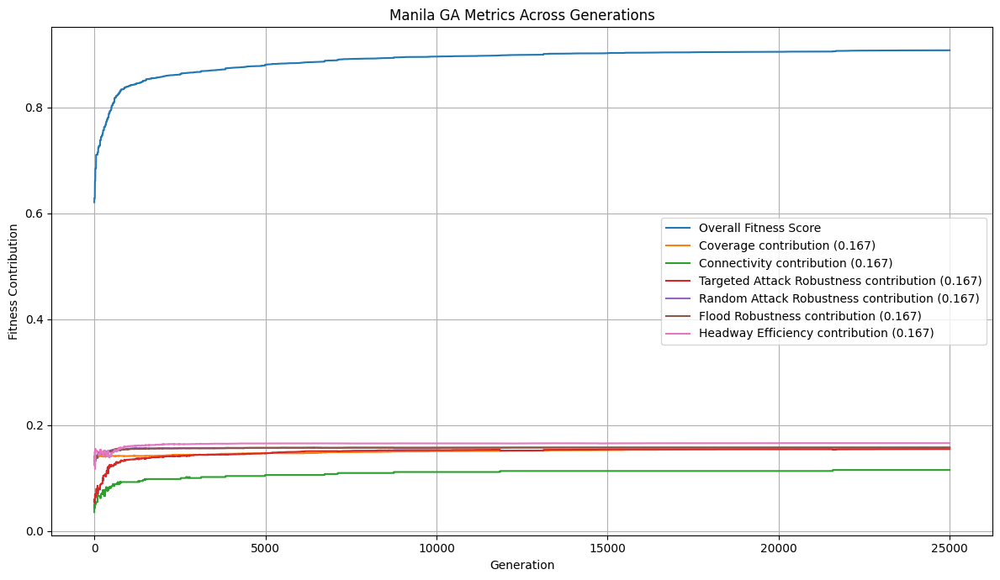

In [122]:
plot_ga_run_all_metrics_save(
    max_score_list,
    w_cov,
    w_conn,
    w_target,
    w_random,
    w_flood,
    w_headway,
    "Manila GA Metrics Across Generations",
    (
        f"{generation_png_location}"
        f"Manila_GA_Generations_"
        f"{run_tag}_S{SEED}.png"
    )
)

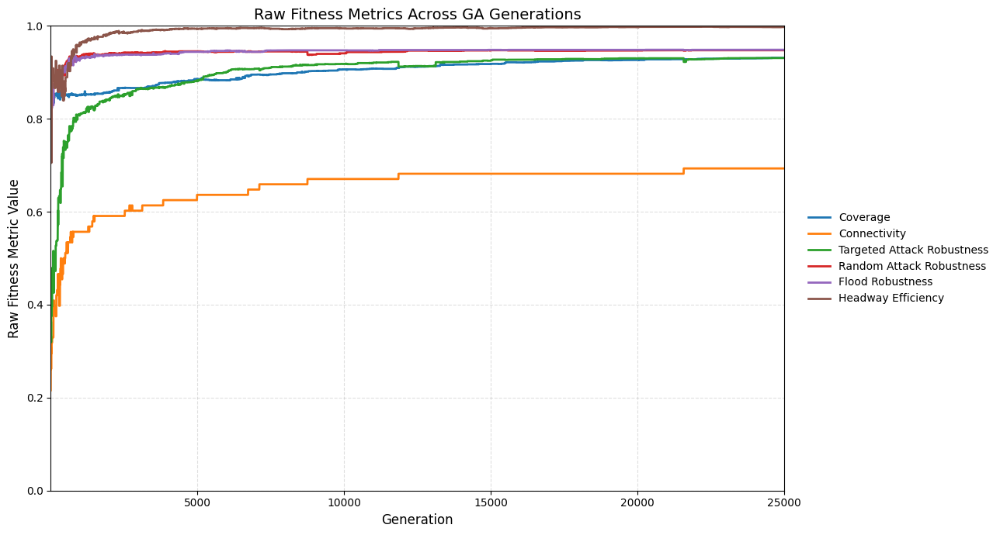


=== RAW METRIC CHANGES ===


,Initial,Final,Change
Coverage,0.8347,0.9311,0.0965
Connectivity,0.2159,0.6932,0.4773
Targeted Attack Robustness,0.3288,0.9308,0.6019
Random Attack Robustness,0.7631,0.9475,0.1843
Flood Robustness,0.7983,0.9486,0.1503
Headway Efficiency,0.7857,0.9975,0.2118


In [ ]:
# =========================================================
# GENERATE GRAPH
# =========================================================

generation_png_location = (
    "GA Generation Graphs/Manila/"
)

raw_metrics_df = plot_ga_raw_fitness_metrics(
    max_score_list=max_score_list,
    title="Raw Fitness Metrics Across GA Generations",
    output_file=(
        f"{generation_png_location}"
        f"Manila_GA_Raw_Metrics_"
        f"{run_tag}_S{SEED}.png"
    )
)

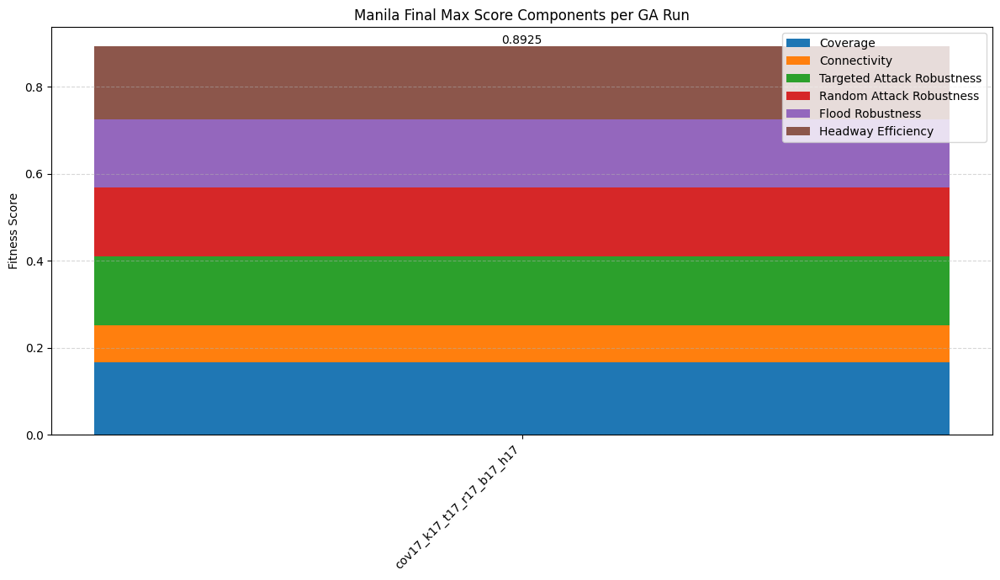

In [73]:
run_series = [
    {
        "label": run_tag,
        "max_score_list": max_score_list
    }
]

plot_ga_run_stacked_max_scores(
    run_series,
    "Manila Final Max Score Components per GA Run",
    f"{generation_png_location}Manila_GA_Stacked_Max_Scores_{run_tag}_S{SEED}.png"
)

In [75]:
colors = [
    "Red", "Green", "Blue", "Orange", "Purple", "Cyan", "Magenta", "Maroon",
    "Olive", "Lime", "Teal", "Navy", "Aqua", "Fuchsia", "Coral", "Indigo",
    "Violet", "Brown", "DarkGreen", "DarkBlue", "DarkRed", "DarkCyan",
    "DarkMagenta", "DarkOrange", "DarkViolet", "DarkTurquoise", "DarkSlateGray",
    "SaddleBrown", "SeaGreen", "MidnightBlue", "ForestGreen", "Sienna",
    "SteelBlue", "RoyalBlue", "SlateBlue", "MediumSeaGreen", "MediumSlateBlue",
    "MediumPurple", "MediumTurquoise", "Crimson", "Goldenrod", "Chocolate",
    "FireBrick", "Peru", "RosyBrown", "IndianRed", "SlateGray", "DodgerBlue",
    "LightSeaGreen", "MediumAquamarine", "CadetBlue", "Turquoise"
] 

map_center = (14.599512, 120.984222)
m1 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap') # "tiles='CartoDB Positron'" for black and white background
m2 = folium.Map(location=map_center, zoom_start=10, tiles='openstreetmap')

for route in population[0].routes:
    chosen_color = random.choice(colors)
    improved_route_plot(graph_of_stops_Manila, route, chosen_color, m1, route.route_id)
    
    index = population[0].routes.index(route)
    reversed_route = population[0].reversed_routes[index]
    if reversed_route != None:
        improved_route_plot(graph_of_stops_Manila, reversed_route, chosen_color, m2, reversed_route.route_id)

m1.save(f"{map_html_location}Manila_GA_Map_{run_tag}_S{SEED}.html")
m2.save(f"{map_html_location}Manila_GA_Map_Reverse_{run_tag}_S{SEED}.html")

#### Visualization of Transpo Stops in GA Results

In [ ]:
stops_map = plot_stops_on_map_graph(population[0].graph)
stops_map.save(f"{map_html_location}Manila_Stops_{run_tag}_S{SEED}.html") # Save the map to an HTML file

#### Export to CSV

In [ ]:
import csv

csv_path = f"{map_html_location}Manila_routes_{run_tag}_S{SEED}.csv"
with open(csv_path, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['lat', 'long', 'route id'])
    
    for route in population[0].routes:
        for connection in route.route:
            if route.route.index(connection) == 0:
                lat = graph_of_stops_Manila.nodes[connection[0]]['y']
                long = graph_of_stops_Manila.nodes[connection[0]]['x']
                writer.writerow([lat, long, route.route_id])
            
            lat = graph_of_stops_Manila.nodes[connection[-1]]['y']
            long = graph_of_stops_Manila.nodes[connection[-1]]['x']
            writer.writerow([lat, long, route.route_id])

print("Data exported successfully.")

#### Summarized Metrics

In [ ]:
import networkx as nx
import numpy as np

def get_unique_route_stops(route_obj):
    stops = []
    for i, connection in enumerate(route_obj.route):
        if i == 0:
            stops.append(connection[0])
        stops.append(connection[-1])
    return stops

def get_route_stop_count(route_obj):
    return len(get_unique_route_stops(route_obj))

def get_route_lengths_km(network_obj):
    return [route.length for route in network_obj.routes if route is not None]

def average_degree(graph):
    degs = [d for _, d in graph.degree()]
    return sum(degs) / len(degs) if degs else 0

def graph_with_distance_weights(network_obj):
    G = nx.Graph()
    for u, v, data in network_obj.graph.edges(data=True):
        dist = data.get("distance", 1.0)
        if G.has_edge(u, v):
            if dist < G[u][v]["weight"]:
                G[u][v]["weight"] = dist
        else:
            G.add_edge(u, v, weight=dist)
    return G

def weighted_network_diameter_km(network_obj):
    G = graph_with_distance_weights(network_obj)
    if len(G) == 0:
        return 0
    if not nx.is_connected(G):
        largest_cc = max(nx.connected_components(G), key=len)
        G = G.subgraph(largest_cc).copy()
    lengths = dict(nx.all_pairs_dijkstra_path_length(G, weight="weight"))
    return max(max(d.values()) for d in lengths.values())

def avg_betweenness_centrality(network_obj):
    G = nx.Graph(network_obj.graph)
    if len(G) == 0:
        return 0
    bc = nx.betweenness_centrality(G, normalized=True)
    return sum(bc.values()) / len(bc) if bc else 0

def avg_closeness_centrality(network_obj):
    G = nx.Graph(network_obj.graph)
    if len(G) == 0:
        return 0
    cc = nx.closeness_centrality(G)
    return sum(cc.values()) / len(cc) if cc else 0

def summarize_network(network_obj):
    comp = network_obj.fitness_score_components
    route_lengths = get_route_lengths_km(network_obj)
    stop_counts = [get_route_stop_count(r) for r in network_obj.routes if r is not None]

    unique_stops = set()
    for r in network_obj.routes:
        if r is not None:
            unique_stops.update(get_unique_route_stops(r))

    summary = {
        "Coverage Score":
            comp["Coverage Raw"],

        "Connectivity Score":
            comp["Connectivity Raw"],

        "Targeted-Attack Robustness Score":
            comp[
                "Targeted Attack Robustness Raw"
            ],

        "Random-Attack Robustness Score":
            comp[
                "Random Attack Robustness Raw"
            ],

        "Flood Robustness Score":
            comp[
                "Flood Robustness Raw"
            ],

        "Headway Efficiency Score":
            comp[
                "Headway Efficiency Raw"
            ],

        "Average Required Jeepneys":
            comp[
                "Average Required Jeepneys"
            ],

        "Total Fitness Score":
            network_obj.fitness_score,

        "Total Network Nodes":
            comp["Total Network Nodes"],

        "TotalRoutes":
            len([
                r
                for r in network_obj.routes
                if r is not None
            ]),

        "TotalStops":
            len(unique_stops),

        "Shortest Route Length":
            min(route_lengths)
            if route_lengths
            else 0,

        "Longest Route Length":
            max(route_lengths)
            if route_lengths
            else 0,

        "Average Route Length":
            (
                sum(route_lengths)
                / len(route_lengths)
                if route_lengths
                else 0
            ),

        "Average Degree":
            average_degree(
                network_obj.graph
            ),

        "Average Number of Stops per Route":
            (
                sum(stop_counts)
                / len(stop_counts)
                if stop_counts
                else 0
            ),

        "Network Diameter":
            weighted_network_diameter_km(
                network_obj
            ),

        "Average Betweenness Centrality":
            avg_betweenness_centrality(
                network_obj
            ),

        "Average Closeness Centrality":
            avg_closeness_centrality(
                network_obj
            ),

        "K_r":
            comp["K_r"],

        "r_tau":
            comp["r_tau"],

        "R_G":
            comp["R_G"],

        "Intermodal Threshold":
            comp["tau"],

        "Headway Baseline Mean":
            comp["Headway Baseline Mean"],

        "Headway Baseline Std":
            comp["Headway Baseline Std"]
    }
    return summary

In [ ]:
best_network = population[0]
optimized_summary = summarize_network(best_network)

for k, v in optimized_summary.items():
    if isinstance(v, float):
        if "Length" in k or "Diameter" in k:
            print(f"{k}: {v:.4f} km")
        else:
            print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")

In [ ]:
metric_ranges = metric_ranges_for_network()

print("\n--- Possible Metric Ranges for Final GA Network ---")
for metric, (low, high) in metric_ranges.items():
    print(f"{metric}: {low:.4f} to {high:.4f}")